# Pred — `nyc_rent_panel.csv`

One row = **one StreetEasy neighborhood in one month**. 176 neighborhoods × 201 months (2010-01 → 2026-09) = 35,376 rows × 49 columns.
Built by `nyc_rent_exploration.ipynb` (Part D). No target columns yet — every column uses only data up to that month.

In [1]:
import pandas as pd
PANEL_URL = "https://raw.githubusercontent.com/AmirGoldstein/nyc-rent-data/refs/heads/main/nyc_rent_panel.csv"
df = pd.read_csv(PANEL_URL, parse_dates=["date"])
print(df.shape)
df.head()

(35376, 49)


,areaName,Borough,date,merge_group,shares_nta,area_km2,med_inventory,in_model,rent,inventory,...,rent_2br,inventory_2br,rent_3m_2br,past_12m_2br,in_model_2br,rent_3br,inventory_3br,rent_3m_3br,past_12m_3br,in_model_3br
0,Astoria,Queens,2010-01-01,Astoria,0,10.825086,1306.0,1,1600.0,99.0,...,1700.0,33.0,NaN,NaN,1,2000.0,12.0,NaN,NaN,1
1,Astoria,Queens,2010-02-01,Astoria,0,10.825086,1306.0,1,1650.0,98.0,...,1800.0,35.0,NaN,NaN,1,2100.0,13.0,NaN,NaN,1
2,Astoria,Queens,2010-03-01,Astoria,0,10.825086,1306.0,1,1600.0,106.0,...,1800.0,34.0,1766.666667,NaN,1,2000.0,16.0,2033.333333,NaN,1
3,Astoria,Queens,2010-04-01,Astoria,0,10.825086,1306.0,1,1600.0,78.0,...,1800.0,25.0,1800.000000,NaN,1,2000.0,13.0,2033.333333,NaN,1
4,Astoria,Queens,2010-05-01,Astoria,0,10.825086,1306.0,1,1662.0,57.0,...,1939.0,22.0,1846.333333,NaN,1,1900.0,12.0,1966.666667,NaN,1


## Columns

| Group | Column | Meaning |
|---|---|---|
| Keys | `areaName`, `Borough`, `date` | StreetEasy neighborhood, borough, month (1st of month) |
| Mapping | `merge_group` | Neighborhoods that share an official NTA and could be merged later |
| | `shares_nta` | 1 = shares an NTA with another neighborhood (merge candidate), 0 = clean link |
| | `area_km2` | Area of the NTA(s) the neighborhood maps to |
| Filter | `med_inventory` | Median monthly rental listings since 2015 |
| | `in_model` | 1 if `med_inventory` ≥ 20 (100 neighborhoods) — smaller ones are too noisy |
| StreetEasy | `rent` | Median asking rent ($/month) |
| | `inventory` | Number of rental listings |
| | `rent_cut_share` | Share of rental listings with a price cut |
| | `sale_price` | Median asking sale price ($) |
| | `sale_cut_share` | Share of sale listings with a price cut |
| StreetEasy, derived | `rent_3m` | 3-month rolling mean of `rent` |
| | `past_12m` | % change in `rent_3m` over the last 12 months |
| | `inventory_yoy`, `sale_price_yoy` | % change vs. 12 months earlier |
| | `price_to_rent` | `sale_price` / (12 × `rent`) — years of rent to buy |
| City (monthly counts) | `new_units` | Units in new buildings completed that month (Housing Database) |
| | `net_units` | Net change in units: new + alterations − demolitions |
| | `pipeline_units` | Units permitted but not yet completed, as of that month |
| | `evictions` | Residential evictions executed that month (from 2017) |
| | `subway_complexes` | Subway station complexes in the area (static) |
| City (density) | `new_units_12m_km2` | New units completed in the last 12 months, per km² |
| | `pipeline_km2`, `subway_km2` | Pipeline units / stations per km² |
| | `evictions_12m_km2` | Evictions in the last 12 months per km² (from 2017-12) |
| Flags | `covid_period` | 1 for 2020-03 → 2021-06 |
| | `eviction_moratorium` | 1 for 2020-03 → 2022-01 |
| By bedrooms (`{size}` = `studio`, `1br`, `2br`, `3br` = 3+) | `rent_{size}` | Median asking rent for that size |
| | `inventory_{size}` | Number of rental listings of that size |
| | `rent_3m_{size}` | 3-month rolling mean of `rent_{size}` |
| | `past_12m_{size}` | % change in `rent_3m_{size}` over the last 12 months |
| | `in_model_{size}` | 1 if median monthly listings of that size since 2015 ≥ 20 (studio 42, 1br 77, 2br 75, 3br 51 of the 100) |

## Things to know
- **Missing ≠ zero.** `rent` is empty when a neighborhood had no listings that month; `evictions` is empty before 2017.
- **Neighborhoods sharing an NTA** (`shares_nta = 1`) get identical city features — the data is only available for the whole NTA.
- **Use `in_model == 1`** for analysis; the rest are kept so thresholds can change later.
- **By bedrooms:** use `in_model_{size}` for size-level work; a neighborhood can be reliable overall but thin for one size.

In [2]:
model = df[df.in_model == 1]
print(model.areaName.nunique(), "neighborhoods |", model.date.min().date(), "->", model.date.max().date())
model.drop_duplicates("areaName").Borough.value_counts()

100 neighborhoods | 2010-01-01 -> 2026-09-01


Borough
Brooklyn     40
Manhattan    30
Queens       21
Bronx         9
Name: count, dtype: int64

In [3]:
df.isna().mean().round(3).rename("share_missing").to_frame().T

,areaName,Borough,date,merge_group,shares_nta,area_km2,med_inventory,in_model,rent,inventory,...,rent_2br,inventory_2br,rent_3m_2br,past_12m_2br,in_model_2br,rent_3br,inventory_3br,rent_3m_3br,past_12m_3br,in_model_3br
share_missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.108,0.0,...,0.221,0.0,0.295,0.396,0.0,0.223,0.0,0.306,0.419,0.0


In [4]:
model.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
date,20100,2018-05-01 22:05:22.388059,2010-01-01 00:00:00,2014-03-01 00:00:00,2018-05-01 00:00:00,2022-07-01 00:00:00,2026-09-01 00:00:00,NaN
shares_nta,20100.0,0.32,0.0,0.0,0.0,1.0,1.0,0.466488
area_km2,20100.0,3.553731,0.517986,1.600003,2.627066,4.821971,16.742078,2.737605
med_inventory,20100.0,336.45,23.0,61.0,142.5,322.0,2651.0,492.821987
in_model,20100.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
rent,19931.0,2817.875521,550.0,1950.0,2500.0,3345.0,15000.0,1278.088134
inventory,20100.0,308.40199,0.0,40.0,112.0,307.0,6110.0,532.683702
rent_cut_share,19931.0,0.136275,0.0,0.0824,0.128205,0.179712,1.0,0.087951
sale_price,19827.0,1075647.161396,64999.5,485000.0,849000.0,1349000.0,19500000.0,899282.416083
sale_cut_share,19827.0,0.086176,0.0,0.045455,0.081272,0.117647,1.0,0.066286


In [5]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import mean_absolute_error, roc_auc_score
from sklearn.model_selection import KFold

%matplotlib inline
sns.set(style="ticks", palette="Set2")
warnings.filterwarnings("ignore")

d = df[df.in_model == 1].sort_values(["areaName", "date"]).reset_index(drop=True)
print(d.shape)

(20100, 49)


## Features

In [6]:
def add_features(d):
    def lag(col, k):
        return d.groupby("areaName")[col].shift(k)

    def vs_city(s):
        return s - s.groupby(d.date).transform("median")

    d["log_rent"] = np.log(d.rent_3m)
    d["log_inv"] = np.log1p(d.inventory)
    d["log_sale"] = np.log(d.sale_price)
    d["month"] = d.date.dt.month
    d["mom3"] = d.log_rent - lag("log_rent", 3)
    d["mom6"] = d.log_rent - lag("log_rent", 6)
    d["past_rel12"] = vs_city(d.log_rent - lag("log_rent", 12))
    d["cut_chg12"] = d.rent_cut_share - lag("rent_cut_share", 12)
    d["cut_vs_city"] = vs_city(d.rent_cut_share)
    d["cut_lag11"] = lag("rent_cut_share", 11)
    d["inv_lag11"] = lag("log_inv", 11)
    d["rent_vs_boro"] = d.log_rent - d.groupby(["Borough", "date"]).log_rent.transform("median")
    d[["boro_Bronx", "boro_Brooklyn", "boro_Manhattan", "boro_Queens"]] = pd.get_dummies(d.Borough, prefix="boro", dtype=int)
    return d.replace([np.inf, -np.inf], np.nan)

d = add_features(d)

## Targets and baselines

| target | what | baseline |
|---|---|---|
| `t_rel12` | 12m log rent growth vs city | 0 (= like the city) |
| `t_chg3` | 3m log rent change | same 3m change last year |
| `t_fair` | log rent level from fundamentals only | borough median that month |
| `t_cut1` | price-cut share next month | this month |
| `t_inv1` | log inventory next month | this month |
| `t_drop12` | rent lower in 12m (0/1) | base rate (AUC 0.5) |

In [7]:
def add_targets(d):
    def lag(col, k):
        return d.groupby("areaName")[col].shift(k)

    def fwd(col, k):
        return d.groupby("areaName")[col].shift(-k)

    chg12 = fwd("log_rent", 12) - d.log_rent
    d["t_rel12"] = chg12 - chg12.groupby(d.date).transform("median")
    d["t_chg3"] = fwd("log_rent", 3) - d.log_rent
    d["t_fair"] = d.log_rent
    d["t_cut1"] = fwd("rent_cut_share", 1)
    d["t_inv1"] = fwd("log_inv", 1)
    d["t_drop12"] = (chg12 < 0).astype(float).where(chg12.notna())

    d["b_rel12"] = 0.0
    d["b_chg3"] = lag("log_rent", 9) - lag("log_rent", 12)
    d["b_fair"] = d.groupby(["Borough", "date"]).log_rent.transform("median")
    d["b_cut1"] = d.rent_cut_share
    d["b_inv1"] = d.log_inv
    return d

d = add_targets(d)
d[[c for c in d.columns if c.startswith("t_")]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
t_rel12,18431.0,0.003,0.093,-0.735,-0.042,0.000,0.046,0.695
t_chg3,19305.0,0.010,0.075,-0.702,-0.026,0.009,0.046,0.704
t_fair,19659.0,7.863,0.394,6.745,7.571,7.837,8.111,9.582
t_cut1,19835.0,0.136,0.088,0.000,0.083,0.129,0.180,1.000
t_inv1,20000.0,4.709,1.531,0.000,3.714,4.736,5.733,8.718
t_drop12,18431.0,0.309,0.462,0.000,0.000,0.000,1.000,1.000


In [8]:
MARKET = ["past_12m", "past_rel12", "mom3", "mom6", "rent_cut_share", "cut_chg12", "cut_vs_city",
          "cut_lag11", "inventory_yoy", "log_inv", "inv_lag11", "sale_price_yoy", "price_to_rent",
          "rent_vs_boro", "month"]
CITY = ["new_units_12m_km2", "pipeline_km2", "subway_km2"]
BORO = ["boro_Bronx", "boro_Brooklyn", "boro_Manhattan", "boro_Queens"]
FAIR = ["log_sale", "subway_km2", "pipeline_km2", "new_units_12m_km2", "area_km2"] + BORO

TARGETS = {
    "t_rel12": (12, MARKET + CITY + BORO, "b_rel12", "reg"),
    "t_chg3": (3, MARKET + CITY + BORO, "b_chg3", "reg"),
    "t_fair": (0, FAIR, "b_fair", "reg"),
    "t_cut1": (1, MARKET + BORO, "b_cut1", "reg"),
    "t_inv1": (1, MARKET + BORO, "b_inv1", "reg"),
    "t_drop12": (12, MARKET + CITY + BORO, None, "clf"),
}

START = pd.Timestamp("2015-01-01")
TEST_START = pd.Timestamp("2024-01-01")
YEARS = [2019, 2020, 2021, 2022]

## CV helpers

Expanding window: for each validation year, train only on months whose target ends before that year starts.

In [9]:
def folds(data, h, years=YEARS, window=None):
    out = []
    for y in years:
        start = pd.Timestamp(f"{y}-01-01")
        keep = data.date < start - pd.DateOffset(months=h)
        if window:
            keep &= data.date >= start - pd.DateOffset(months=h + 12 * window)
        tr = np.where(keep)[0]
        va = np.where(data.date.dt.year == y)[0]
        out.append((y, tr, va))
    return out

def models(kind):
    if kind == "reg":
        return {"ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10)),
                "hgb": HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=13)}
    return {"logit": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=1000)),
            "hgb": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=13)}

def fit_predict(m, X_tr, y_tr, X_va, kind):
    if kind == "reg":
        return m.fit(X_tr, y_tr).predict(X_va)
    return m.fit(X_tr, y_tr.astype(int)).predict_proba(X_va)[:, 1]

def month_rank(dates, y, p):
    t = pd.DataFrame({"date": dates.values, "y": np.asarray(y), "p": np.asarray(p)})
    return np.nanmean([spearmanr(g.y, g.p)[0] for _, g in t.groupby("date") if g.p.nunique() > 1] or [np.nan])

def dev_data(target, h, frame=None):
    f = d if frame is None else frame
    keep = (f.date >= START) & (f.date < TEST_START - pd.DateOffset(months=h)) & f[target].notna()
    return f[keep].reset_index(drop=True)

def evaluate(target, feats=None, years=YEARS, use=None, drop=(), score_on=None, window=None, frame=None):
    h, all_feats, base, kind = TARGETS[target]
    feats = feats or all_feats
    data = dev_data(target, h, frame)
    rows = []
    for y, tr, va in folds(data, h, years, window):
        if drop:
            tr = tr[~data.loc[tr, list(drop)].any(axis=1).values]
        if score_on:
            va = va[data.loc[va, score_on].values]
        if len(va) == 0:
            continue
        X_tr, X_va = data.loc[tr, feats], data.loc[va, feats]
        y_tr, y_va = data.loc[tr, target], data.loc[va, target]
        ms = models(kind)
        preds = {n: fit_predict(m, X_tr, y_tr, X_va, kind) for n, m in ms.items() if use is None or n in use}
        preds["baseline"] = data.loc[va, base].fillna(y_tr.mean()) if base else np.full(len(va), y_tr.mean())
        for name, p in preds.items():
            r = {"target": target, "year": y, "model": name, "n": len(va)}
            if kind == "reg":
                r["mae"] = mean_absolute_error(y_va, p)
                r["rank"] = month_rank(data.loc[va, "date"], y_va, p)
            else:
                r["auc"] = roc_auc_score(y_va, p) if y_va.nunique() > 1 else np.nan
            rows.append(r)
    return pd.DataFrame(rows)

def add_skill(res):
    reg = res[res.mae.notna()].copy()
    base = reg[reg.model == "baseline"].set_index(["target", "year"]).mae
    reg["skill"] = 1 - reg.mae / base.reindex(list(zip(reg.target, reg.year))).values
    return reg

## A. Predictability scan

`skill` = 1 − MAE / baseline MAE (above 0 = beats baseline). `rank` = mean monthly Spearman between prediction and truth.

In [10]:
res = pd.concat([evaluate(t) for t in TARGETS], ignore_index=True)
reg = add_skill(res)

summary = reg.groupby(["target", "model"])[["mae", "skill", "rank"]].agg(["mean", "std"]).round(3)
summary

mae         skill          rank       
                   mean    std   mean    std   mean    std
target  model                                             
t_chg3  baseline  0.069  0.021  0.000  0.000  0.000  0.160
        hgb       0.052  0.012  0.238  0.113  0.221  0.063
        ridge     0.047  0.008  0.310  0.098  0.192  0.078
t_cut1  baseline  0.047  0.007  0.000  0.000  0.537  0.085
        hgb       0.048  0.011 -0.019  0.243  0.530  0.134
        ridge     0.046  0.007  0.024  0.099  0.560  0.137
t_fair  baseline  0.178  0.020  0.000  0.000  0.690  0.026
        hgb       0.096  0.041  0.470  0.157  0.957  0.004
        ridge     0.142  0.034  0.208  0.095  0.859  0.012
t_inv1  baseline  0.150  0.026  0.000  0.000  0.990  0.002
        hgb       0.153  0.036 -0.008  0.061  0.989  0.003
        ridge     0.152  0.036 -0.007  0.066  0.990  0.002
t_rel12 baseline  0.067  0.017  0.000  0.000    NaN    NaN
        hgb       0.070  0.020 -0.044  0.160  0.363  0.162
        ridge     0.066  0.021  0.026  0.110  0.361  0.234

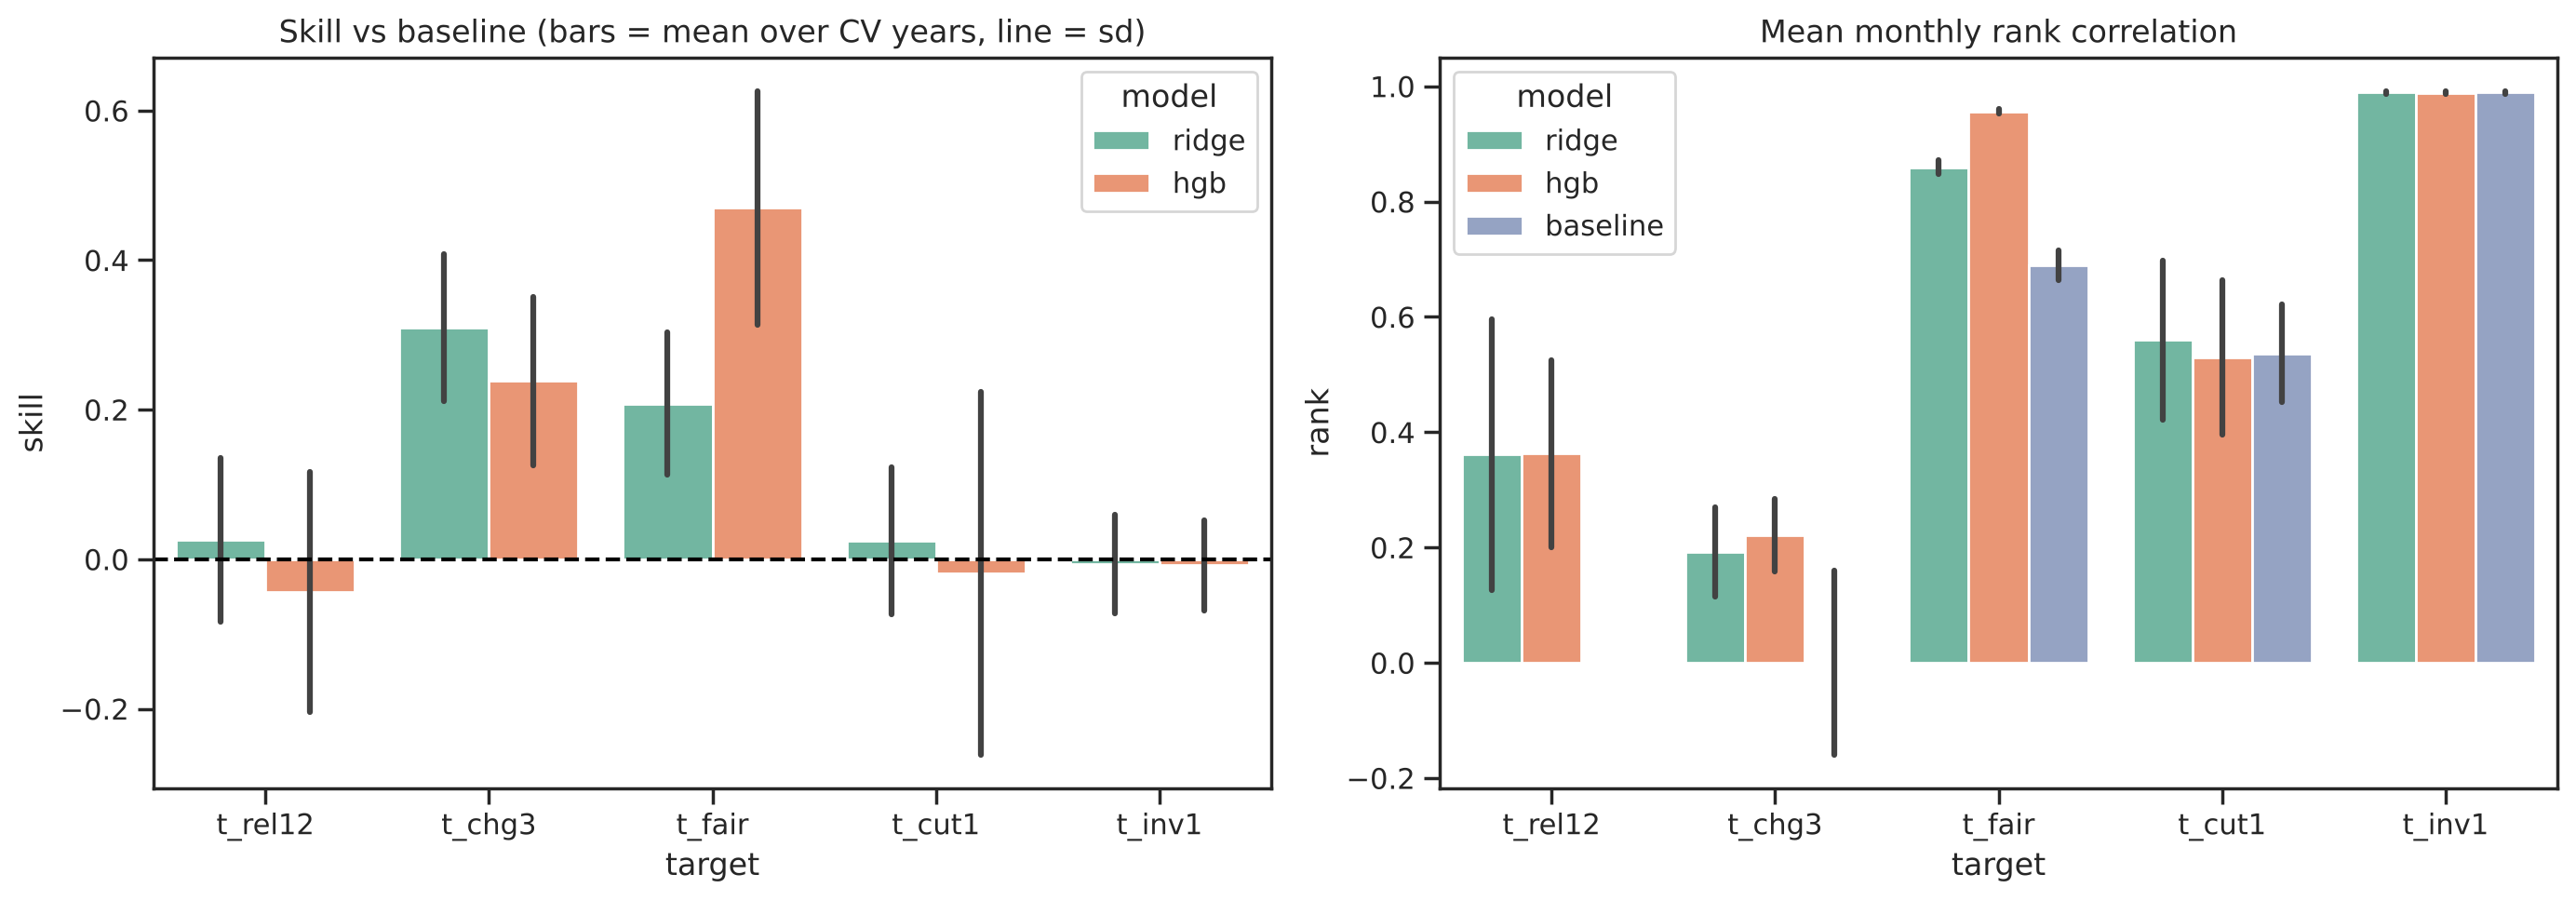

,mean,std,list
model,,,
baseline,0.500,0.000,"[0.5, 0.5, 0.5, 0.5]"
hgb,0.629,0.039,"[0.5957451537707095, 0.6697188590561589, 0.595..."
logit,0.605,0.128,"[0.6437059449487246, 0.7278861585433785, 0.425..."


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=reg[reg.model != "baseline"], x="target", y="skill", hue="model", errorbar="sd", ax=axs[0])
axs[0].axhline(0, color="k", ls="--")
axs[0].set_title("Skill vs baseline (bars = mean over CV years, line = sd)")
sns.barplot(data=reg, x="target", y="rank", hue="model", errorbar="sd", ax=axs[1])
axs[1].set_title("Mean monthly rank correlation")
plt.tight_layout()
plt.show()

res[res.target == "t_drop12"].groupby("model").auc.agg(["mean", "std", list]).round(3)

share of rows with a 12m rent drop: 0.309


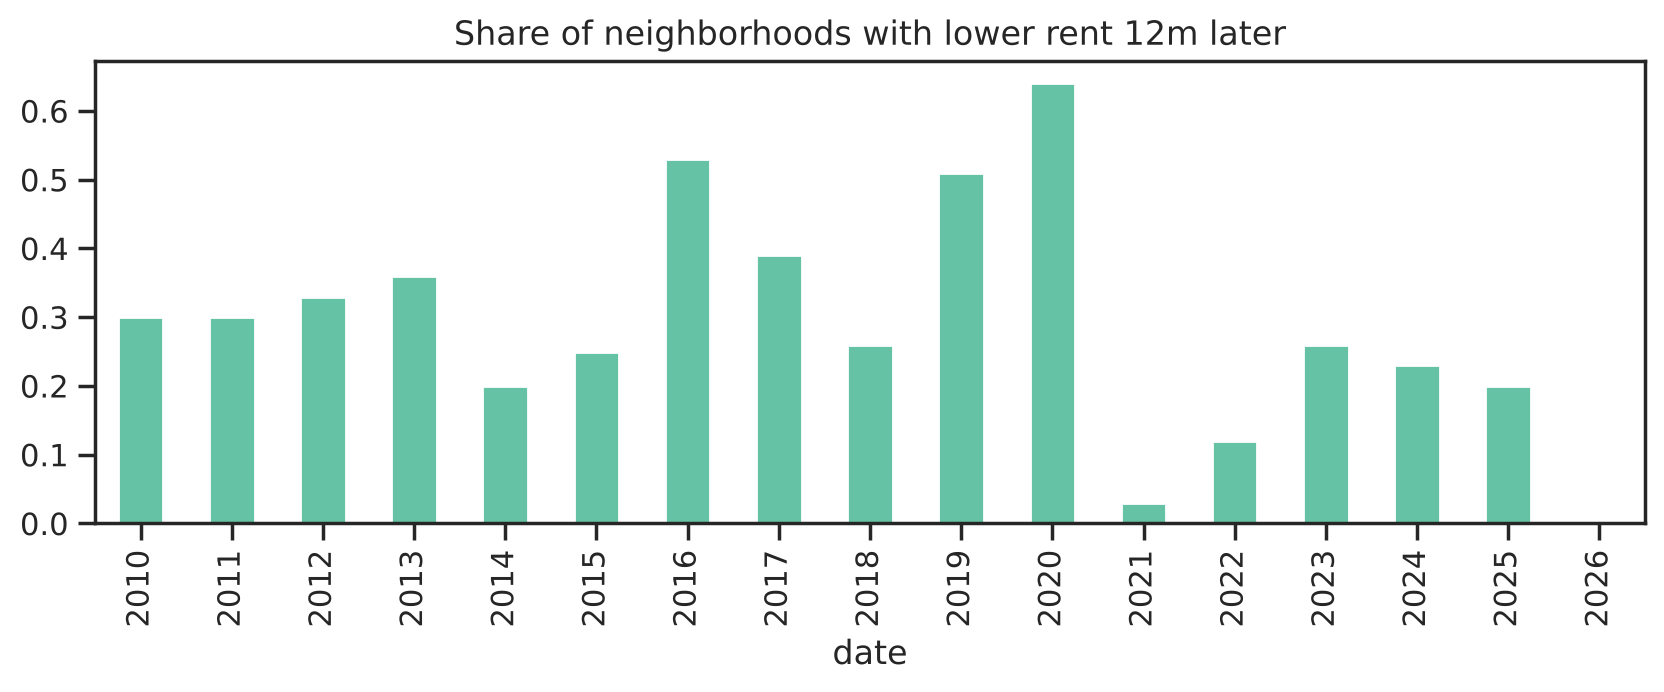

In [12]:
print("share of rows with a 12m rent drop:", d.t_drop12.mean().round(3))
d.groupby(d.date.dt.year).t_drop12.mean().round(2).plot(kind="bar", figsize=(10, 3), title="Share of neighborhoods with lower rent 12m later")
plt.show()

## B. Target decisions

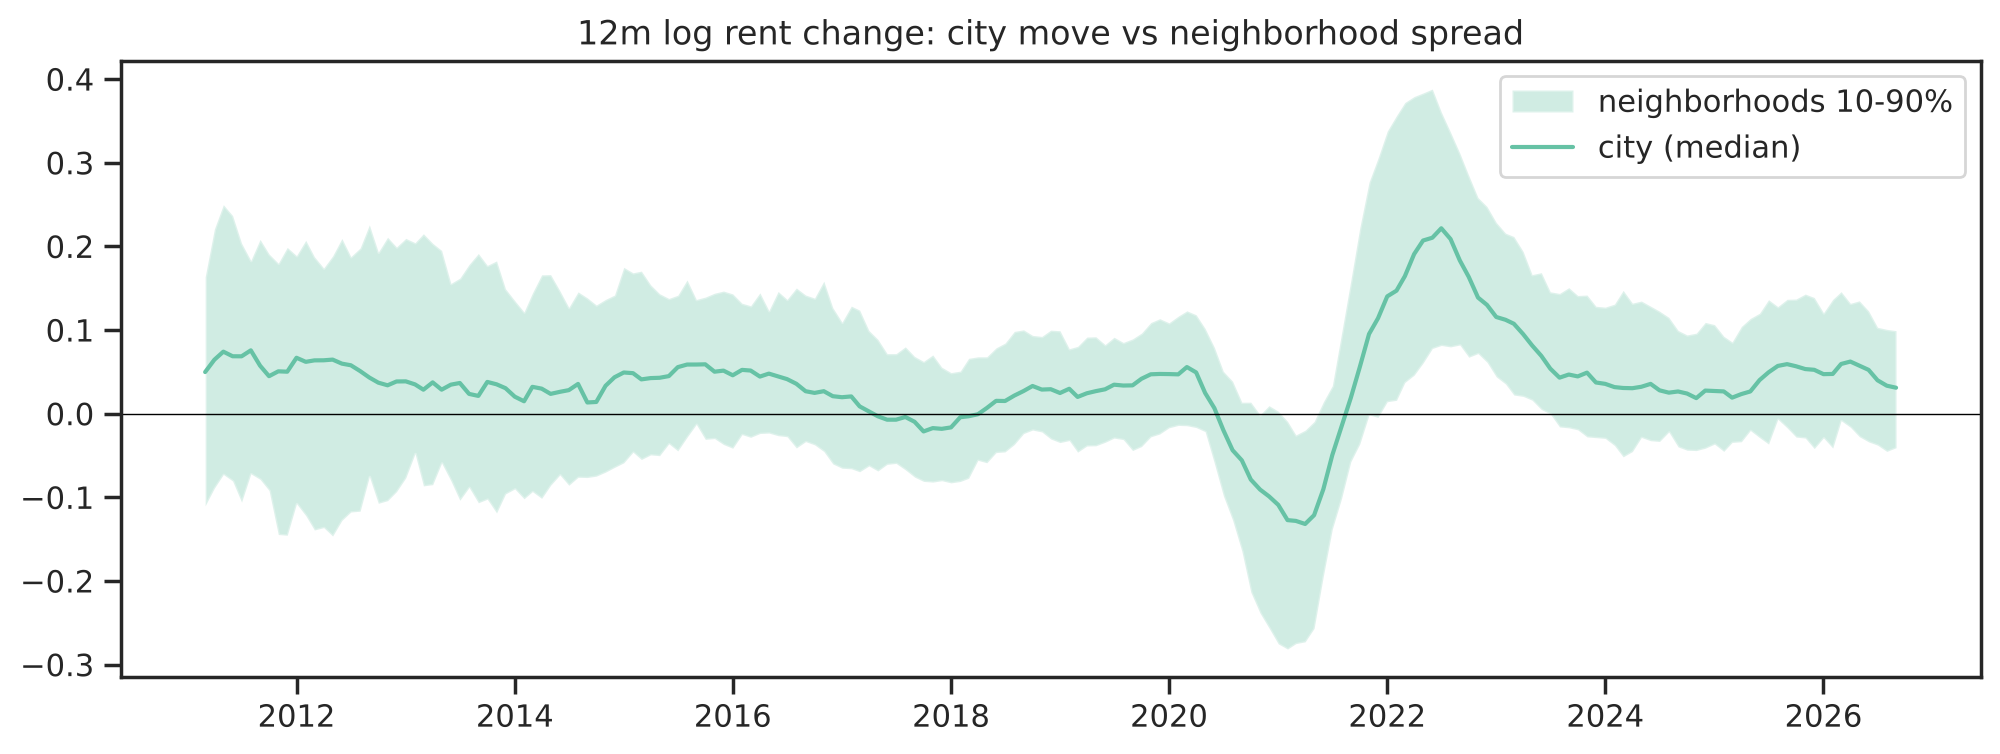

share of variance that is citywide: 0.27


In [13]:
def plot_city_vs_local():
    g = d.dropna(subset=["log_rent"]).copy()
    g["chg12"] = g.log_rent - g.groupby("areaName").log_rent.shift(12)
    q = g.groupby("date").chg12.quantile([0.1, 0.5, 0.9]).unstack()
    plt.figure(figsize=(12, 4))
    plt.fill_between(q.index, q[0.1], q[0.9], alpha=0.3, label="neighborhoods 10-90%")
    plt.plot(q.index, q[0.5], label="city (median)")
    plt.axhline(0, color="k", lw=0.5)
    plt.title("12m log rent change: city move vs neighborhood spread")
    plt.legend()
    plt.show()
    within = g.groupby("date").chg12.transform(lambda s: s - s.median()).var()
    print("share of variance that is citywide:", round(1 - within / g.chg12.var(), 2))

plot_city_vs_local()

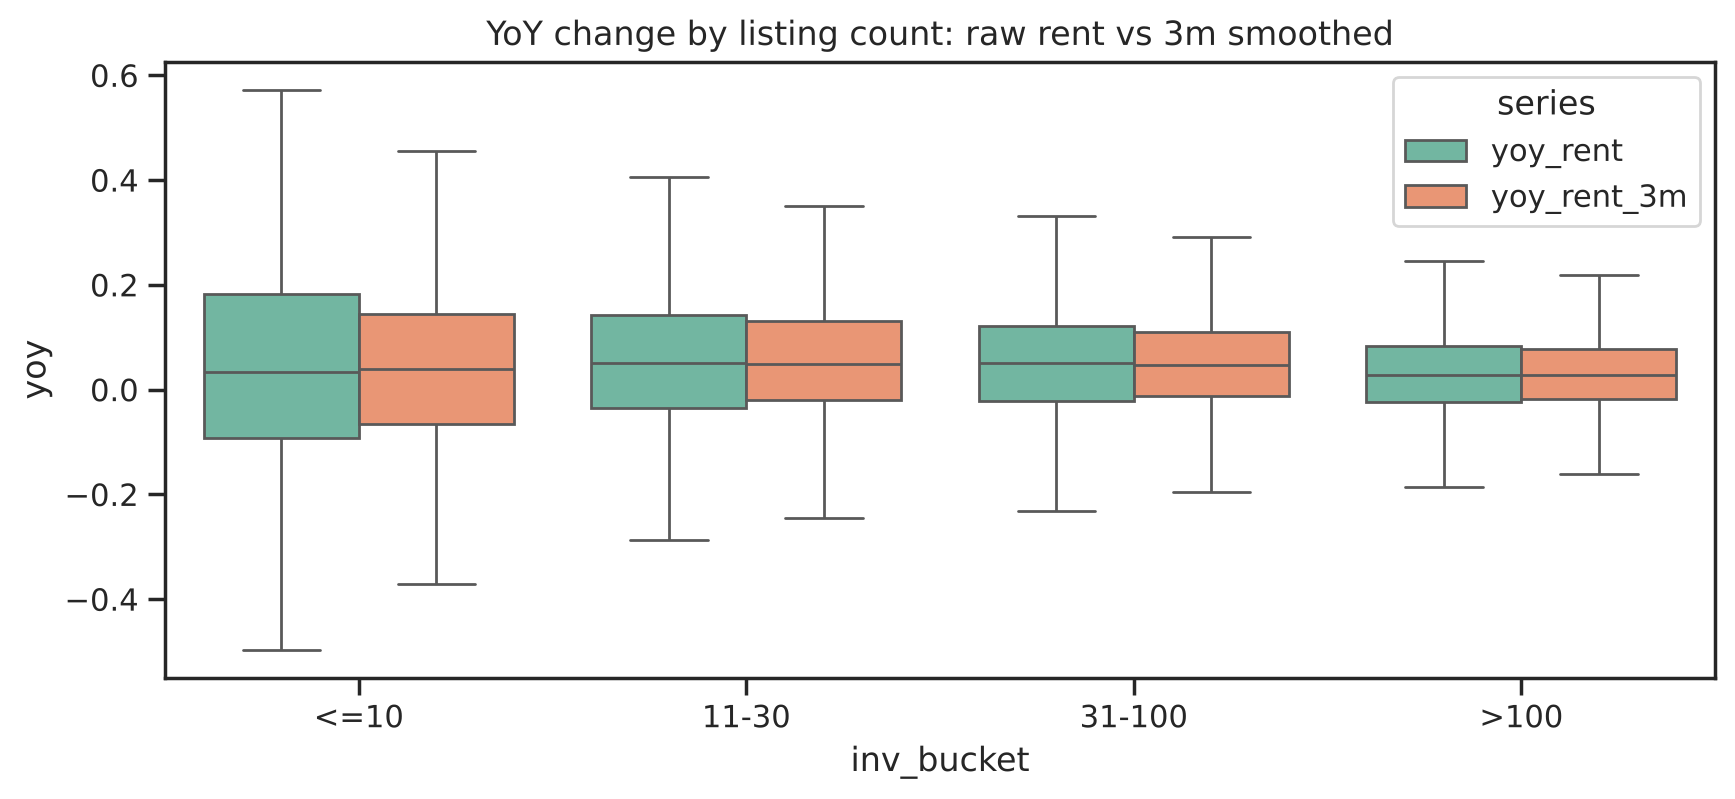

series      yoy_rent  yoy_rent_3m
inv_bucket                       
<=10           0.257        0.182
11-30          0.167        0.141
31-100         0.126        0.109
>100           0.112        0.105


In [14]:
def plot_noise_by_inventory():
    g = d[d.date < TEST_START].copy()
    g["yoy_rent"] = np.log(g.rent) - g.groupby("areaName").rent.shift(12).pipe(np.log)
    g["yoy_rent_3m"] = g.log_rent - g.groupby("areaName").log_rent.shift(12)
    g["inv_bucket"] = pd.cut(g.inventory, [-1, 10, 30, 100, np.inf], labels=["<=10", "11-30", "31-100", ">100"])
    long = g.melt(id_vars="inv_bucket", value_vars=["yoy_rent", "yoy_rent_3m"], var_name="series", value_name="yoy")
    plt.figure(figsize=(10, 4))
    sns.boxplot(data=long, x="inv_bucket", y="yoy", hue="series", showfliers=False)
    plt.title("YoY change by listing count: raw rent vs 3m smoothed")
    plt.show()
    print(long.groupby(["inv_bucket", "series"], observed=True).yoy.std().unstack().round(3))

plot_noise_by_inventory()

## C. Validation design

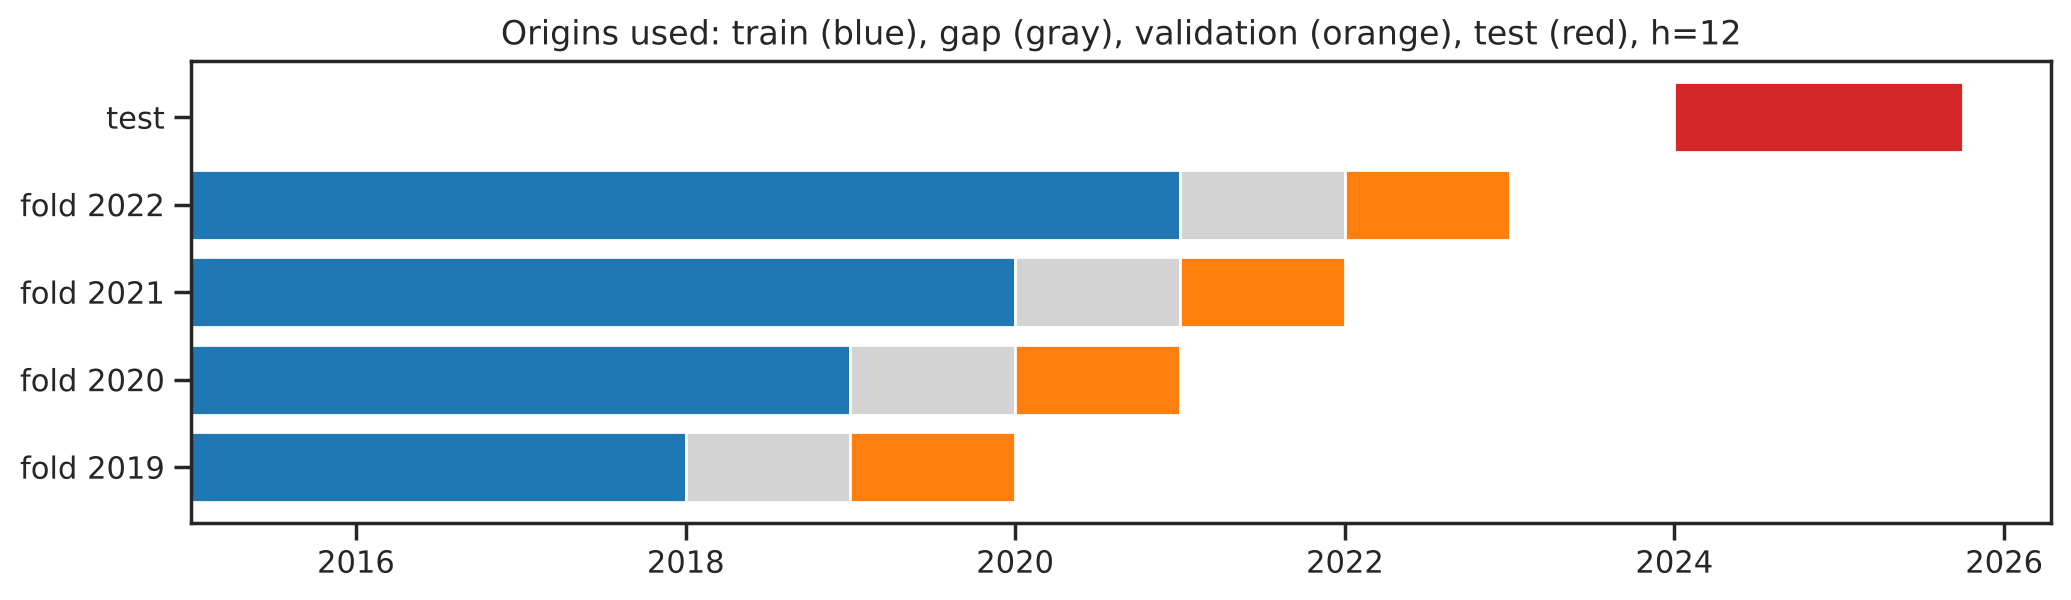

In [15]:
def plot_folds(h=12, years=YEARS):
    fig, ax = plt.subplots(figsize=(12, 3))
    for i, y in enumerate(years):
        start = pd.Timestamp(f"{y}-01-01")
        tr_end = start - pd.DateOffset(months=h)
        ax.barh(i, tr_end - START, left=START, color="tab:blue")
        ax.barh(i, start - tr_end, left=tr_end, color="lightgray")
        ax.barh(i, pd.Timedelta(days=365), left=start, color="tab:orange")
    ax.barh(len(years), pd.Timestamp("2025-10-01") - TEST_START, left=TEST_START, color="tab:red")
    ax.set_yticks(range(len(years) + 1), [f"fold {y}" for y in years] + ["test"])
    ax.set_title(f"Origins used: train (blue), gap (gray), validation (orange), test (red), h={h}")
    plt.show()

plot_folds()

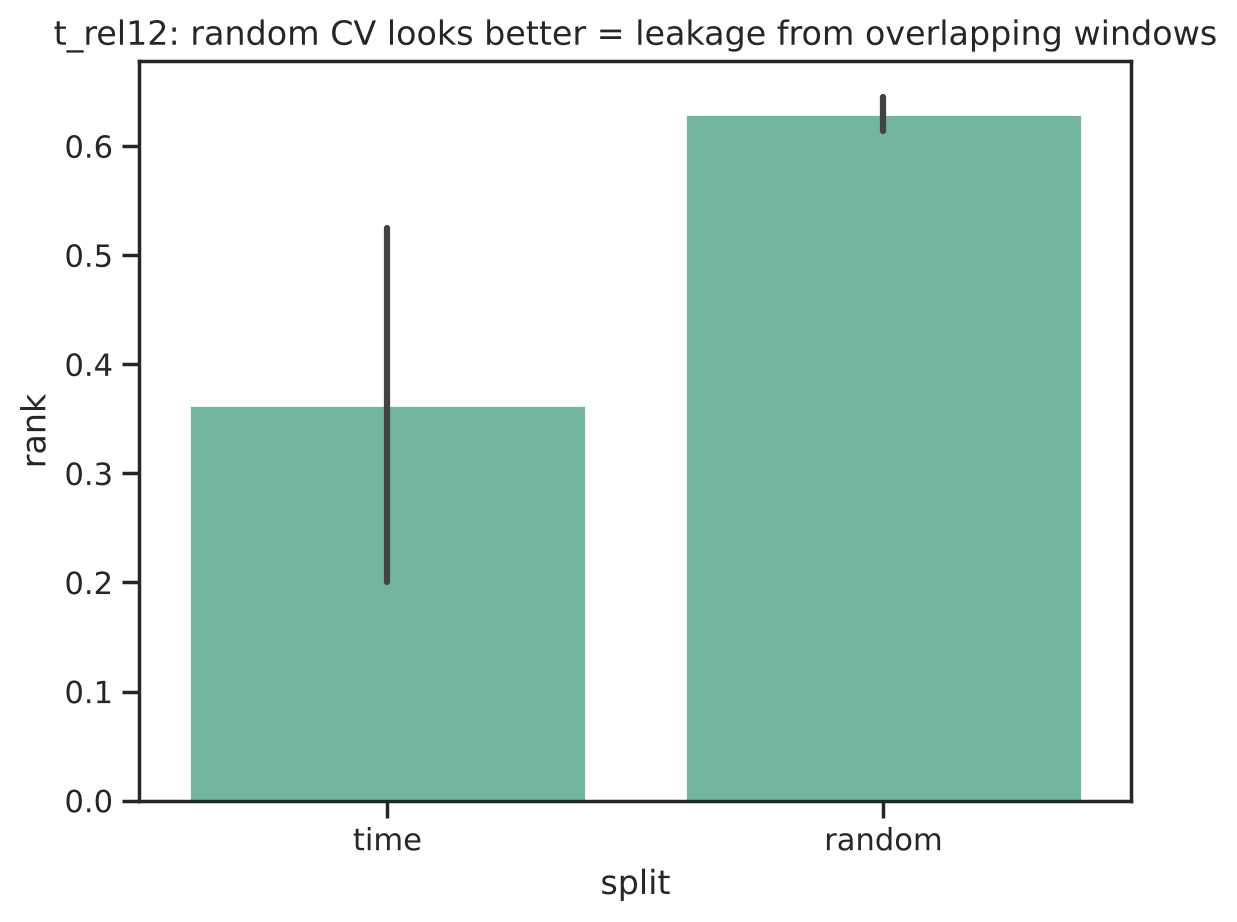

split
random    0.630
time      0.363
Name: rank, dtype: float64

In [16]:
def random_vs_time(target="t_rel12"):
    h, feats, base, kind = TARGETS[target]
    data = dev_data(target, h)
    out = []
    for name, splits in [("time", [(tr, va) for _, tr, va in folds(data, h)]),
                         ("random", list(KFold(4, shuffle=True, random_state=13).split(data)))]:
        for tr, va in splits:
            m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=13)
            p = m.fit(data.loc[tr, feats], data.loc[tr, target]).predict(data.loc[va, feats])
            out.append({"split": name, "rank": month_rank(data.loc[va, "date"], data.loc[va, target], p)})
    out = pd.DataFrame(out)
    sns.barplot(data=out, x="split", y="rank", errorbar="sd")
    plt.title(f"{target}: random CV looks better = leakage from overlapping windows")
    plt.show()
    return out.groupby("split")["rank"].mean().round(3)

random_vs_time()

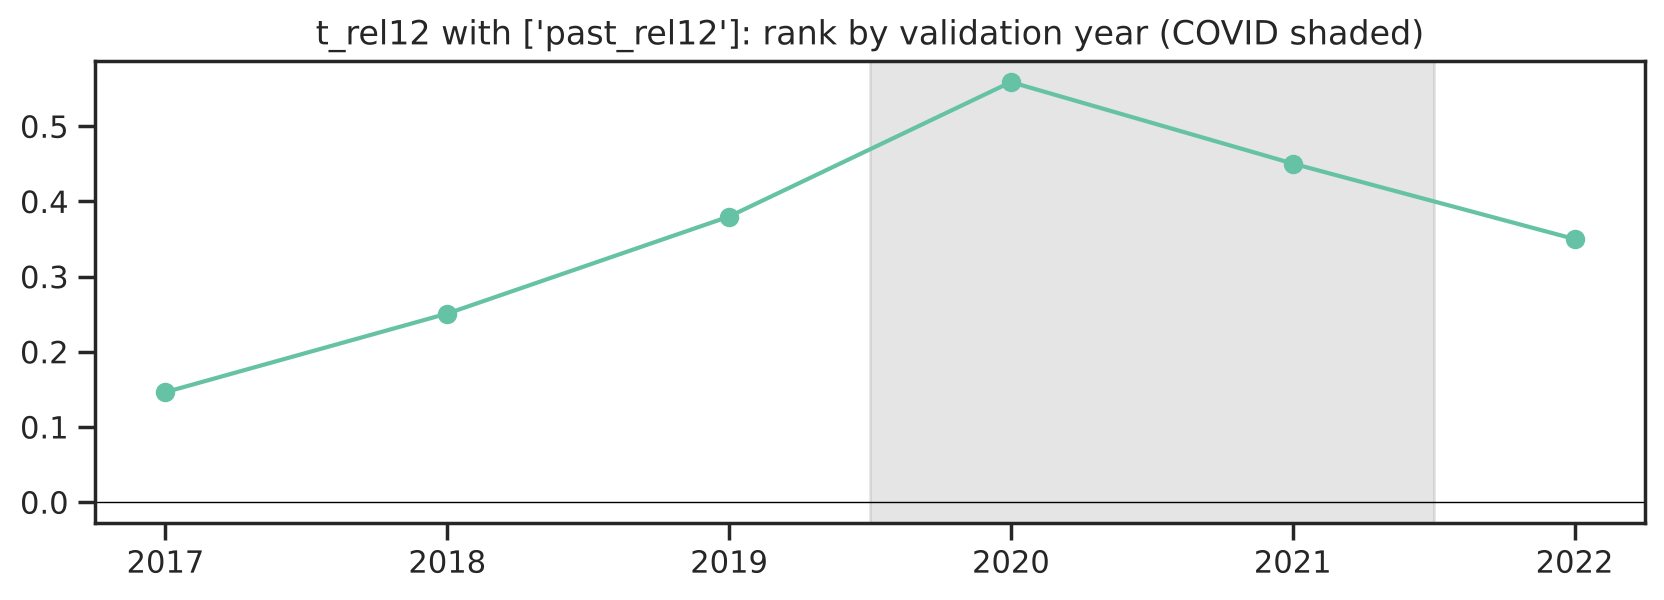

,year,rank,mae
0,2017,0.146,0.043
2,2018,0.251,0.041
4,2019,0.380,0.050
6,2020,0.559,0.067
8,2021,0.450,0.080
10,2022,0.350,0.051


In [17]:
def by_year(target, feats, years=range(2017, 2023)):
    r = evaluate(target, feats=feats, years=list(years), use=["ridge"])
    r = r[r.model == "ridge"]
    plt.figure(figsize=(10, 3))
    plt.plot(r.year, r["rank"], marker="o")
    plt.axvspan(2019.5, 2021.5, color="gray", alpha=0.2)
    plt.axhline(0, color="k", lw=0.5)
    plt.title(f"{target} with {feats}: rank by validation year (COVID shaded)")
    plt.show()
    return r[["year", "rank", "mae"]].round(3)

by_year("t_rel12", ["past_rel12"])

## D. Signals

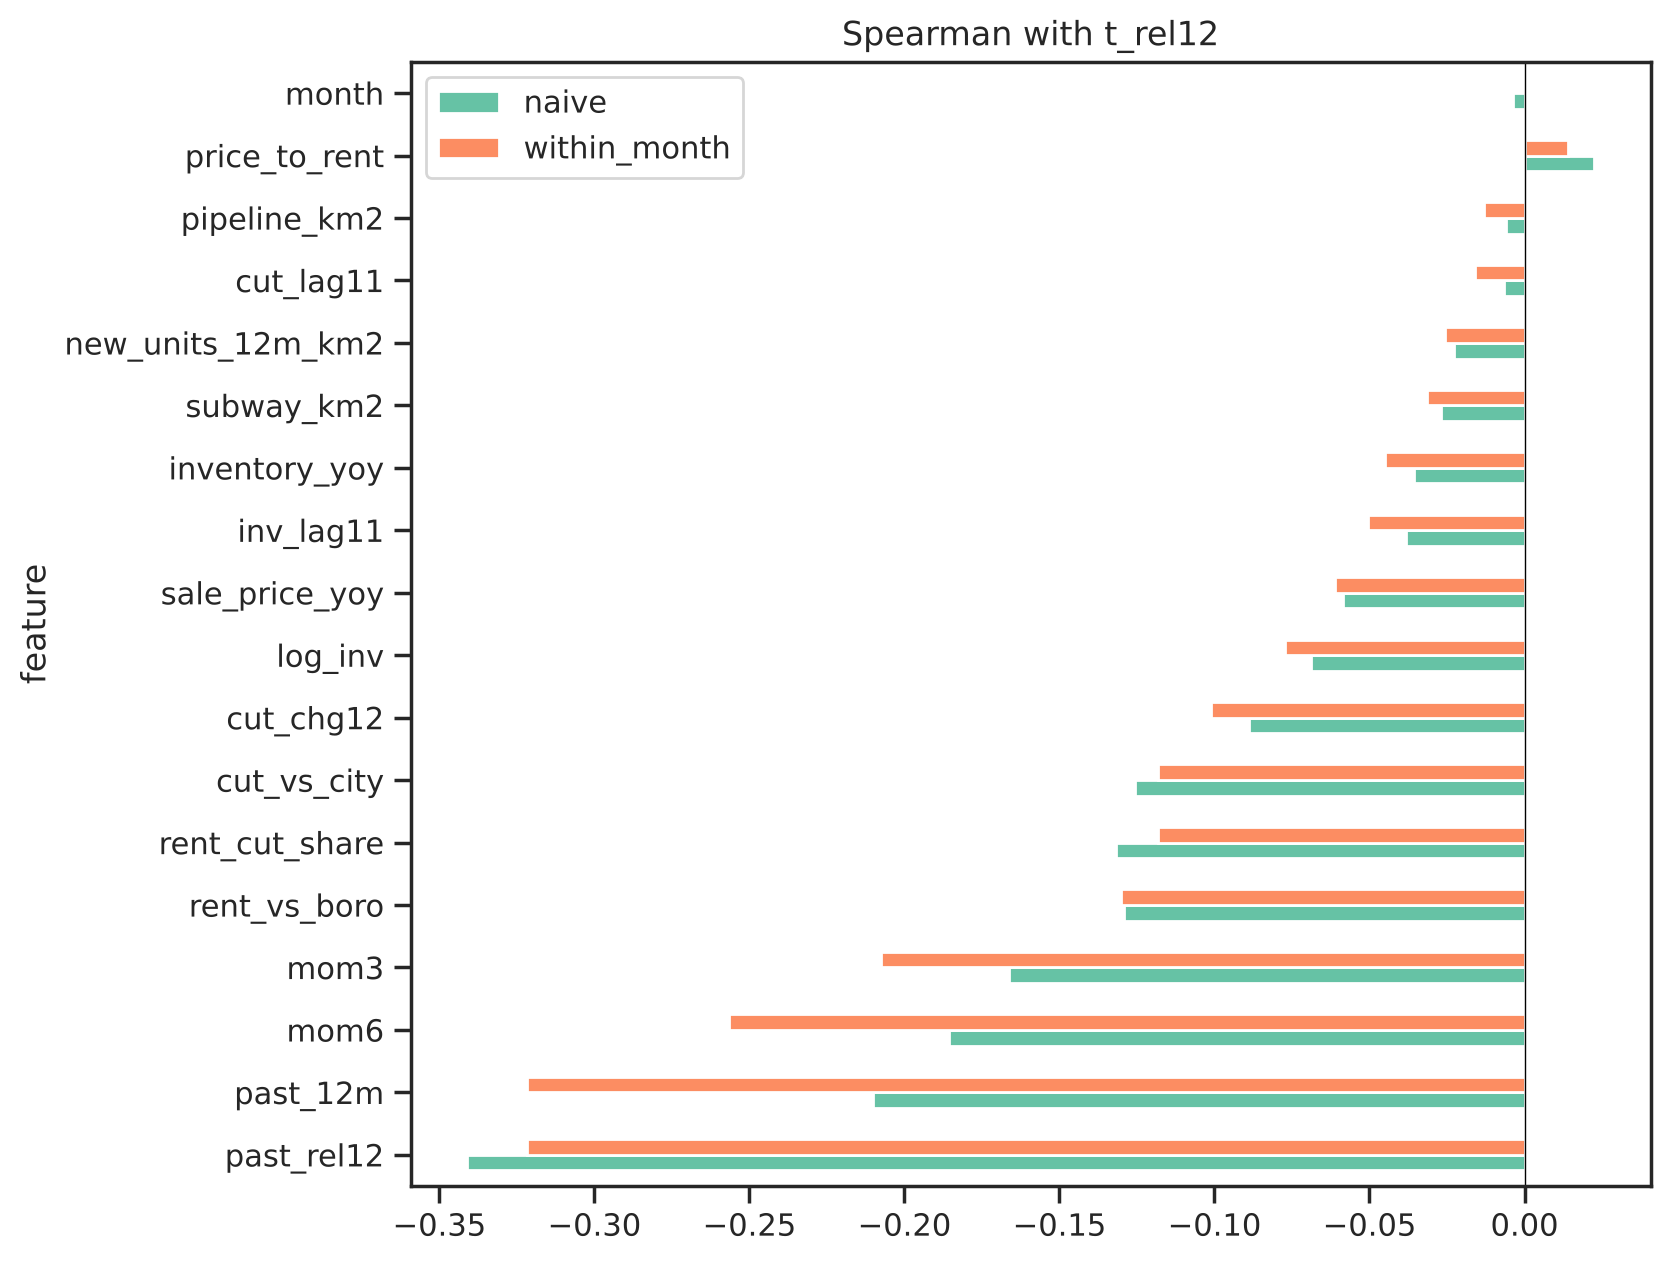

,feature,naive,within_month
1,past_rel12,-0.341,-0.322
0,past_12m,-0.210,-0.322
3,mom6,-0.186,-0.256
2,mom3,-0.166,-0.207
13,rent_vs_boro,-0.129,-0.130
4,rent_cut_share,-0.132,-0.118
6,cut_vs_city,-0.126,-0.118
5,cut_chg12,-0.089,-0.101
9,log_inv,-0.069,-0.077
11,sale_price_yoy,-0.058,-0.061


In [18]:
def signal_bar(target, feats=None):
    h = TARGETS[target][0]
    feats = feats or [f for f in TARGETS[target][1] if not f.startswith("boro_")]
    g = dev_data(target, h)
    rows = []
    for f in feats:
        naive = spearmanr(g[f], g[target], nan_policy="omit")[0]
        within = np.nanmean([spearmanr(x[f], x[target], nan_policy="omit")[0] for _, x in g.groupby("date") if x[f].nunique() > 1] or [np.nan])
        rows.append({"feature": f, "naive": naive, "within_month": within})
    t = pd.DataFrame(rows).sort_values("within_month")
    t.set_index("feature").plot(kind="barh", figsize=(8, 0.35 * len(t) + 1), title=f"Spearman with {target}")
    plt.axvline(0, color="k", lw=0.5)
    plt.show()
    return t.round(3)

signal_bar("t_rel12")

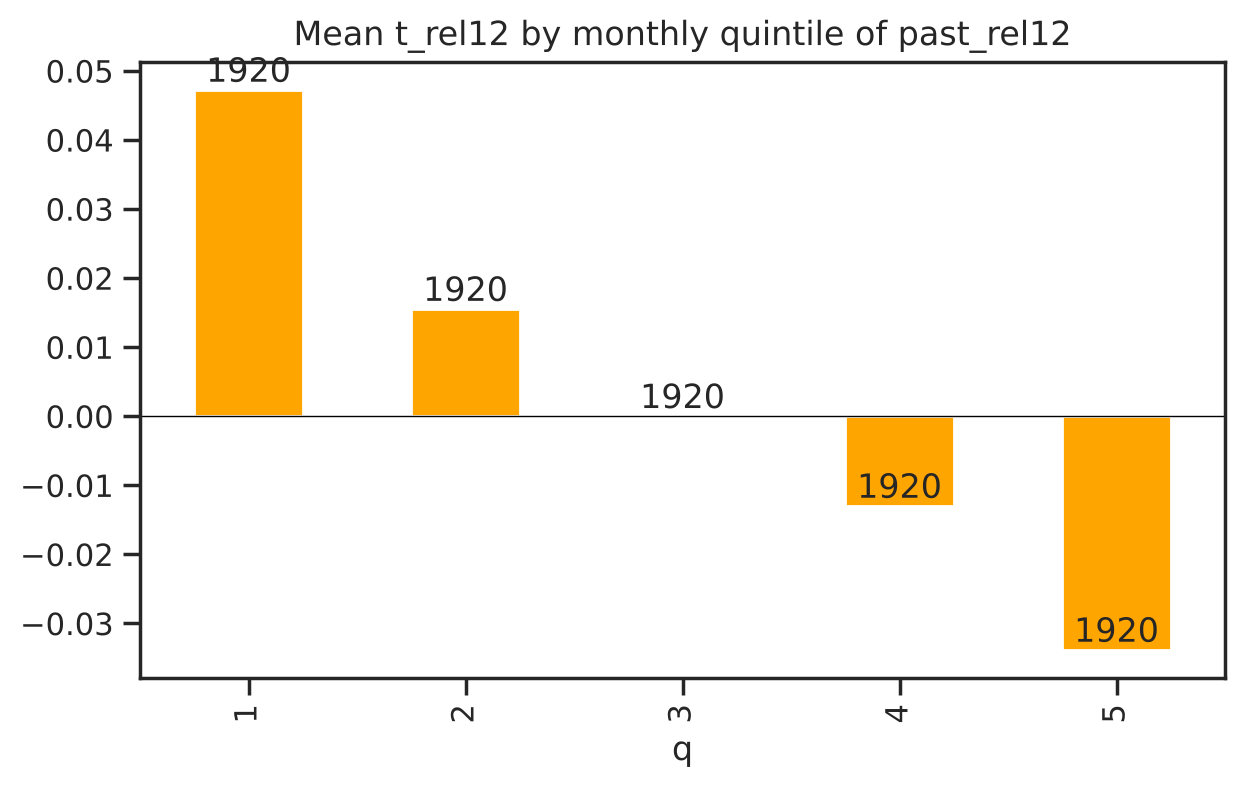

,mean,count
q,,
1,0.0473,1920
2,0.0155,1920
3,0.0000,1920
4,-0.0130,1920
5,-0.0338,1920


In [19]:
def quintile_plot(feature, target="t_rel12"):
    h = TARGETS[target][0] if target in TARGETS else 12
    g = dev_data(target, h).dropna(subset=[feature]).copy()
    g["q"] = g.groupby("date")[feature].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False) + 1)
    m = g.groupby("q")[target].agg(["mean", "count"])
    ax = m["mean"].plot(kind="bar", color="orange", figsize=(7, 4))
    for i, (v, n) in enumerate(zip(m["mean"], m["count"])):
        ax.text(i, v, n, ha="center", va="bottom")
    plt.axhline(0, color="k", lw=0.5)
    plt.title(f"Mean {target} by monthly quintile of {feature}")
    plt.show()
    return m.round(4)

quintile_plot("past_rel12")

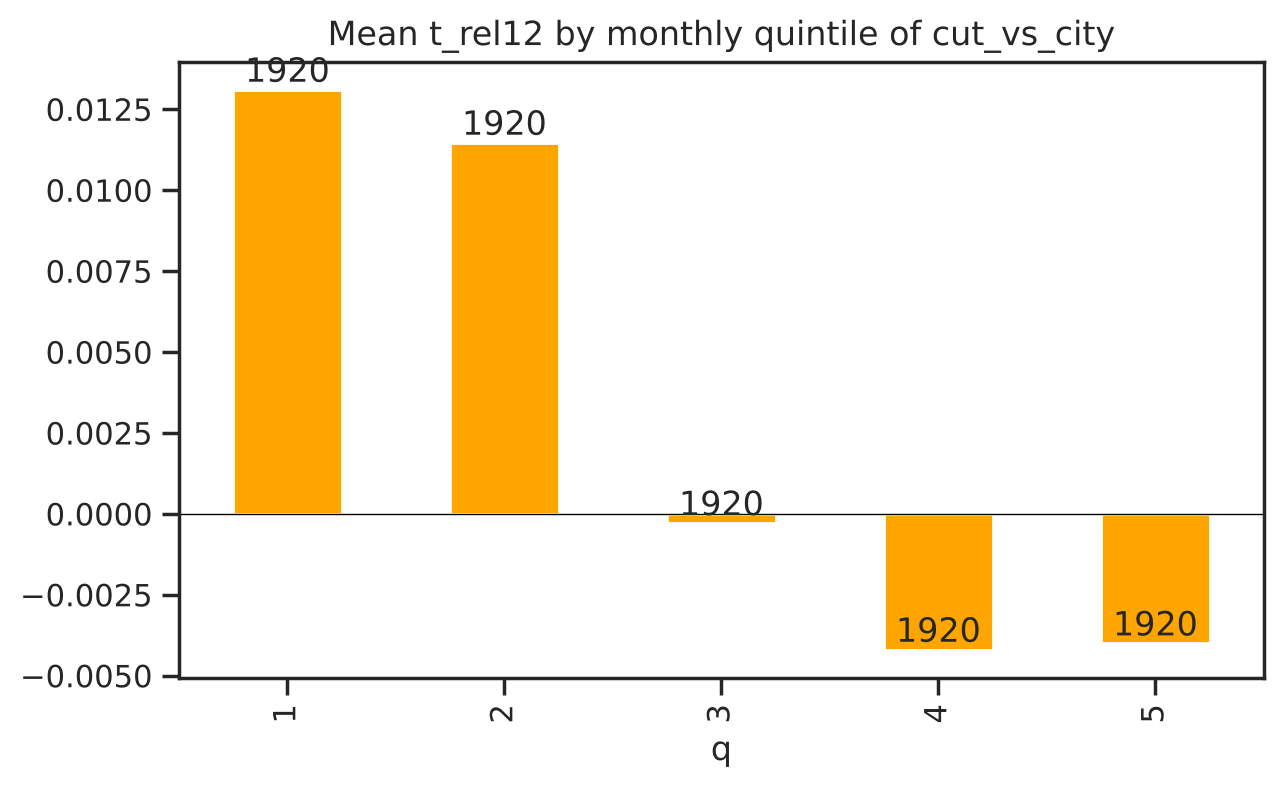

,mean,count
q,,
1,0.0131,1920
2,0.0115,1920
3,-0.0003,1920
4,-0.0042,1920
5,-0.0040,1920


In [20]:
quintile_plot("cut_vs_city")

## E. Does "cheap for its fundamentals" catch up?

Out-of-fold fair-rent model, then gap = actual − fair. Negative gap = cheap.

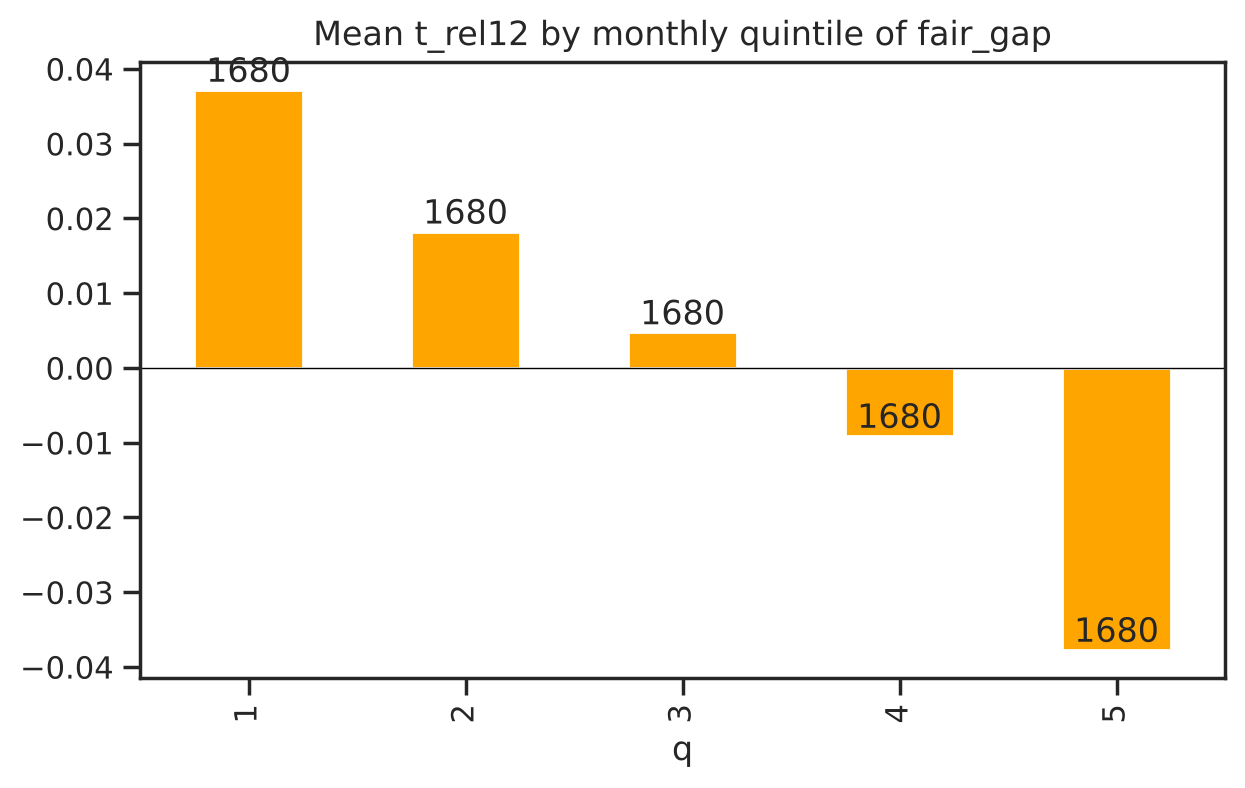

,mean,count
q,,
1,0.0372,1680
2,0.0182,1680
3,0.0048,1680
4,-0.0091,1680
5,-0.0377,1680


In [21]:
def oof(target, model_name="hgb", years=range(2016, 2024)):
    h, feats, base, kind = TARGETS[target]
    keep = (d.date >= START) & (d.date < TEST_START) & d[target].notna()
    data = d[keep]
    out = pd.Series(np.nan, index=d.index)
    for y in years:
        tr = data[data.date < pd.Timestamp(f"{y}-01-01") - pd.DateOffset(months=h)]
        va = data[data.date.dt.year == y]
        m = models(kind)[model_name]
        out[va.index] = fit_predict(m, tr[feats], tr[target], va[feats], kind)
    return out

d["fair_gap"] = d.t_fair - oof("t_fair")
quintile_plot("fair_gap")

## F. COVID and outliers (t_rel12)

COVID windows: origins whose lookback (t−12) or target (t+12) window touches 2020-03 → 2021-06 (T3: different population; T9: pre/post-COVID drift).
All variants are scored only on clean (non-COVID) validation rows.

dev rows: 9600 | covid windows: 4000 (42%)
{2015: 0.0, 2016: 0.0, 2017: 0.0, 2018: 0.0, 2019: 0.83, 2020: 1.0, 2021: 1.0, 2022: 0.5}


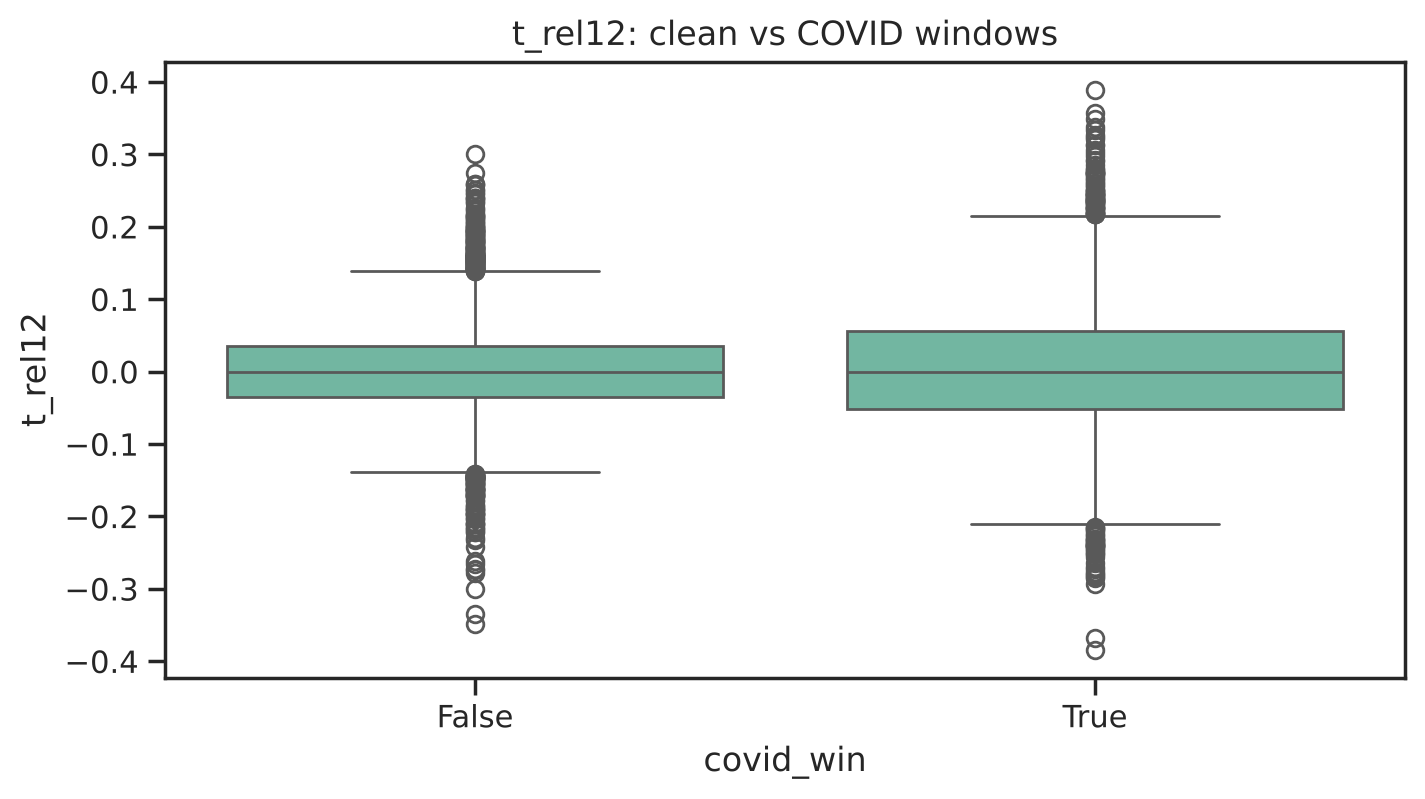

,count,mean,std,min,25%,50%,75%,max
covid_win,,,,,,,,
False,5600.0,0.003,0.064,-0.348,-0.035,0.0,0.035,0.30
True,4000.0,0.004,0.093,-0.384,-0.051,0.0,0.056,0.39


In [22]:
mi = d.date.dt.year * 12 + d.date.dt.month
c_start, c_end = 2020 * 12 + 3, 2021 * 12 + 6
d["covid_win"] = (mi + 12 >= c_start) & (mi - 12 <= c_end)
d["clean"] = ~d.covid_win

g = dev_data("t_rel12", 12)
print("dev rows:", len(g), "| covid windows:", g.covid_win.sum(), f"({g.covid_win.mean():.0%})")
print(g.groupby(g.date.dt.year).covid_win.mean().round(2).to_dict())

plt.figure(figsize=(8, 4))
sns.boxplot(data=g, x="covid_win", y="t_rel12")
plt.title("t_rel12: clean vs COVID windows")
plt.show()
g.groupby("covid_win").t_rel12.describe().round(3)

IQR bounds: -0.139 to 0.139 | outliers in clean rows: 4.7%


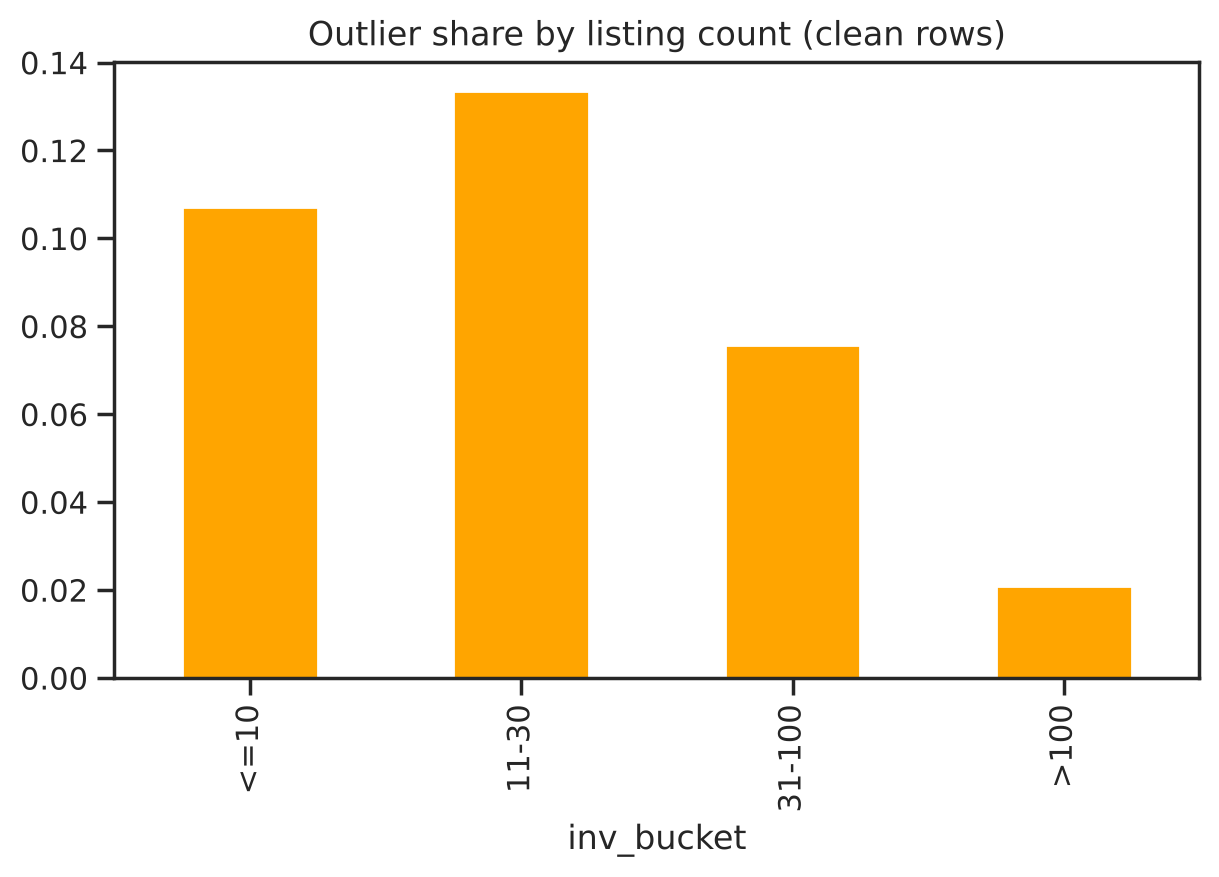

,rows,outlier_share
inv_bucket,,
<=10,28,0.107
11-30,487,0.133
31-100,1649,0.076
>100,3436,0.021


In [23]:
clean = g[g.clean]
q1, q3 = clean.t_rel12.quantile([0.25, 0.75])
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
d["outlier"] = (d.t_rel12 < lo) | (d.t_rel12 > hi)
g = dev_data("t_rel12", 12)
print(f"IQR bounds: {lo:.3f} to {hi:.3f} | outliers in clean rows: {g[g.clean].outlier.mean():.1%}")

g["inv_bucket"] = pd.cut(g.inventory, [-1, 10, 30, 100, np.inf], labels=["<=10", "11-30", "31-100", ">100"])
t = g[g.clean].groupby("inv_bucket", observed=True).agg(rows=("outlier", "size"), outlier_share=("outlier", "mean"))
t["outlier_share"].plot(kind="bar", color="orange", figsize=(7, 4), title="Outlier share by listing count (clean rows)")
plt.show()
t.round(3)

In [24]:
g[g.clean & g.outlier].groupby("areaName").size().sort_values(ascending=False).head(15)

areaName
Tribeca                      26
Jamaica Estates              18
Bath Beach                   13
Rockaway All                 13
Jamaica                      12
Kingsbridge                  12
Corona                       10
Battery Park City            10
Prospect Lefferts Gardens     9
Fordham                       9
Tremont                       8
Belmont                       7
West Harlem                   7
Woodside                      7
Red Hook                      7
dtype: int64

In [25]:
FULL = TARGETS["t_rel12"][1]
SMALL = ["past_rel12"]
CLEAN_YEARS = [2017, 2018, 2019, 2022]

variants = {
    "all": dict(),
    "no_covid": dict(drop=["covid_win"]),
    "no_covid_no_outliers": dict(drop=["covid_win", "outlier"]),
    "no_covid_sliding_3y": dict(drop=["covid_win"], window=3),
}

rows = []
for vname, kw in variants.items():
    for fname, feats in [("full", FULL), ("past_rel12", SMALL)]:
        r = evaluate("t_rel12", feats=feats, years=CLEAN_YEARS, score_on="clean", **kw)
        r = r[r.model != "baseline"].assign(variant=vname, feats=fname)
        rows.append(r)
var = pd.concat(rows, ignore_index=True)
var["setup"] = var.model + " | " + var.feats

var.groupby(["variant", "setup"])[["rank", "mae"]].mean().unstack("setup").round(3)

rank                                \
setup                hgb | full hgb | past_rel12 ridge | full   
variant                                                         
all                       0.207            0.180        0.186   
no_covid                  0.196            0.167        0.192   
no_covid_no_outliers      0.215            0.147        0.186   
no_covid_sliding_3y       0.102            0.164        0.137   

                                               mae                   \
setup                ridge | past_rel12 hgb | full hgb | past_rel12   
variant                                                               
all                               0.222      0.054            0.045   
no_covid                          0.222      0.053            0.045   
no_covid_no_outliers              0.222      0.049            0.045   
no_covid_sliding_3y               0.222      0.057            0.046   

                                                      
setup                ridge | full ridge | past_rel12  
variant                                               
all                         0.050              0.044  
no_covid                    0.049              0.044  
no_covid_no_outliers        0.046              0.043  
no_covid_sliding_3y         0.052              0.044

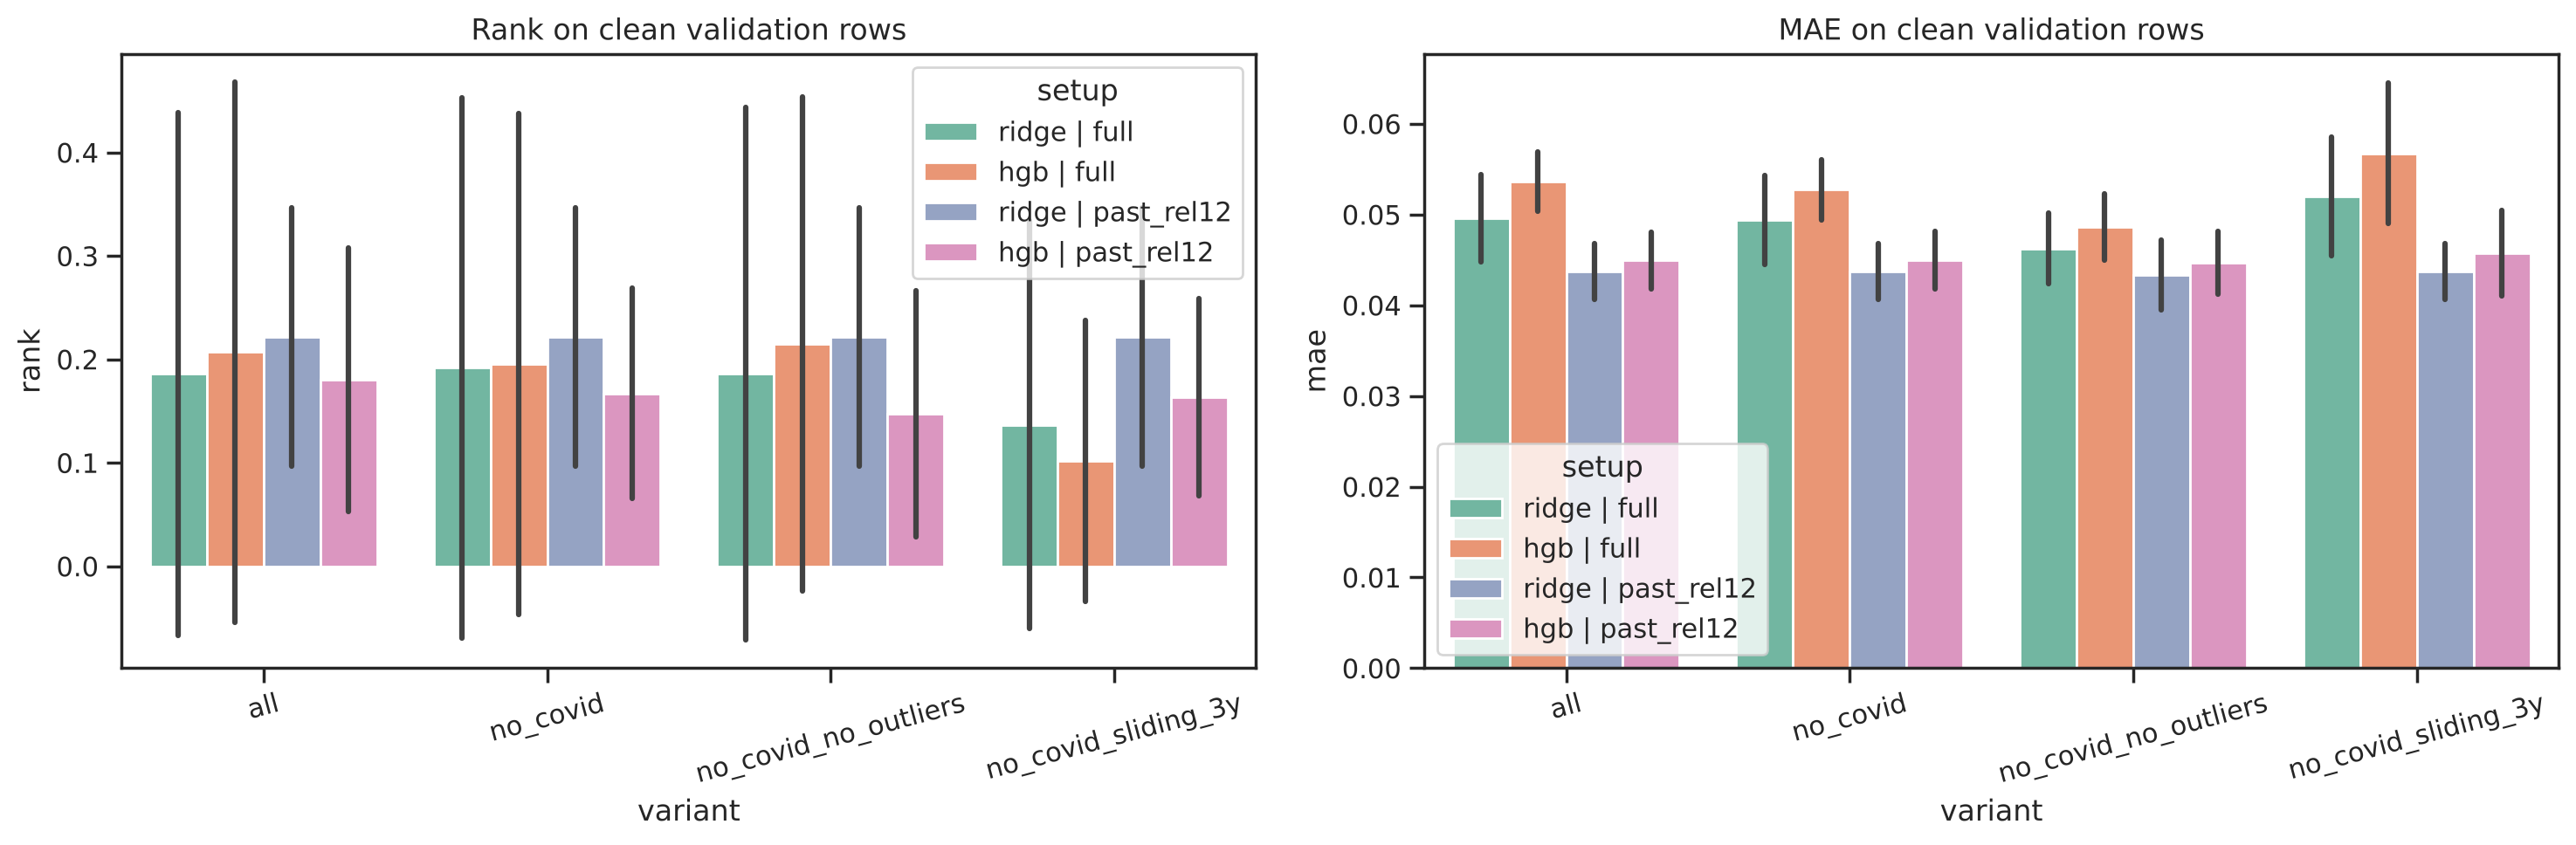

year                                      2017   2018   2019   2022
variant              setup                                         
all                  hgb | full          0.286 -0.015  0.014  0.542
                     hgb | past_rel12    0.095  0.095  0.167  0.364
                     ridge | full        0.351 -0.002 -0.057  0.451
                     ridge | past_rel12  0.146  0.251  0.105  0.385
no_covid             hgb | full          0.286 -0.015  0.014  0.497
                     hgb | past_rel12    0.095  0.095  0.167  0.311
                     ridge | full        0.351 -0.002 -0.057  0.475
                     ridge | past_rel12  0.146  0.251  0.105  0.385
no_covid_no_outliers hgb | full          0.295  0.000  0.047  0.516
                     hgb | past_rel12    0.033  0.085  0.165  0.306
                     ridge | full        0.347 -0.011 -0.055  0.462
                     ridge | past_rel12  0.146  0.251  0.105  0.385
no_covid_sliding_3y  hgb | full          0.286 -0.015  0.014  0.120
                     hgb | past_rel12    0.095  0.095  0.167  0.297
                     ridge | full        0.351 -0.002 -0.057  0.255
                     ridge | past_rel12  0.146  0.251  0.105  0.385

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=var, x="variant", y="rank", hue="setup", errorbar="sd", ax=axs[0])
axs[0].set_title("Rank on clean validation rows")
sns.barplot(data=var, x="variant", y="mae", hue="setup", errorbar="sd", ax=axs[1])
axs[1].set_title("MAE on clean validation rows")
for ax in axs:
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

var.pivot_table(index=["variant", "setup"], columns="year", values="rank").round(3)

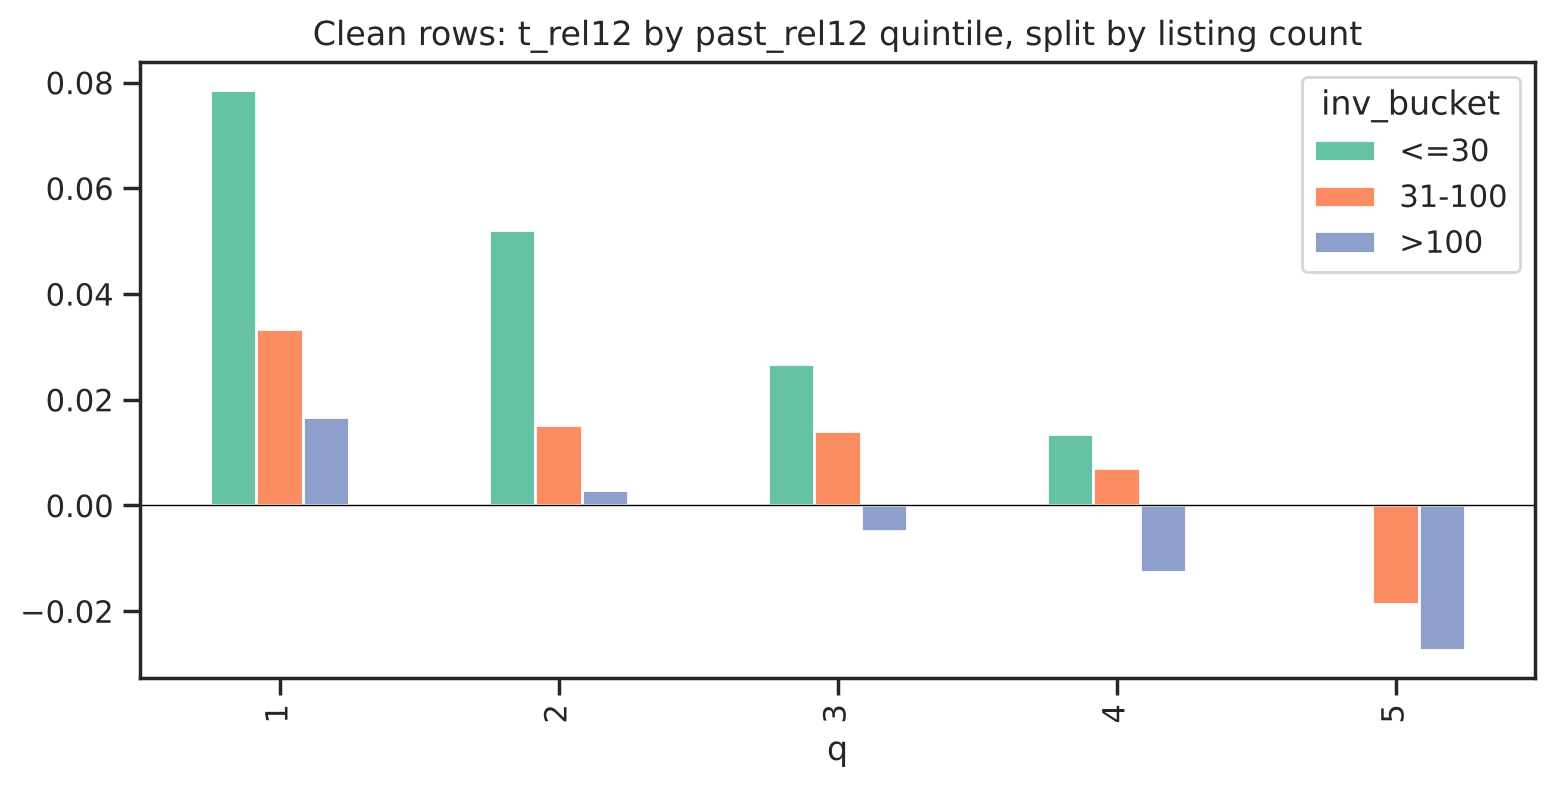

inv_bucket,<=30,31-100,>100
q,,,
1,0.0786,0.0333,0.0167
2,0.0521,0.0152,0.0029
3,0.0268,0.0140,-0.0048
4,0.0135,0.0071,-0.0127
5,-0.0001,-0.0187,-0.0273


In [27]:
g = dev_data("t_rel12", 12)
g = g[g.clean].copy()
g["q"] = g.groupby("date").past_rel12.transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False) + 1)
g["inv_bucket"] = pd.cut(g.inventory, [-1, 30, 100, np.inf], labels=["<=30", "31-100", ">100"])
m = g.pivot_table(index="q", columns="inv_bucket", values="t_rel12", aggfunc="mean", observed=True)
m.plot(kind="bar", figsize=(9, 4), title="Clean rows: t_rel12 by past_rel12 quintile, split by listing count")
plt.axhline(0, color="k", lw=0.5)
plt.show()
m.round(4)

## G. Merge neighborhoods that share an NTA

Rows are combined into one neighborhood per `merge_group`: rent and price-cut share are listing-weighted means, inventory is summed.
Both versions are scored on the original 100 neighborhoods (merged prediction is given to every member), so the numbers are comparable.

In [28]:
def merge_panel(df):
    x = df.copy()
    x["rent_inv"] = x.inventory.where(x.rent.notna(), 0)
    x["cut_inv"] = x.inventory.where(x.rent_cut_share.notna(), 0)
    x["rent_w"] = (x.rent * x.inventory).fillna(0)
    x["cut_w"] = (x.rent_cut_share * x.inventory).fillna(0)
    m = x.groupby(["merge_group", "date"]).agg(
        Borough=("Borough", "first"), area_km2=("area_km2", "mean"), inventory=("inventory", "sum"),
        rent_w=("rent_w", "sum"), rent_inv=("rent_inv", "sum"), cut_w=("cut_w", "sum"), cut_inv=("cut_inv", "sum"),
        sale_price=("sale_price", "mean"), new_units_12m_km2=("new_units_12m_km2", "mean"),
        pipeline_km2=("pipeline_km2", "mean"), subway_km2=("subway_km2", "mean"),
        members=("areaName", "nunique")).reset_index()
    m["areaName"] = m.merge_group
    m["rent"] = m.rent_w / m.rent_inv.replace(0, np.nan)
    m["rent_cut_share"] = m.cut_w / m.cut_inv.replace(0, np.nan)
    m = m.sort_values(["areaName", "date"]).reset_index(drop=True)
    m["rent_3m"] = m.groupby("areaName").rent.transform(lambda s: s.rolling(3).mean())
    m["past_12m"] = m.rent_3m / m.groupby("areaName").rent_3m.shift(12) - 1
    m["inventory_yoy"] = m.inventory / m.groupby("areaName").inventory.shift(12) - 1
    m["sale_price_yoy"] = m.sale_price / m.groupby("areaName").sale_price.shift(12) - 1
    m["price_to_rent"] = m.sale_price / (12 * m.rent)
    med = m[m.date >= START].groupby("areaName").inventory.median()
    m["in_model"] = (m.areaName.map(med) >= 20).astype(int)
    return m[m.in_model == 1].reset_index(drop=True)

def add_flags(f):
    mi = f.date.dt.year * 12 + f.date.dt.month
    f["covid_win"] = (mi + 12 >= c_start) & (mi - 12 <= c_end)
    f["clean"] = ~f.covid_win
    f["outlier"] = (f.t_rel12 < lo) | (f.t_rel12 > hi)
    return f

dm = add_flags(add_targets(add_features(merge_panel(df))))
print("neighborhoods:", d.areaName.nunique(), "->", dm.areaName.nunique())
print("merged groups with 2+ members:", (dm.drop_duplicates("areaName").members > 1).sum())

neighborhoods: 100 -> 86
merged groups with 2+ members: 18


In [29]:
def fold_preds(frame, feats, model_name, drop=("covid_win", "outlier"), years=CLEAN_YEARS):
    data = dev_data("t_rel12", 12, frame)
    out = []
    for y, tr, va in folds(data, 12, years):
        tr = tr[~data.loc[tr, list(drop)].any(axis=1).values]
        m = models("reg")[model_name]
        p = m.fit(data.loc[tr, feats], data.loc[tr, "t_rel12"]).predict(data.loc[va, feats])
        out.append(data.loc[va, ["areaName", "date"]].assign(pred=p, year=y))
    return pd.concat(out)

def score_on_base(p, key):
    b = dev_data("t_rel12", 12)
    b = b[b.clean][["areaName", "merge_group", "date", "t_rel12", "shares_nta"]]
    t = b.merge(p.rename(columns={"areaName": key}), on=[key, "date"])
    rows = []
    for y, x in t.groupby("year"):
        for grp, xx in [("all", x), ("shares_nta", x[x.shares_nta == 1])]:
            rows.append({"year": y, "rows": grp, "rank": month_rank(xx.date, xx.t_rel12, xx.pred),
                         "mae": mean_absolute_error(xx.t_rel12, xx.pred)})
    return pd.DataFrame(rows)

rows = []
for version, frame, key in [("base", d, "areaName"), ("merged", dm, "merge_group")]:
    for model_name in ["ridge", "hgb"]:
        for fname, feats in [("full", FULL), ("past_rel12", SMALL)]:
            r = score_on_base(fold_preds(frame, feats, model_name), key)
            rows.append(r.assign(version=version, setup=f"{model_name} | {fname}"))
mg = pd.concat(rows, ignore_index=True)

mg.pivot_table(index=["rows", "setup"], columns="version", values=["rank", "mae"]).round(3)

mae          rank       
version                         base merged   base merged
rows       setup                                         
all        hgb | full          0.049  0.049  0.215  0.172
           hgb | past_rel12    0.045  0.045  0.147  0.096
           ridge | full        0.046  0.048  0.186  0.144
           ridge | past_rel12  0.043  0.044  0.222  0.204
shares_nta hgb | full          0.051  0.052  0.256  0.159
           hgb | past_rel12    0.049  0.049  0.186  0.145
           ridge | full        0.049  0.052  0.258  0.143
           ridge | past_rel12  0.047  0.048  0.269  0.214

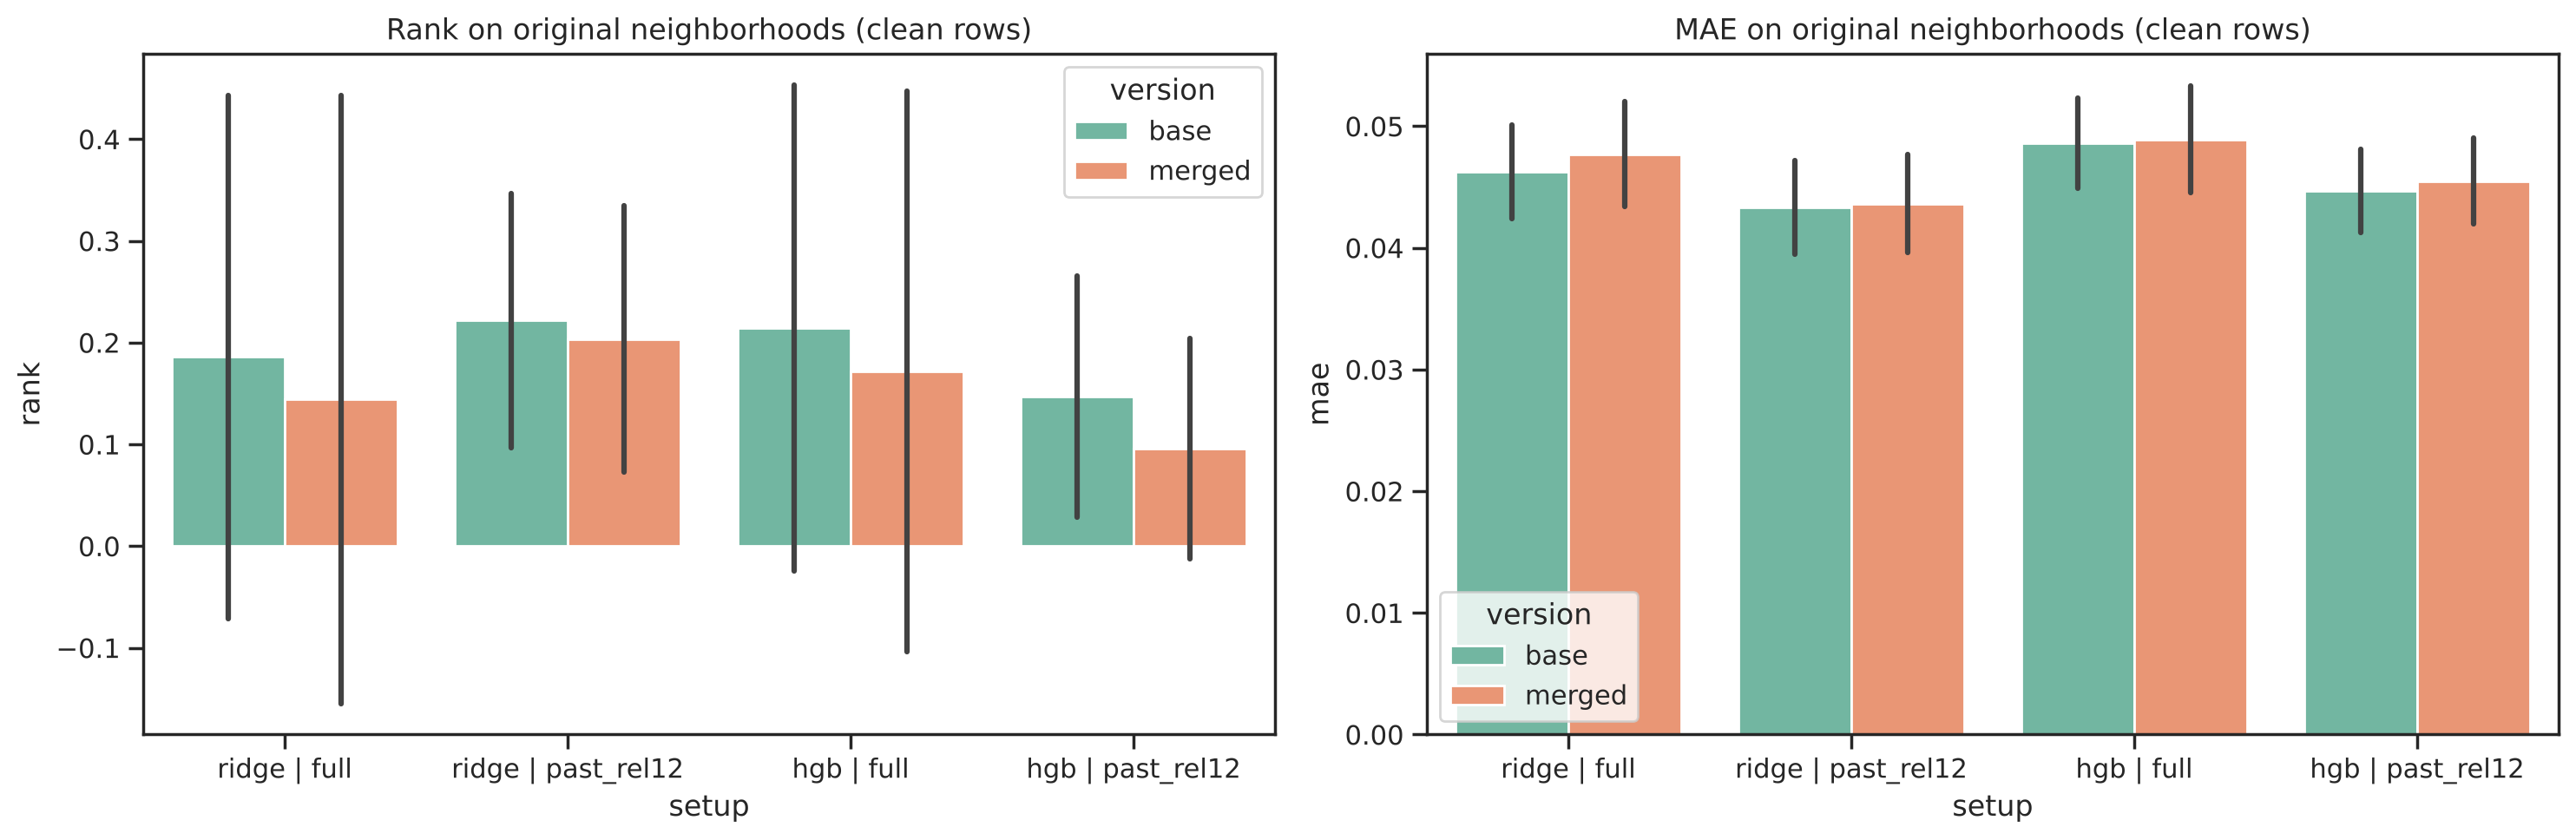

year                         2017   2018   2019   2022
setup              version                            
hgb | full         base     0.295  0.000  0.047  0.516
                   merged   0.222 -0.035 -0.042  0.542
hgb | past_rel12   base     0.033  0.085  0.165  0.306
                   merged   0.041 -0.004  0.101  0.244
ridge | full       base     0.347 -0.011 -0.055  0.462
                   merged   0.315 -0.103 -0.114  0.478
ridge | past_rel12 base     0.146  0.251  0.105  0.385
                   merged   0.115  0.189  0.117  0.393

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
x = mg[mg.rows == "all"]
sns.barplot(data=x, x="setup", y="rank", hue="version", errorbar="sd", ax=axs[0])
axs[0].set_title("Rank on original neighborhoods (clean rows)")
sns.barplot(data=x, x="setup", y="mae", hue="version", errorbar="sd", ax=axs[1])
axs[1].set_title("MAE on original neighborhoods (clean rows)")
plt.tight_layout()
plt.show()

mg[mg.rows == "all"].pivot_table(index=["setup", "version"], columns="year", values="rank").round(3)

## I. Business predictions

Same clean setup everywhere: COVID windows (lookback 12m or target window touching 2020-03 → 2021-06) are dropped from train and validation, IQR outliers dropped from train.
`lift` = share of the true top 20% found in the predicted top 20%, divided by 0.2 (1 = random).

In [31]:
def add_business(d):
    def lag(col, k):
        return d.groupby("areaName")[col].shift(k)

    def fwd(col, k):
        return d.groupby("areaName")[col].shift(-k)

    def vs_city(s):
        return s - s.groupby(d.date).transform("median")

    d["log_sale3"] = np.log(d.groupby("areaName").sale_price.transform(lambda s: s.rolling(3).mean()))
    d["inv_yoy_log"] = d.log_inv - lag("log_inv", 12)
    d["sale_rel12"] = vs_city(d.log_sale3 - lag("log_sale3", 12))
    d["sale_mom3"] = d.log_sale3 - lag("log_sale3", 3)
    d["t_inv3"] = fwd("log_inv", 3) - lag("log_inv", 9)
    d["t_sale_rel12"] = vs_city(fwd("log_sale3", 12) - d.log_sale3)
    d["b_inv3"] = d.inv_yoy_log
    d["b_zero"] = 0.0
    return d.replace([np.inf, -np.inf], np.nan)

d = add_business(d)

def covid_mask(f, h):
    mi = f.date.dt.year * 12 + f.date.dt.month
    return (mi + h >= c_start) & (mi - 12 <= c_end)

def top_lift(dates, y, p, q=0.2):
    t = pd.DataFrame({"date": dates.values, "y": np.asarray(y), "p": np.asarray(p)}).reset_index(drop=True)
    hits = []
    for _, g in t.groupby("date"):
        if g.p.nunique() < 2:
            continue
        k = max(1, int(len(g) * q))
        hits.append(len(set(g.nlargest(k, "y").index) & set(g.nlargest(k, "p").index)) / k)
    return np.mean(hits) / q if hits else np.nan

def run_task(target, h, feats, baselines=(), years=(2017, 2018, 2019, 2022), start=START):
    f = d[(d.date >= start) & (d.date < TEST_START - pd.DateOffset(months=h)) & d[target].notna()].reset_index(drop=True)
    f["covid"] = covid_mask(f, h)
    q1, q3 = f.loc[~f.covid, target].quantile([0.25, 0.75])
    f["out"] = (f[target] < q1 - 1.5 * (q3 - q1)) | (f[target] > q3 + 1.5 * (q3 - q1))
    f["end_month"] = (f.date.dt.month - 1 + h) % 12 + 1
    rows = []
    for y in years:
        st = pd.Timestamp(f"{y}-01-01")
        tr = f[(f.date < st - pd.DateOffset(months=h)) & ~f.covid & ~f.out]
        va = f[(f.date.dt.year == y) & ~f.covid]
        if len(va) == 0 or len(tr) == 0:
            continue
        preds = {n: m.fit(tr[feats], tr[target]).predict(va[feats]) for n, m in models("reg").items()}
        for b in baselines:
            if b == "season":
                means = tr.groupby(["Borough", "end_month"])[target].mean().rename("p")
                preds[b] = va.join(means, on=["Borough", "end_month"]).p.fillna(tr[target].mean()).values
            else:
                preds[b] = va[b].fillna(0).values
        for n, p in preds.items():
            rows.append({"target": target, "year": y, "model": n, "n": len(va),
                         "mae": mean_absolute_error(va[target], p),
                         "rank": month_rank(va.date, va[target], p),
                         "sign_acc": np.mean(np.sign(p) == np.sign(va[target])),
                         "lift": top_lift(va.date, va[target], p)})
    return pd.DataFrame(rows)

def show_task(r):
    t = r.groupby("model")[["mae", "rank", "sign_acc", "lift"]].mean().sort_values("mae").round(3)
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    for ax, col in zip(axs, ["mae", "rank", "lift"]):
        sns.barplot(data=r, x="model", y=col, errorbar="sd", ax=ax, order=t.index)
        ax.set_title(f"{r.target.iloc[0]}: {col}")
        ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.show()
    return t

### I1. Renter: sign now or wait? (rent change over the next 3 months)

Key question: does the model beat a pure seasonal baseline (`season` = average change for that borough and calendar month, from train)?

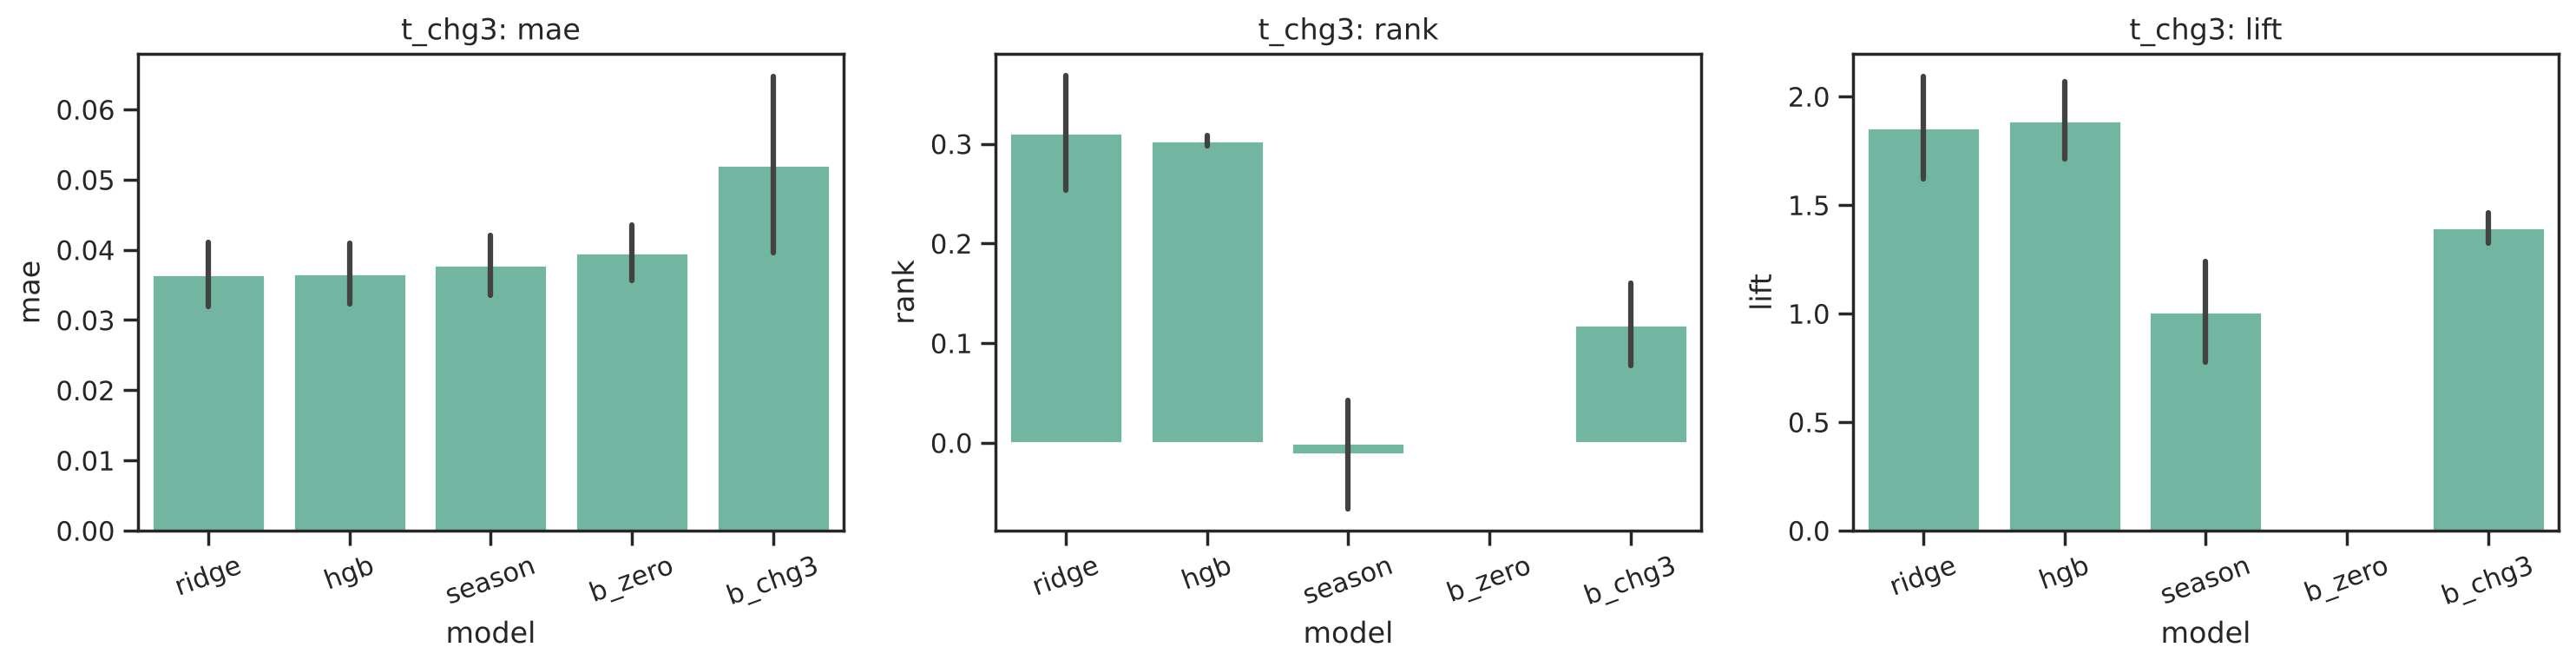

,mae,rank,sign_acc,lift
model,,,,
ridge,0.036,0.311,0.635,1.856
hgb,0.037,0.303,0.647,1.890
season,0.038,-0.012,0.613,1.008
b_zero,0.040,NaN,0.010,NaN
b_chg3,0.052,0.119,0.575,1.395


In [32]:
renter = run_task("t_chg3", 3, MARKET + CITY + BORO, ["b_chg3", "b_zero", "season"])
show_task(renter)

In [33]:
renter.pivot_table(index="model", columns="year", values="mae").round(4)

year,2017,2018,2019,2022
model,,,,
b_chg3,0.0465,0.0468,0.0443,0.0709
b_zero,0.0355,0.0387,0.0390,0.0450
hgb,0.0359,0.0346,0.0332,0.0429
ridge,0.0338,0.0344,0.0344,0.0433
season,0.0359,0.0361,0.0351,0.0442


### I2. Broker: where will listings surge? (inventory in 3 months vs same month last year)

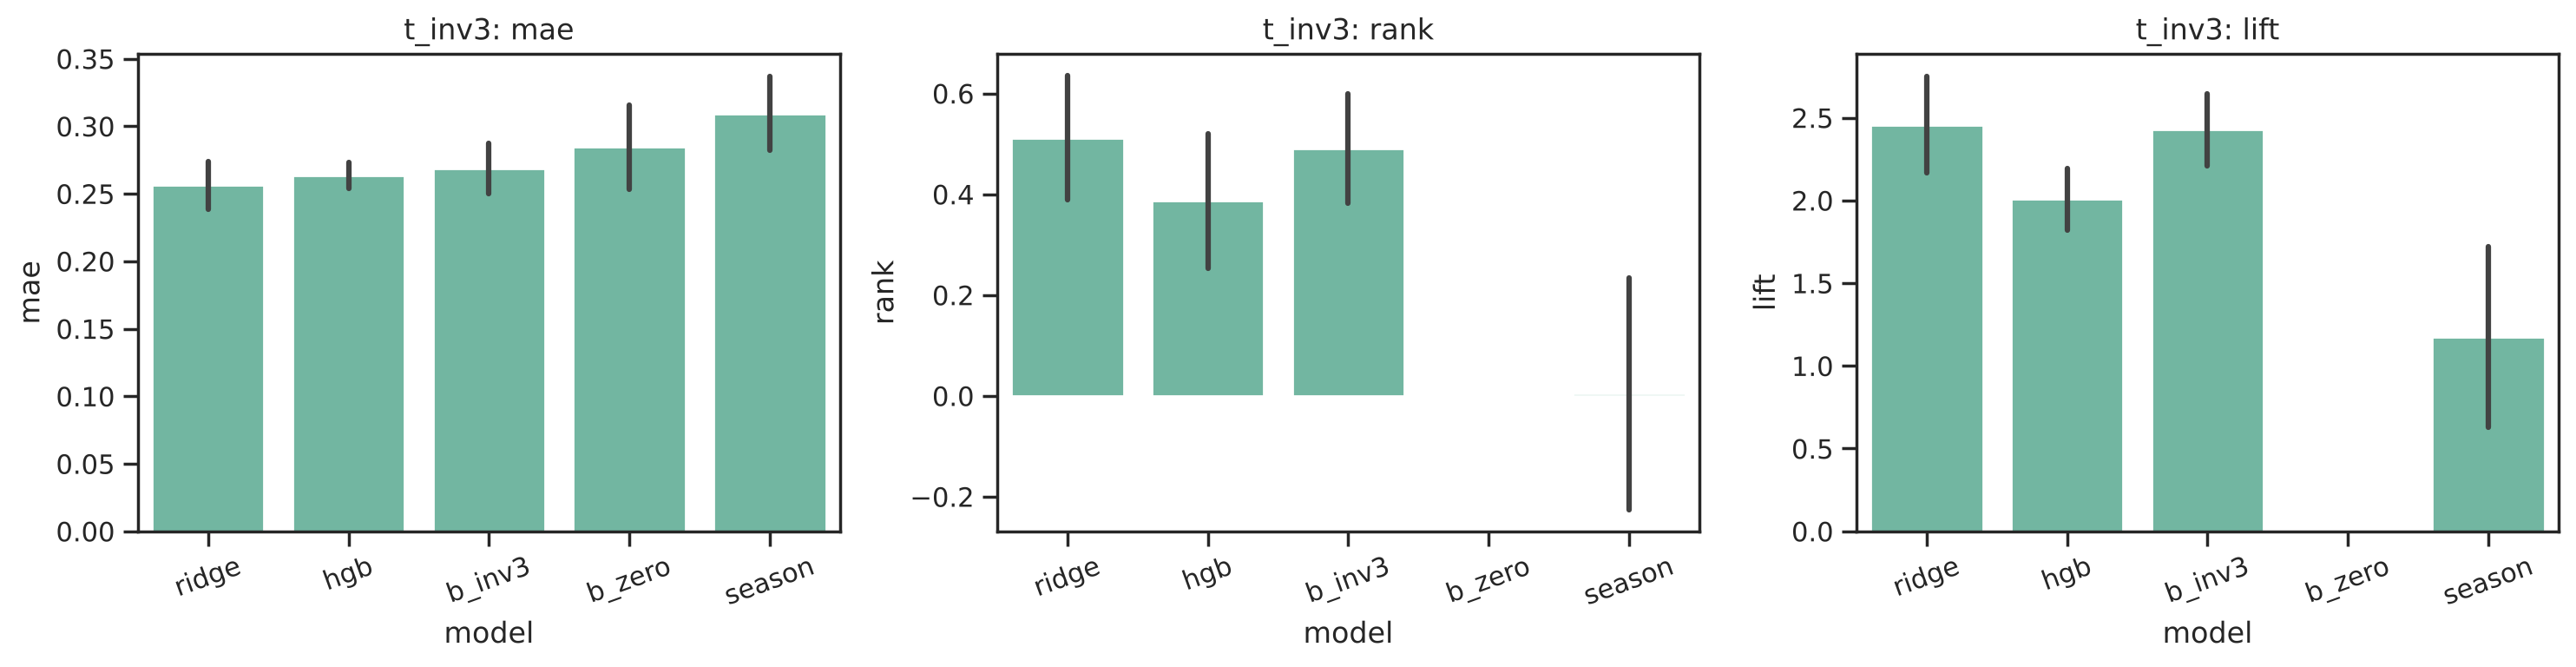

,mae,rank,sign_acc,lift
model,,,,
ridge,0.256,0.512,0.611,2.457
hgb,0.263,0.386,0.616,2.008
b_inv3,0.269,0.490,0.693,2.428
b_zero,0.285,NaN,0.008,NaN
season,0.309,0.004,0.443,1.175


In [34]:
broker = run_task("t_inv3", 3, MARKET + ["inv_yoy_log"] + BORO, ["b_inv3", "b_zero", "season"])
show_task(broker)

### I3. Flip: where will sale prices beat the city in 12 months?

Target = 12m change in 3m-smoothed median asking sale price, minus the city median change. `lift` = how well the model finds the top 20% neighborhoods.

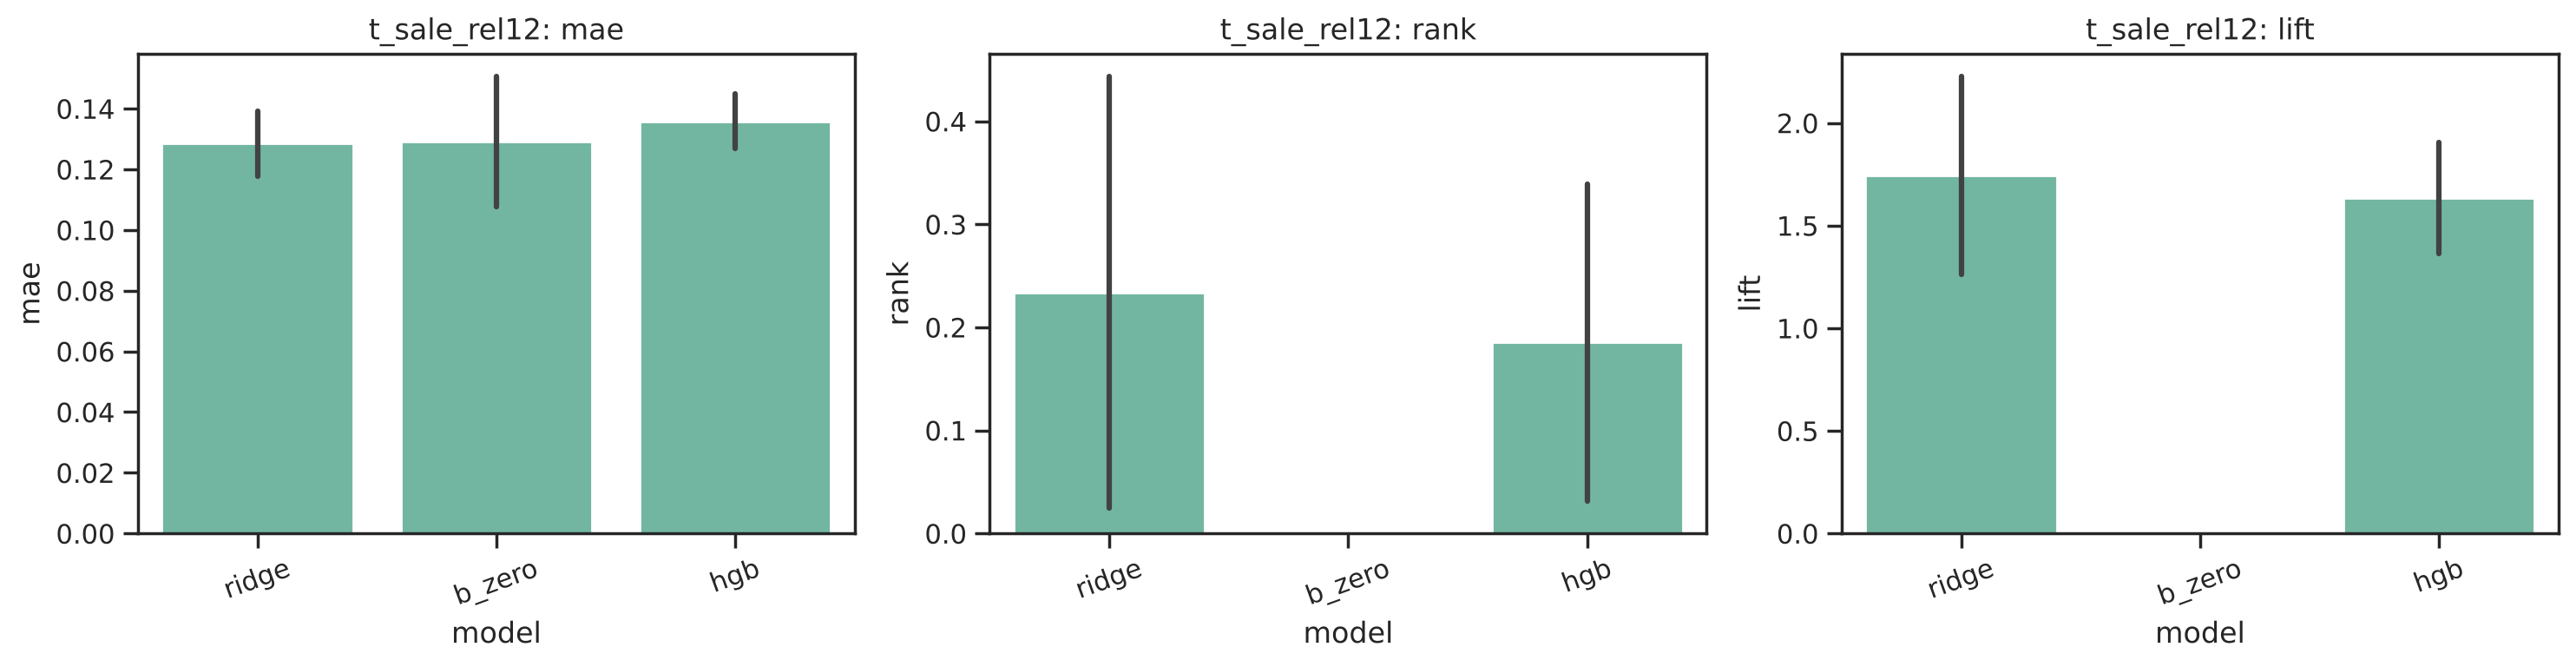

,mae,rank,sign_acc,lift
model,,,,
ridge,0.128,0.234,0.575,1.743
b_zero,0.129,NaN,0.003,NaN
hgb,0.136,0.185,0.580,1.634


In [35]:
SALE = ["sale_rel12", "sale_mom3", "sale_cut_share", "sale_price_yoy", "price_to_rent",
        "past_rel12", "mom3", "rent_cut_share", "log_inv", "inv_yoy_log", "rent_vs_boro"] + CITY + BORO
flip = run_task("t_sale_rel12", 12, SALE, ["b_zero"])
show_task(flip)

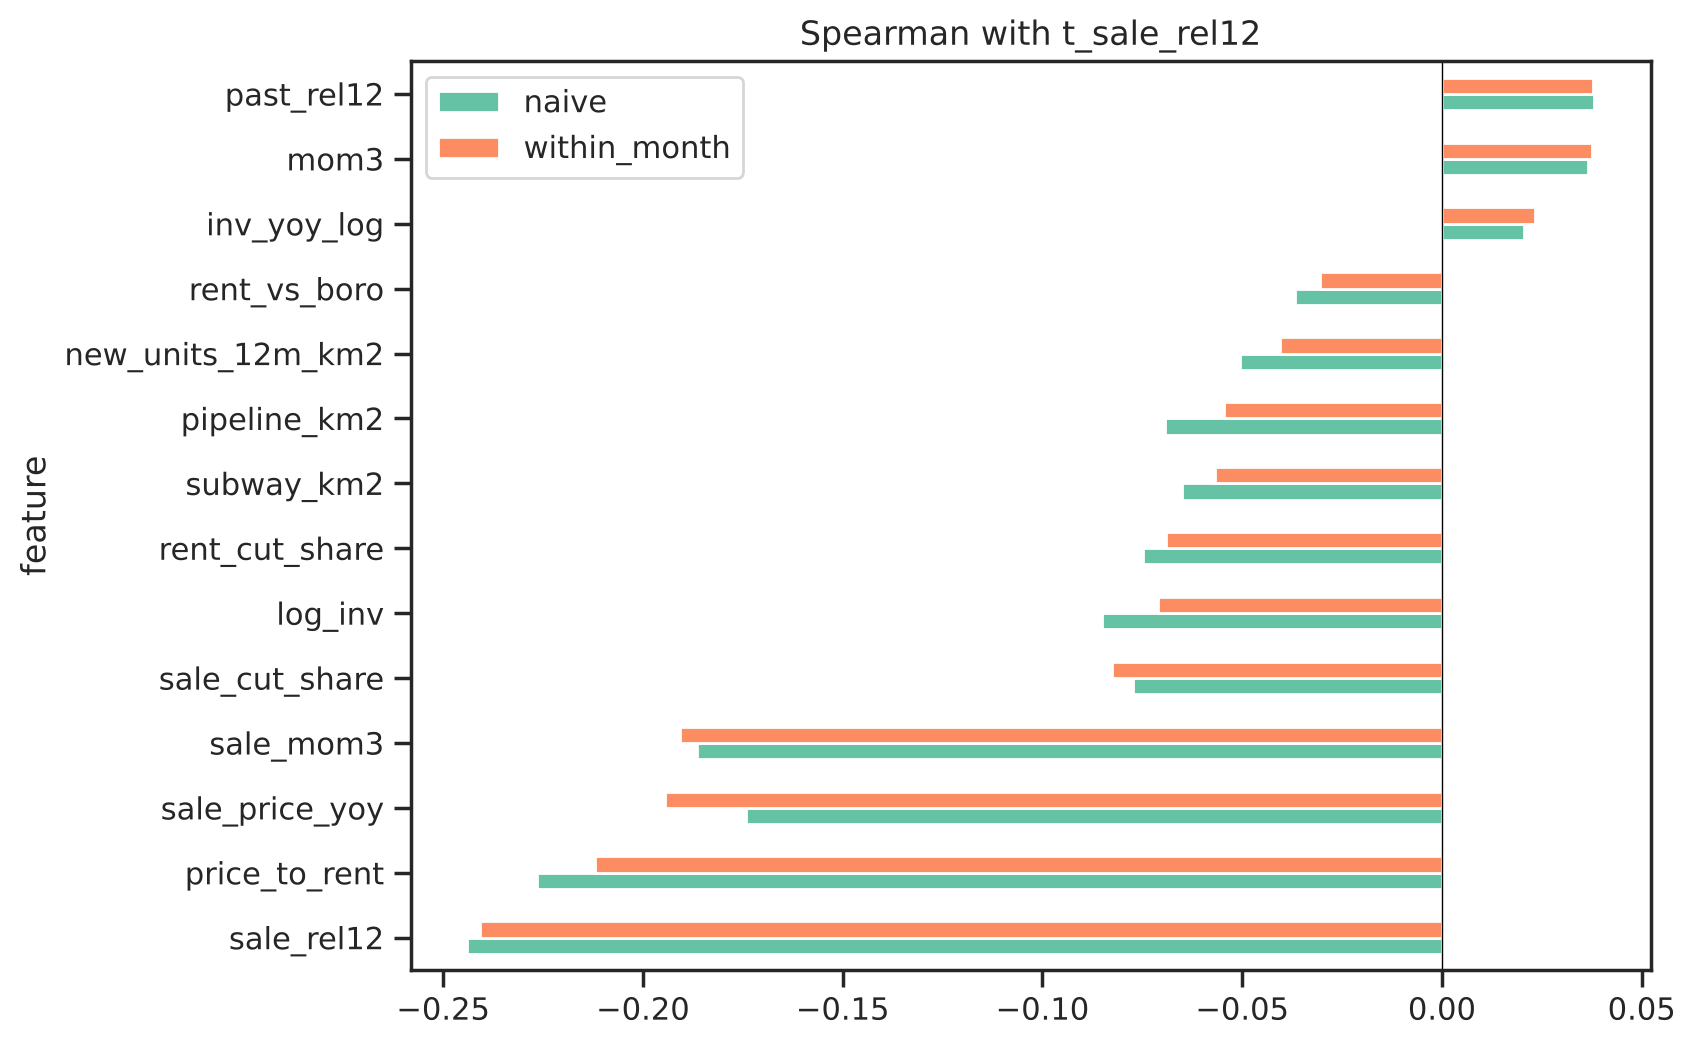

,feature,naive,within_month
0,sale_rel12,-0.244,-0.241
4,price_to_rent,-0.227,-0.212
3,sale_price_yoy,-0.174,-0.195
1,sale_mom3,-0.187,-0.191
2,sale_cut_share,-0.077,-0.083
8,log_inv,-0.085,-0.071
7,rent_cut_share,-0.075,-0.069
13,subway_km2,-0.065,-0.057
12,pipeline_km2,-0.069,-0.055
11,new_units_12m_km2,-0.050,-0.041


In [36]:
TARGETS["t_sale_rel12"] = (12, SALE, "b_zero", "reg")
signal_bar("t_sale_rel12")

### I4. Landlord: which lease length (12–24 months) puts the next renewal at the best rent?

For every signing month and every lease length L, value = log rent at renewal (t+L) − log rent now − L/12 × normal yearly growth (from train).
So a longer lease is not rewarded just for waiting; it wins only if it ends in a better month / better market.
Policies: always 12 months, seasonal rule (best end month by borough, from train), ridge, hgb, oracle (perfect hindsight).
Validation origins 2015–2017 (clean of COVID for all L), train from 2011.

In [37]:
LEASE_F = ["past_rel12", "mom3", "mom6", "rent_cut_share", "cut_vs_city", "log_inv", "inv_yoy_log", "rent_vs_boro"] + BORO

def lease_table(Ls=range(12, 25), start="2011-04-01"):
    parts = []
    for L in Ls:
        x = d[["areaName", "Borough", "date", "rent_3m"] + LEASE_F].copy()
        x["L"] = L
        x["end_month"] = (x.date.dt.month - 1 + L) % 12 + 1
        x["v"] = d.groupby("areaName").log_rent.shift(-L) - d.log_rent
        parts.append(x)
    t = pd.concat(parts, ignore_index=True)
    t = t[t.v.notna() & (t.date >= start)].reset_index(drop=True)
    mi = t.date.dt.year * 12 + t.date.dt.month
    t["mi"] = mi
    t["covid_row"] = (mi + t.L >= c_start) & (mi - 12 <= c_end)
    t["covid_origin"] = (mi + 24 >= c_start) & (mi - 12 <= c_end)
    em = pd.get_dummies(t.end_month, prefix="em", dtype=int)
    t[em.columns] = em
    return t

lease = lease_table()
EM = [c for c in lease.columns if c.startswith("em_")]
print(lease.shape)

(216942, 34)


In [38]:
def lease_eval(t, years=(2015, 2016, 2017)):
    X = LEASE_F + ["L"] + EM
    res, picks = [], []
    for y in years:
        tr = t[(t.mi + t.L < y * 12 + 1) & ~t.covid_row].copy()
        va = t[(t.date.dt.year == y) & ~t.covid_origin].copy()
        g = tr[tr.L == 12].v.median()
        tr["vd"] = tr.v - tr.L / 12 * g
        va["vd"] = va.v - va.L / 12 * g
        va["p_season"] = va.join(tr.groupby(["Borough", "end_month"]).vd.mean().rename("s"), on=["Borough", "end_month"]).s
        for n, m in models("reg").items():
            va[f"p_{n}"] = m.fit(tr[X], tr.vd).predict(va[X])
        base = va[va.L == 12].set_index(["areaName", "date"]).vd
        for name, col in [("12 months", None), ("season rule", "p_season"), ("ridge", "p_ridge"), ("hgb", "p_hgb"), ("oracle", "vd")]:
            pick = va[va.L == 12] if col is None else va.loc[va.groupby(["areaName", "date"])[col].idxmax()]
            pick = pick.set_index(["areaName", "date"])
            gain = pick.vd - base.reindex(pick.index)
            res.append({"year": y, "policy": name, "gain_pct": 100 * gain.mean(),
                        "gain_usd_month": ((np.exp(gain) - 1) * pick.rent_3m).mean()})
            picks.append(pick.reset_index()[["L", "end_month"]].assign(policy=name, year=y))
    return pd.DataFrame(res), pd.concat(picks)

lease_res, lease_picks = lease_eval(lease)
lease_res.groupby("policy")[["gain_pct", "gain_usd_month"]].mean().sort_values("gain_pct").round(2)

,gain_pct,gain_usd_month
policy,,
12 months,0.00,0.00
season rule,0.26,7.09
ridge,0.29,7.54
hgb,0.34,11.18
oracle,4.00,106.77


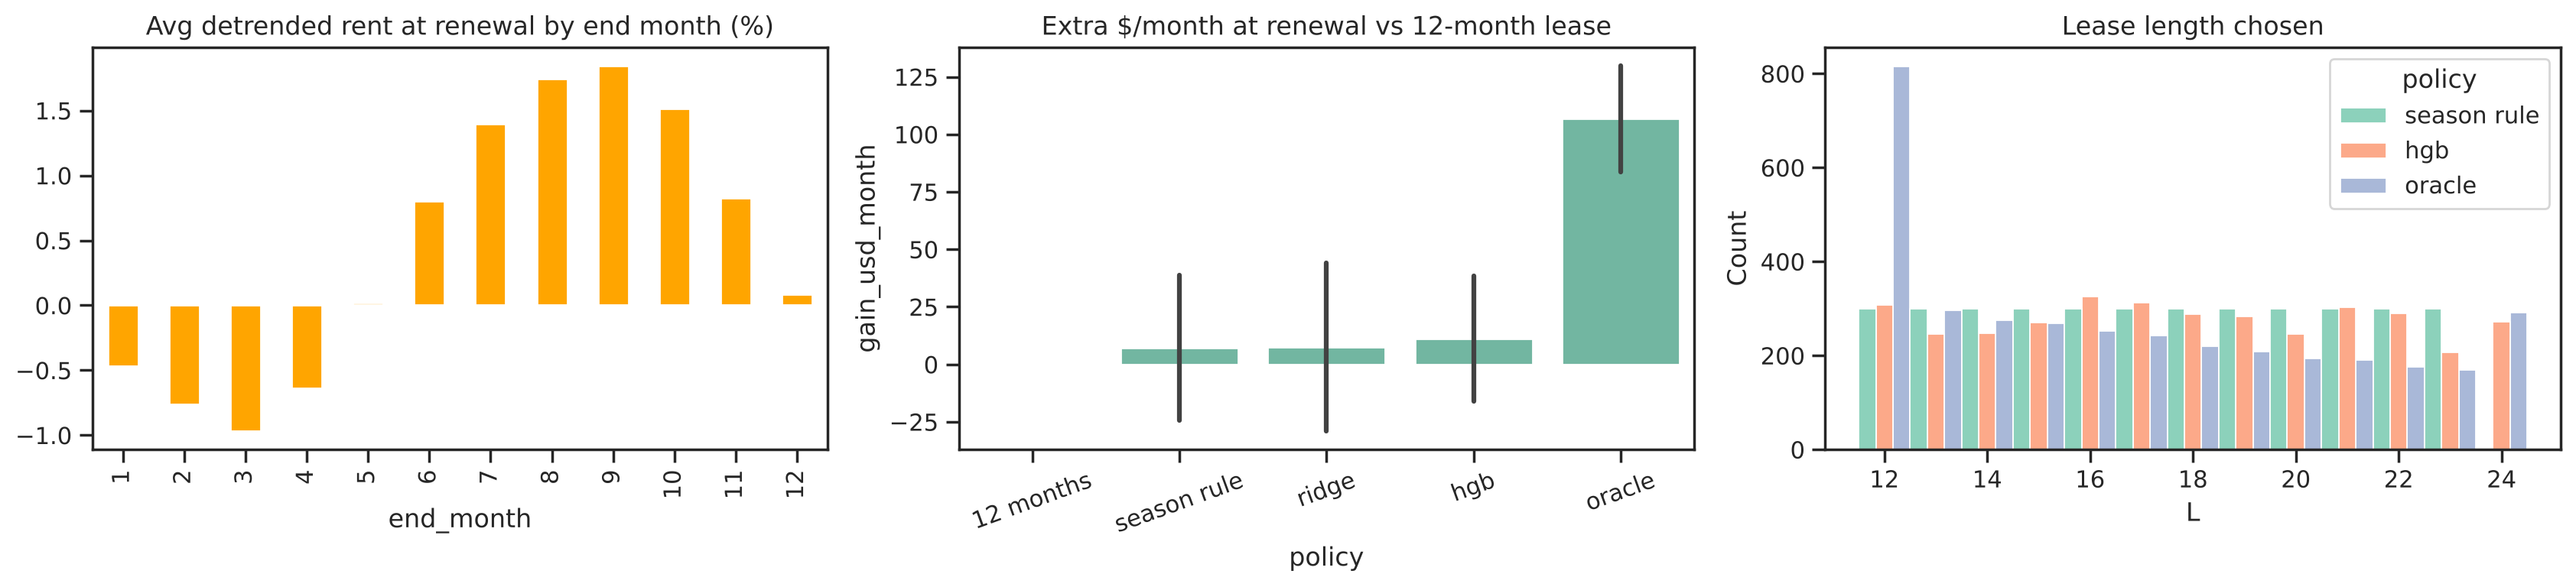

end_month
1      108
7      252
8      480
9     1680
10     972
11     108
dtype: int64

In [39]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
clean = lease[~lease.covid_row & (lease.date < "2019-01-01")].copy()
g = clean[clean.L == 12].v.median()
clean["vd"] = clean.v - clean.L / 12 * g
clean.groupby("end_month").vd.mean().mul(100).plot(kind="bar", ax=axs[0], color="orange")
axs[0].set_title("Avg detrended rent at renewal by end month (%)")
sns.barplot(data=lease_res, x="policy", y="gain_usd_month", errorbar="sd", ax=axs[1],
            order=["12 months", "season rule", "ridge", "hgb", "oracle"])
axs[1].set_title("Extra $/month at renewal vs 12-month lease")
axs[1].tick_params(axis="x", rotation=20)
sns.histplot(data=lease_picks[lease_picks.policy.isin(["season rule", "hgb", "oracle"])], x="L", hue="policy",
             discrete=True, multiple="dodge", ax=axs[2])
axs[2].set_title("Lease length chosen")
plt.tight_layout()
plt.show()

lease_picks[lease_picks.policy == "season rule"].groupby("end_month").size()

## J. Flip through rental yield

Idea: price = 12 × rent / yield. If the yield stays at the market level, the sale price grows with rent.
Buy now at P, sell in 12 months at P × (1 + rent growth). Profit comes only from picking where (and when) rent grows most.
Step 1 checks the assumption (does sale price follow rent?). Step 2 predicts 12m rent growth. Step 3 turns picks into dollars after costs.

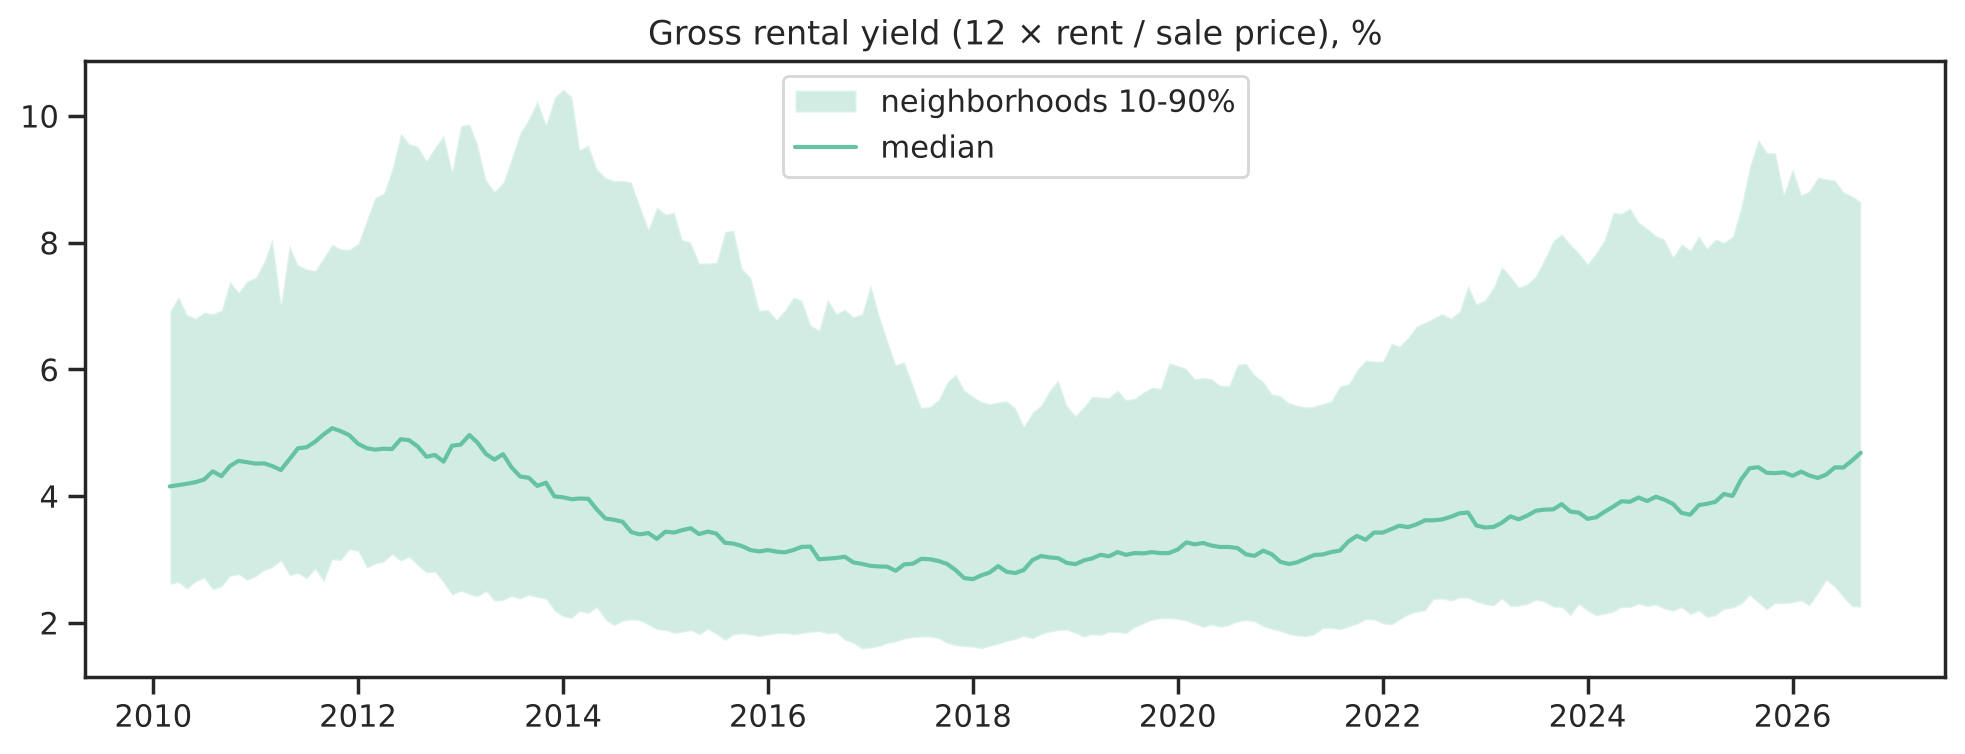

median yield now: 4.68 % | example: $3,000 rent -> 769 k price


In [40]:
d["sale_3m"] = np.exp(d.log_sale3)
d["yield"] = 12 * d.rent_3m / d.sale_3m
d["yield_vs_city"] = d["yield"] - d.groupby("date")["yield"].transform("median")
d["t_chg12"] = d.groupby("areaName").log_rent.shift(-12) - d.log_rent
d["t_sale_chg12"] = d.groupby("areaName").log_sale3.shift(-12) - d.log_sale3
d["past_chg12"] = d.log_rent - d.groupby("areaName").log_rent.shift(12)
d = d.replace([np.inf, -np.inf], np.nan)

q = d.groupby("date")["yield"].quantile([0.1, 0.5, 0.9]).unstack()
plt.figure(figsize=(12, 4))
plt.fill_between(q.index, q[0.1] * 100, q[0.9] * 100, alpha=0.3, label="neighborhoods 10-90%")
plt.plot(q.index, q[0.5] * 100, label="median")
plt.title("Gross rental yield (12 × rent / sale price), %")
plt.legend()
plt.show()
print("median yield now:", round(q[0.5].iloc[-1] * 100, 2), "% | example: $3,000 rent ->", round(12 * 3000 / q[0.5].iloc[-1] / 1000), "k price")

rows: 5480 | corr(rent growth, sale growth) = 0.10 | slope = 0.34 (1 = yield constant)


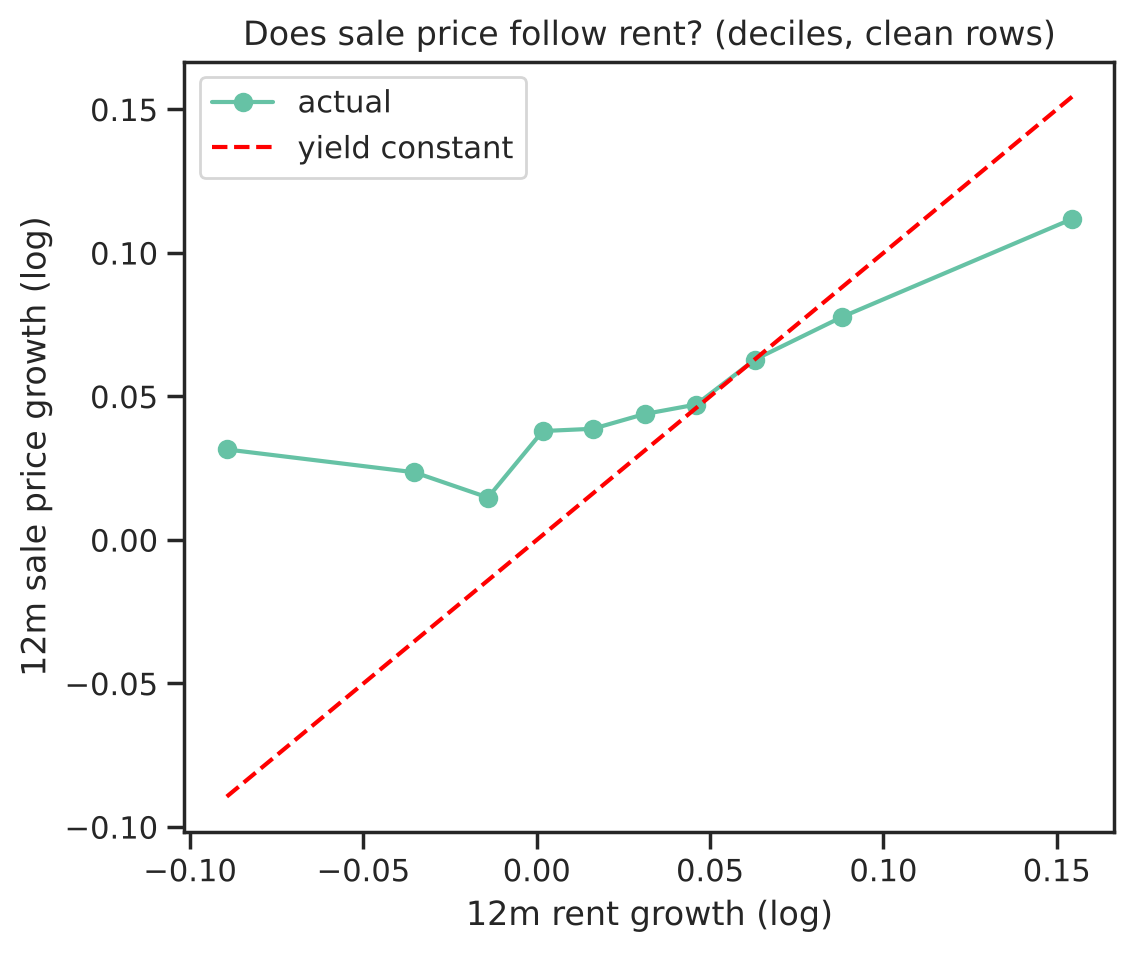

,t_chg12,t_sale_chg12
yield quintile (1 = lowest),,
1,0.0252,-0.0453
2,0.0195,0.0093
3,0.0232,0.0450
4,0.0338,0.0904
5,0.0291,0.1460


In [41]:
g = d[(d.date >= START) & (d.date < TEST_START - pd.DateOffset(months=12))].dropna(subset=["t_chg12", "t_sale_chg12"])
g = g[~covid_mask(g, 12)]
slope = np.polyfit(g.t_chg12, g.t_sale_chg12, 1)[0]
print(f"rows: {len(g)} | corr(rent growth, sale growth) = {g.t_chg12.corr(g.t_sale_chg12):.2f} | slope = {slope:.2f} (1 = yield constant)")

g["bin"] = pd.qcut(g.t_chg12, 10)
b = g.groupby("bin", observed=True)[["t_chg12", "t_sale_chg12"]].mean()
plt.figure(figsize=(6, 5))
plt.plot(b.t_chg12, b.t_sale_chg12, "o-", label="actual")
lim = [b.t_chg12.min(), b.t_chg12.max()]
plt.plot(lim, lim, "r--", label="yield constant")
plt.xlabel("12m rent growth (log)")
plt.ylabel("12m sale price growth (log)")
plt.title("Does sale price follow rent? (deciles, clean rows)")
plt.legend()
plt.show()

g["yq"] = g.groupby("date").yield_vs_city.transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False) + 1)
g.groupby("yq")[["t_chg12", "t_sale_chg12"]].mean().round(4).rename_axis("yield quintile (1 = lowest)")

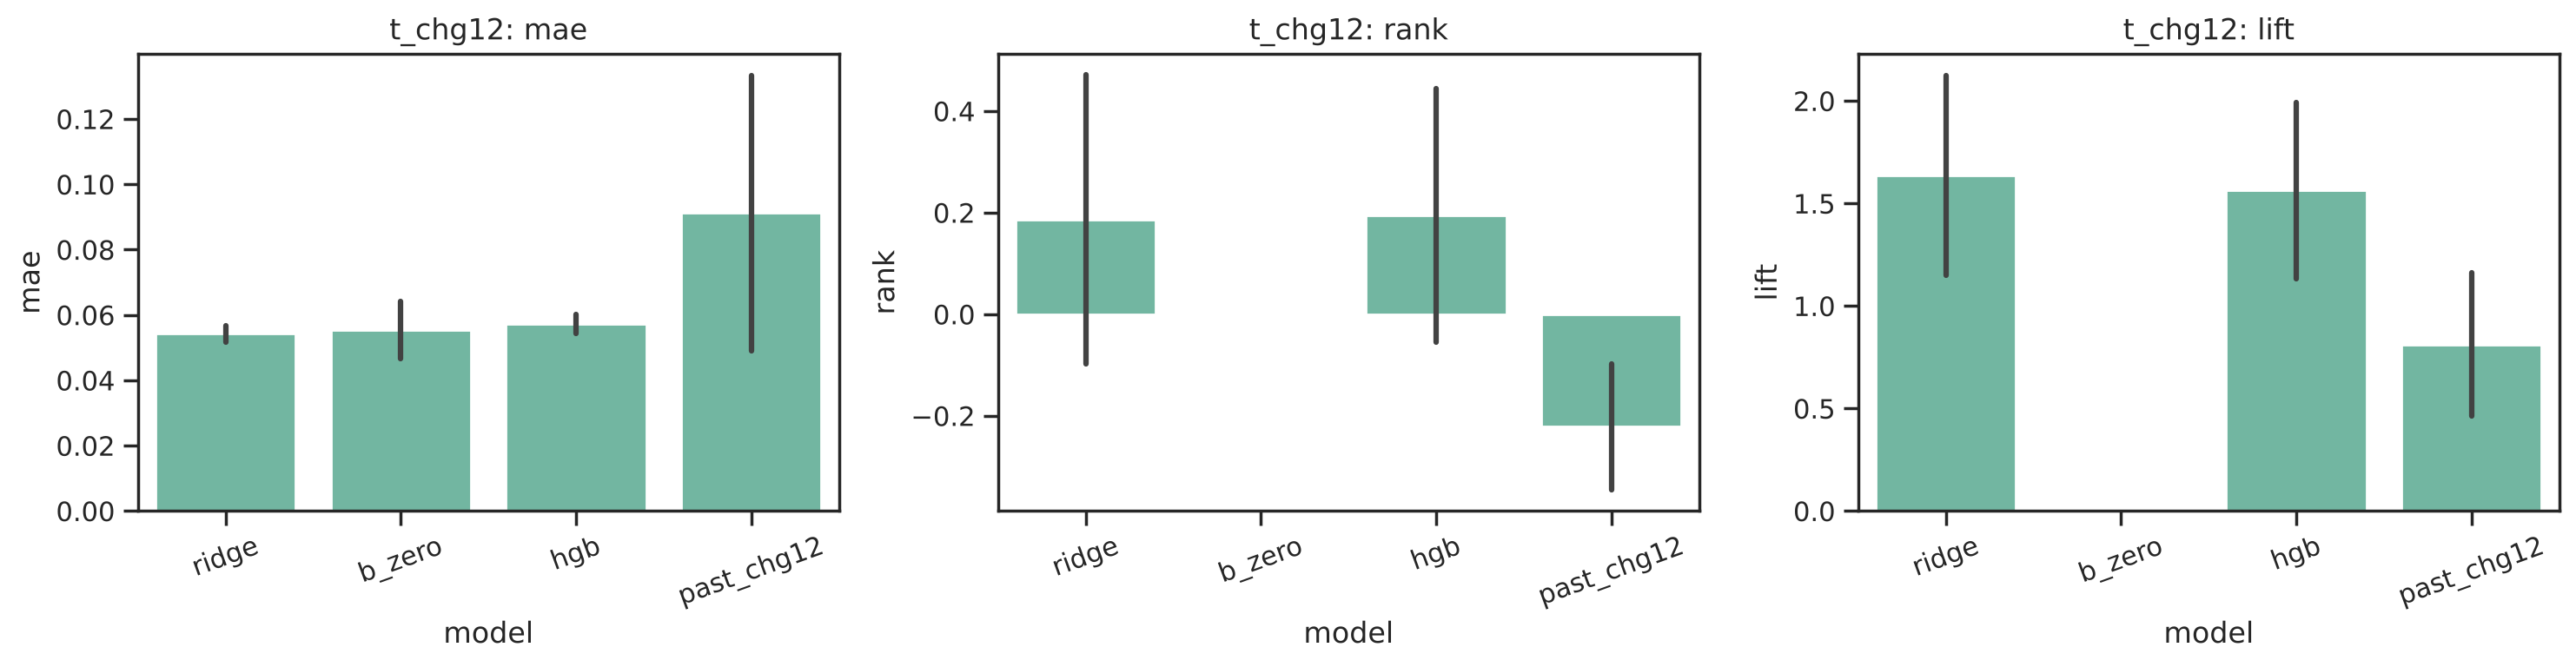

,mae,rank,sign_acc,lift
model,,,,
ridge,0.054,0.187,0.585,1.635
b_zero,0.055,NaN,0.005,NaN
hgb,0.057,0.195,0.577,1.562
past_chg12,0.091,-0.222,0.583,0.812


In [42]:
FLIP = ["past_chg12", "past_rel12", "mom3", "mom6", "rent_cut_share", "cut_vs_city", "log_inv", "inv_yoy_log",
        "rent_vs_boro", "yield", "yield_vs_city", "sale_rel12", "month"] + CITY + BORO
flip_rent = run_task("t_chg12", 12, FLIP, ["b_zero", "past_chg12"])
show_task(flip_rent)

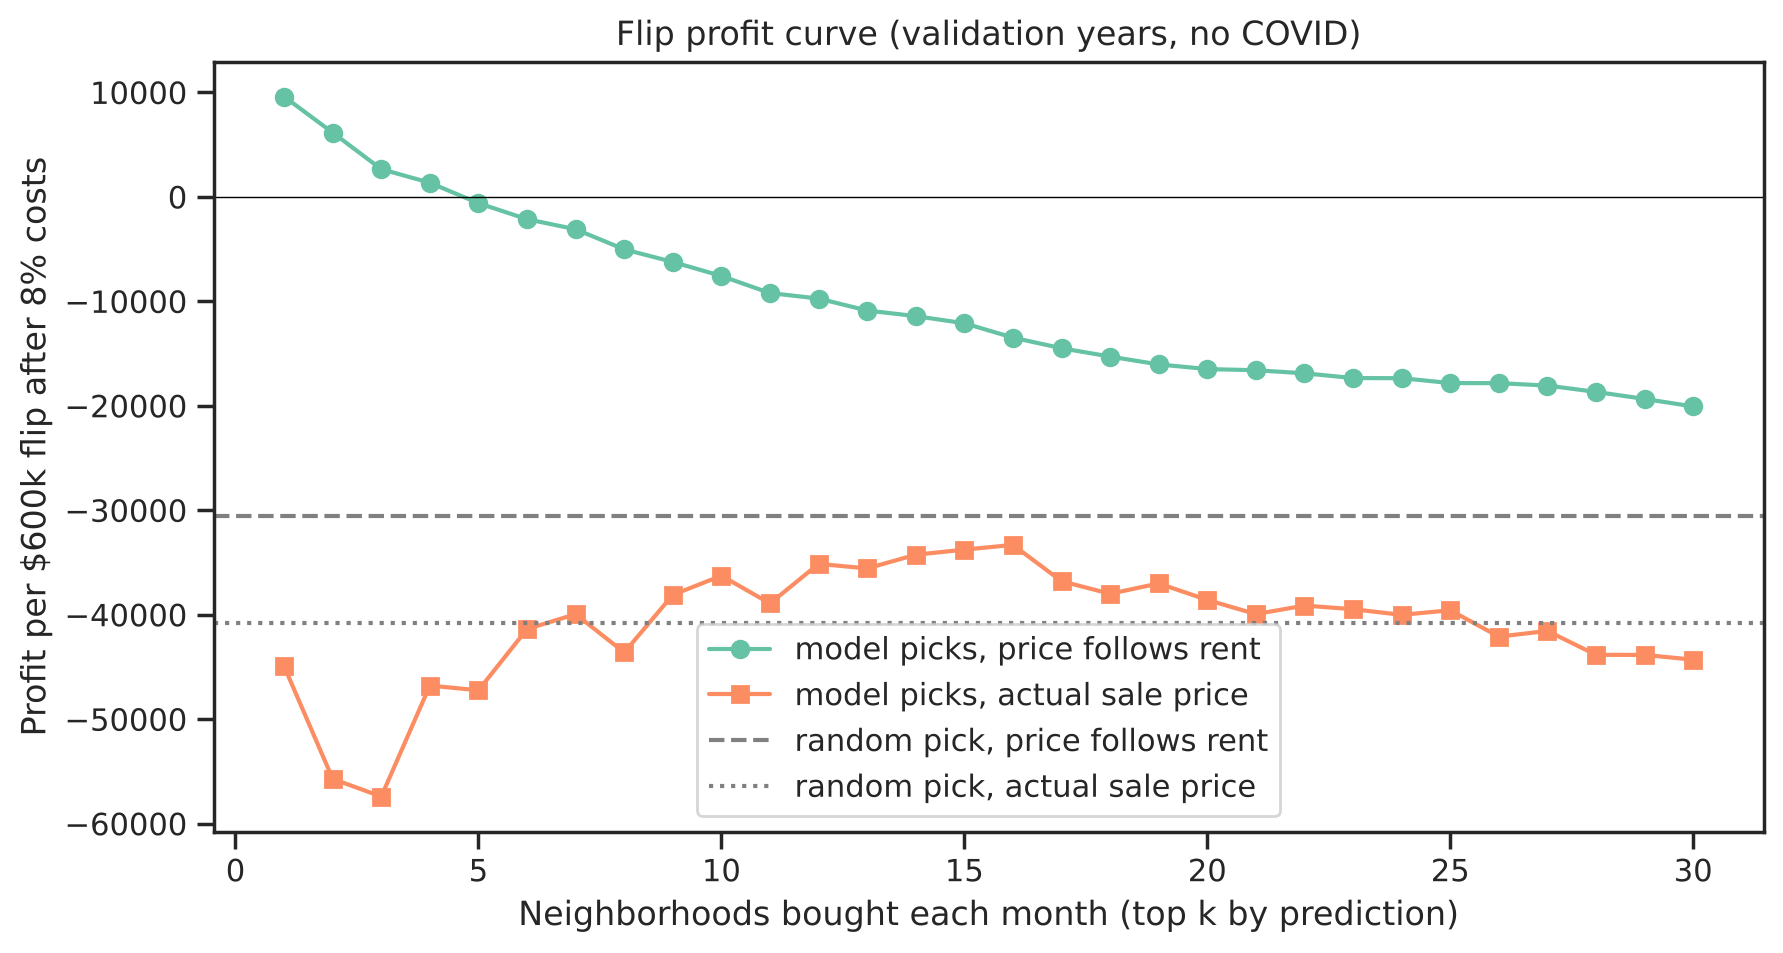

,k,rent_growth,sale_growth,profit_rent,profit_sale
0,1,0.091647,0.005080,9600.0,-44900.0
2,3,0.081029,-0.015829,2600.0,-57400.0
4,5,0.076010,0.001259,-600.0,-47200.0
9,10,0.065185,0.019355,-7600.0,-36300.0
19,20,0.051178,0.015555,-16500.0,-38600.0
29,30,0.045491,0.006124,-20100.0,-44300.0


In [43]:
def oof_task(target, h, feats, model_name="ridge", years=(2017, 2018, 2019, 2022), start=START):
    f = d[(d.date >= start) & (d.date < TEST_START - pd.DateOffset(months=h)) & d[target].notna()].reset_index(drop=True)
    f["covid"] = covid_mask(f, h)
    q1, q3 = f.loc[~f.covid, target].quantile([0.25, 0.75])
    f["out"] = (f[target] < q1 - 1.5 * (q3 - q1)) | (f[target] > q3 + 1.5 * (q3 - q1))
    out = []
    for y in years:
        st = pd.Timestamp(f"{y}-01-01")
        tr = f[(f.date < st - pd.DateOffset(months=h)) & ~f.covid & ~f.out]
        va = f[(f.date.dt.year == y) & ~f.covid].copy()
        va["pred"] = models("reg")[model_name].fit(tr[feats], tr[target]).predict(va[feats])
        out.append(va)
    return pd.concat(out)

PRICE = 600_000
COST = 0.08

flip_p = oof_task("t_chg12", 12, FLIP).dropna(subset=["t_sale_chg12"])
rows = []
for k in range(1, 31):
    top = flip_p.sort_values("pred", ascending=False).groupby("date").head(k)
    rows.append({"k": k, "rent_growth": top.t_chg12.mean(), "sale_growth": top.t_sale_chg12.mean()})
fc = pd.DataFrame(rows)
mkt_rent, mkt_sale = flip_p.t_chg12.mean(), flip_p.t_sale_chg12.mean()

usd = lambda gr: PRICE * (np.exp(gr) - 1) - PRICE * COST
plt.figure(figsize=(10, 5))
plt.plot(fc.k, usd(fc.rent_growth), "o-", label="model picks, price follows rent")
plt.plot(fc.k, usd(fc.sale_growth), "s-", label="model picks, actual sale price")
plt.axhline(usd(mkt_rent), color="gray", ls="--", label="random pick, price follows rent")
plt.axhline(usd(mkt_sale), color="gray", ls=":", label="random pick, actual sale price")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("Neighborhoods bought each month (top k by prediction)")
plt.ylabel(f"Profit per ${PRICE // 1000}k flip after {COST:.0%} costs")
plt.title("Flip profit curve (validation years, no COVID)")
plt.legend()
plt.show()

fc.assign(profit_rent=usd(fc.rent_growth).round(-2), profit_sale=usd(fc.sale_growth).round(-2)).query("k in [1, 3, 5, 10, 20, 30]")

### J2. Is the yield signal real or noise?

1. Profit curve when buying the highest-yield neighborhoods (vs a model that predicts sale growth directly).
2. Does it hold in neighborhoods with many listings?
3. Does a high yield that lasts 6 months work as well as a one-month spike?

rows: 3129


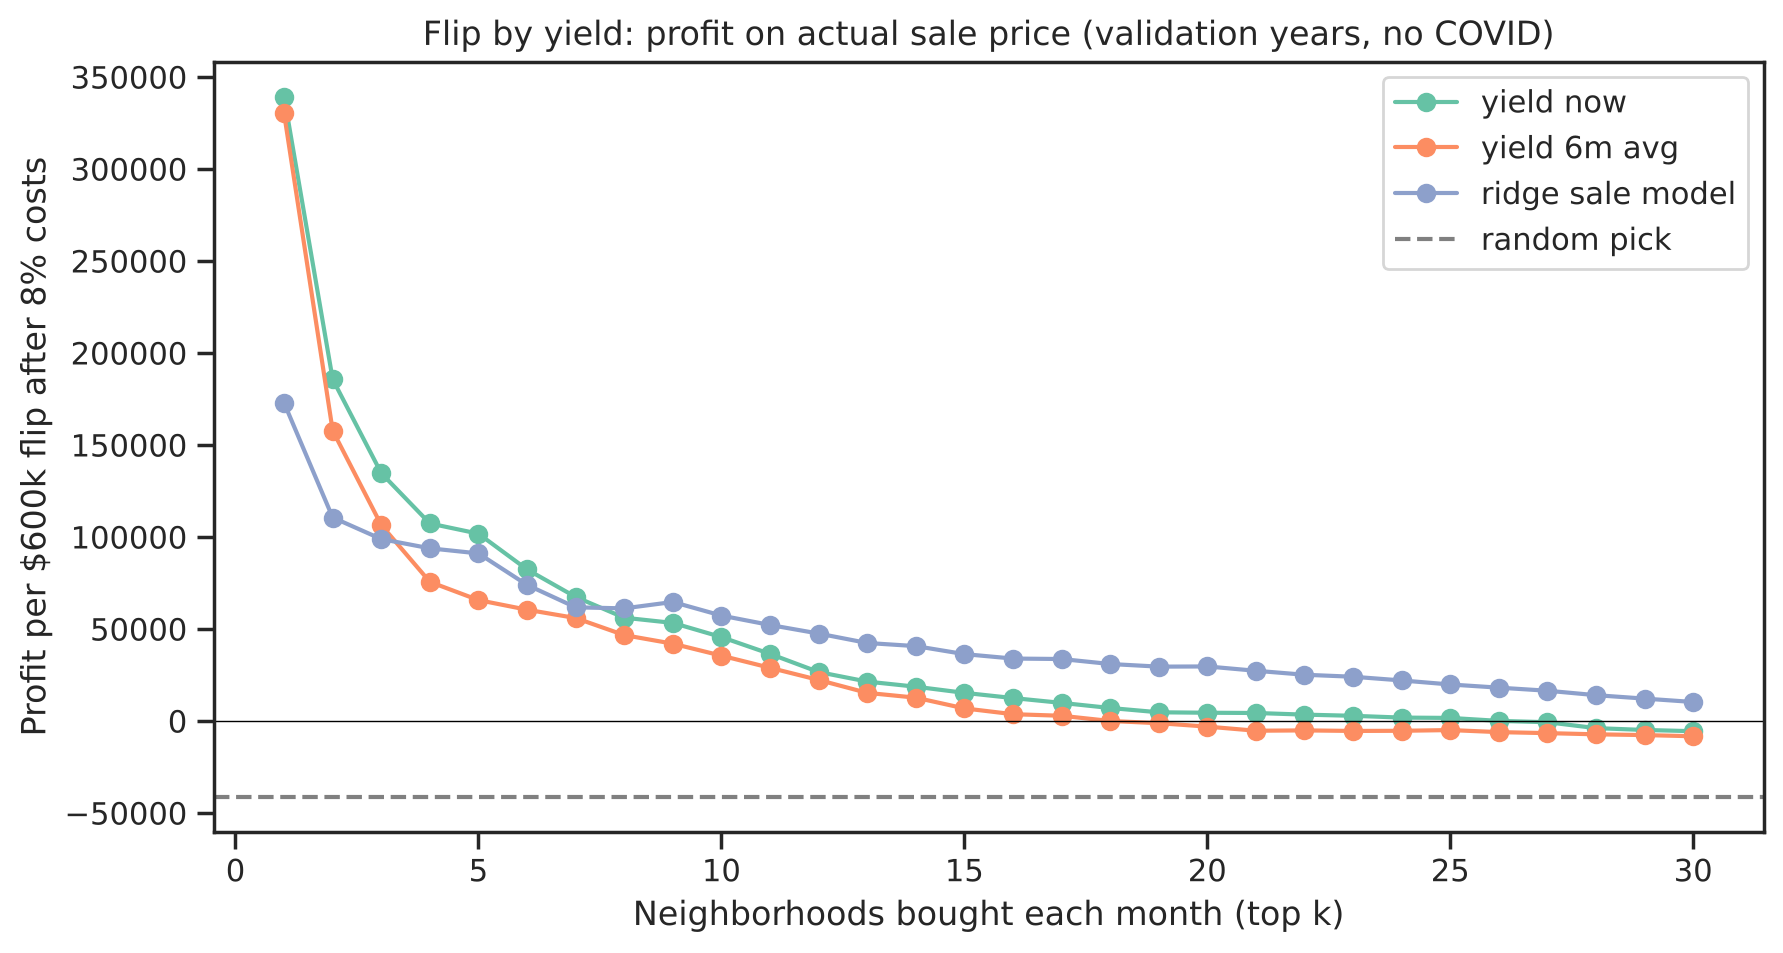

,yield now,yield 6m avg,ridge sale model
1,339300.0,330100.0,172800.0
3,134600.0,106400.0,98800.0
5,101700.0,65600.0,91000.0
10,45500.0,35400.0,57200.0
20,4400.0,-3100.0,29600.0
30,-5600.0,-8400.0,10300.0


In [44]:
def mq(s):
    return s.groupby(d.date).transform(lambda x: pd.qcut(x.rank(method="first"), 5, labels=False) + 1 if x.notna().sum() >= 5 else np.nan)

d["yvc_6m"] = d.groupby("areaName").yield_vs_city.transform(lambda s: s.rolling(6).mean())
d["yq"] = mq(d.yield_vs_city)
d["yq_lag6"] = d.groupby("areaName").yq.shift(6)
d["yq_6m"] = mq(d.yvc_6m)

YIELD_F = SALE + ["yield", "yield_vs_city", "yvc_6m"]
sale_p = oof_task("t_sale_chg12", 12, YIELD_F).dropna(subset=["yield_vs_city", "yvc_6m"])
print("rows:", len(sale_p))

def curve(frame, col, ks=range(1, 31)):
    return pd.Series({k: frame.sort_values(col, ascending=False).groupby("date").head(k).t_sale_chg12.mean() for k in ks})

curves = pd.DataFrame({"yield now": curve(sale_p, "yield_vs_city"),
                       "yield 6m avg": curve(sale_p, "yvc_6m"),
                       "ridge sale model": curve(sale_p, "pred")})
plt.figure(figsize=(10, 5))
for c in curves:
    plt.plot(curves.index, usd(curves[c]), "o-", label=c)
plt.axhline(usd(sale_p.t_sale_chg12.mean()), color="gray", ls="--", label="random pick")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("Neighborhoods bought each month (top k)")
plt.ylabel(f"Profit per ${PRICE // 1000}k flip after {COST:.0%} costs")
plt.title("Flip by yield: profit on actual sale price (validation years, no COVID)")
plt.legend()
plt.show()

usd(curves).round(-2).loc[[1, 3, 5, 10, 20, 30]]

In [45]:
top10 = sale_p.sort_values("yield_vs_city", ascending=False).groupby("date").head(10)
pd.DataFrame({"top10 by yield": top10.groupby(top10.date.dt.year).t_sale_chg12.mean(),
              "all": sale_p.groupby(sale_p.date.dt.year).t_sale_chg12.mean()}).round(3)

,top10 by yield,all
date,,
2017,0.276,0.037
2018,0.124,-0.021
2019,0.041,-0.014
2022,-0.041,0.034


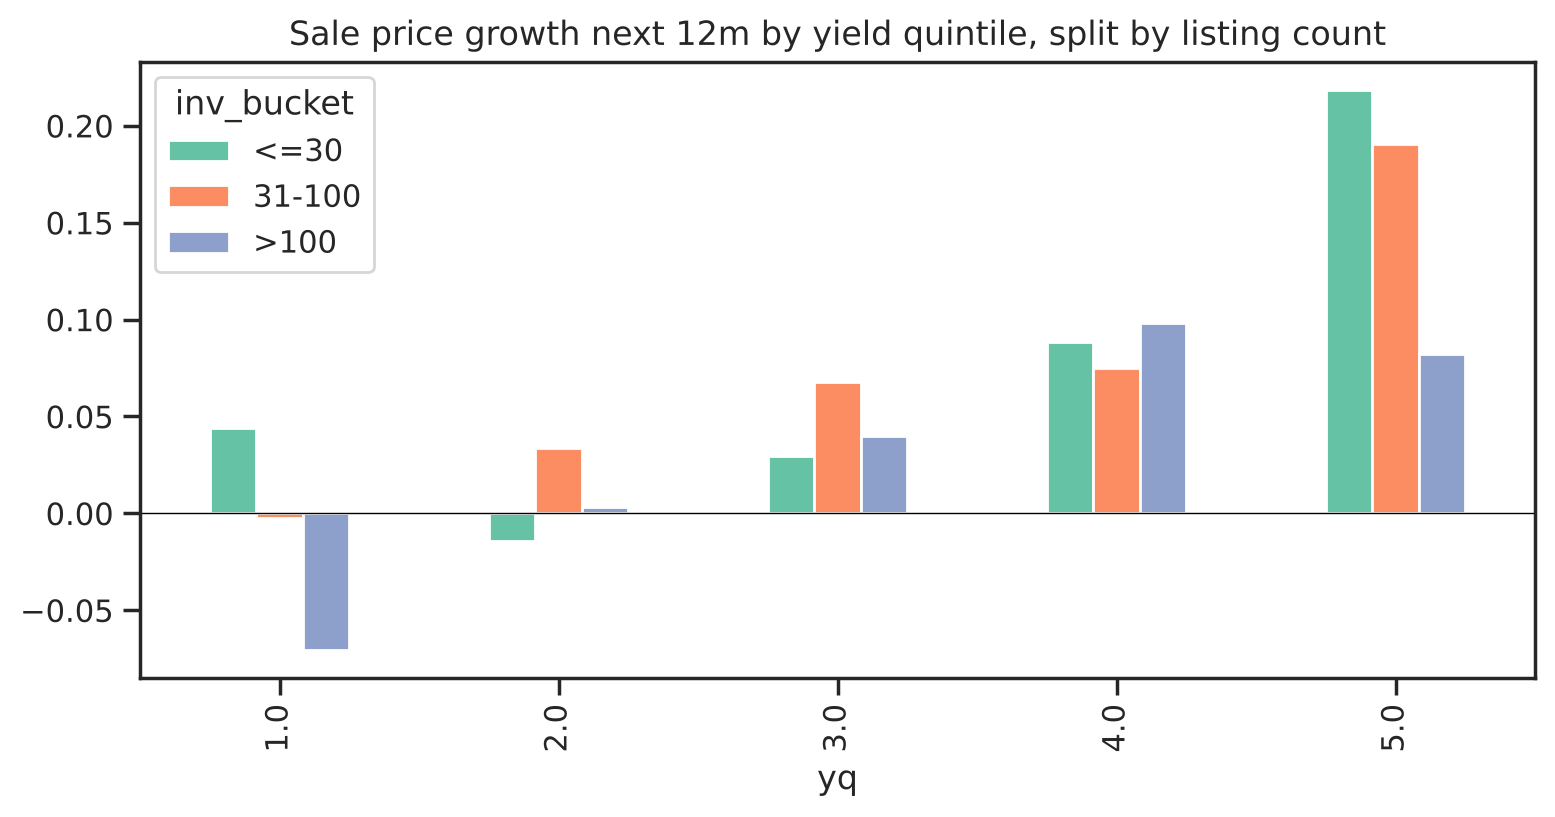

inv_bucket,<=30,31-100,>100,n_<=30,n_31-100,n_>100
yq,,,,,,
1.0,0.044,-0.002,-0.070,63,307,749
2.0,-0.014,0.033,0.003,47,235,795
3.0,0.030,0.068,0.040,102,261,738
4.0,0.089,0.075,0.098,120,315,636
5.0,0.219,0.191,0.082,136,481,495


In [46]:
g = d[(d.date >= START) & (d.date < TEST_START - pd.DateOffset(months=12))].dropna(subset=["t_sale_chg12", "yq"])
g = g[~covid_mask(g, 12)].copy()
g["inv_bucket"] = pd.cut(g.inventory, [-1, 30, 100, np.inf], labels=["<=30", "31-100", ">100"])
m = g.pivot_table(index="yq", columns="inv_bucket", values="t_sale_chg12", aggfunc="mean", observed=True)
m.plot(kind="bar", figsize=(9, 4), title="Sale price growth next 12m by yield quintile, split by listing count")
plt.axhline(0, color="k", lw=0.5)
plt.show()
pd.concat([m.round(3), g.pivot_table(index="yq", columns="inv_bucket", values="t_sale_chg12", aggfunc="size", observed=True).add_prefix("n_")], axis=1)

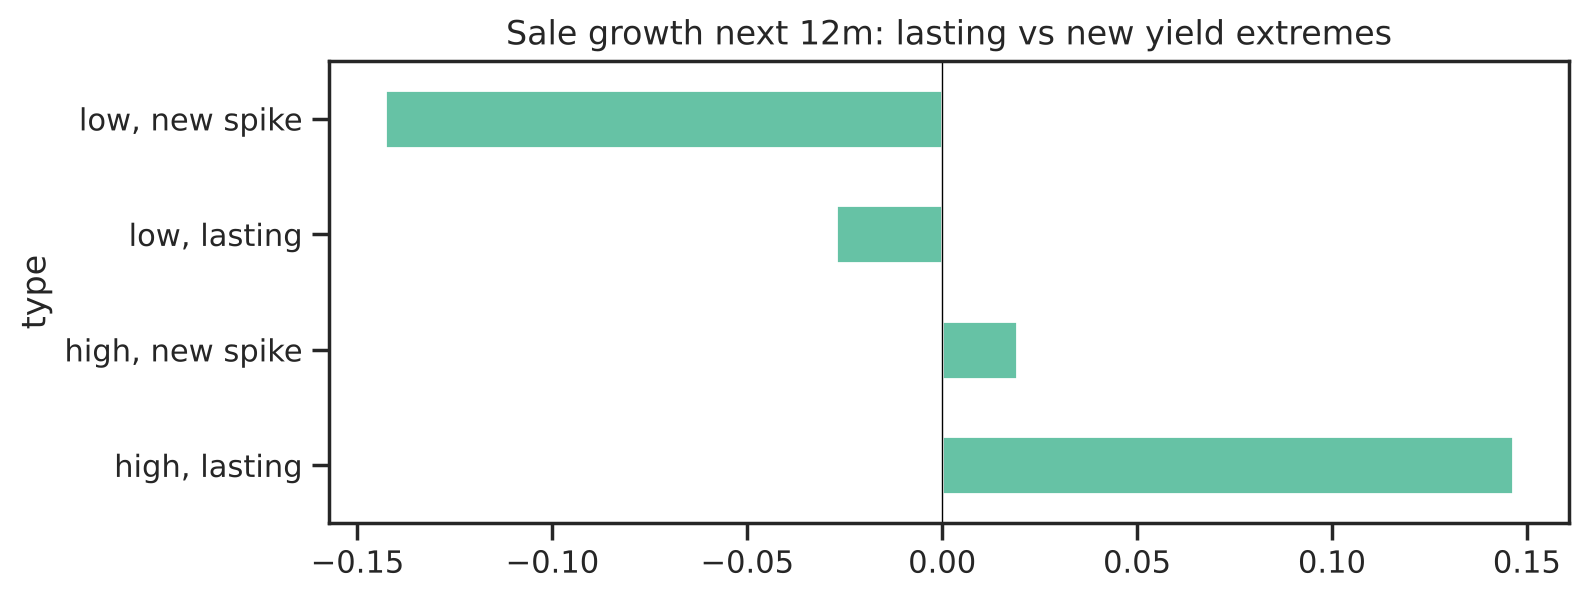

,sale_growth,rent_growth,rows
type,,,
"high, lasting",0.146,0.029,941
"high, new spike",0.019,-0.013,8
"low, lasting",-0.027,0.025,891
"low, new spike",-0.143,0.053,47


In [47]:
h = g.dropna(subset=["yq_lag6"]).copy()
h["type"] = np.select([(h.yq == 5) & (h.yq_lag6 == 5), (h.yq == 5) & (h.yq_lag6 <= 3), (h.yq == 1) & (h.yq_lag6 == 1), (h.yq == 1) & (h.yq_lag6 >= 3)],
                      ["high, lasting", "high, new spike", "low, lasting", "low, new spike"], "other")
t = h[h.type != "other"].groupby("type").agg(sale_growth=("t_sale_chg12", "mean"), rent_growth=("t_chg12", "mean"), rows=("t_sale_chg12", "size"))
t.sale_growth.plot(kind="barh", figsize=(8, 3), title="Sale growth next 12m: lasting vs new yield extremes")
plt.axvline(0, color="k", lw=0.5)
plt.show()
t.round(3)

In [48]:
g.groupby("yq_6m")[["t_sale_chg12", "t_chg12"]].mean().round(4).rename_axis("6m avg yield quintile")

,t_sale_chg12,t_chg12
6m avg yield quintile,,
1.0,-0.0245,0.0243
2.0,0.0156,0.0155
3.0,0.0456,0.0260
4.0,0.0715,0.0345
5.0,0.1369,0.0295


## H. Deeper look for the two chosen stories

`renter` = rent change over the next 3 months (`t_chg3`). `flip` = sale price change over the next 12 months (`t_sale_chg12`).
Same clean setup: no COVID windows, IQR outliers dropped from train, CV years 2017, 2018, 2019, 2022.

In [49]:
from sklearn.linear_model import Lasso
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve

TASKS = {"renter": ("t_chg3", 3, MARKET + CITY + BORO),
         "flip": ("t_sale_chg12", 12, YIELD_F)}
CV_YEARS = (2017, 2018, 2019, 2022)

def task_data(target, h):
    f = d[(d.date >= START) & d[target].notna()].reset_index(drop=True)
    f["covid"] = covid_mask(f, h)
    dev = f.date < TEST_START - pd.DateOffset(months=h)
    q1, q3 = f.loc[dev & ~f.covid, target].quantile([0.25, 0.75])
    f["out"] = (f[target] < q1 - 1.5 * (q3 - q1)) | (f[target] > q3 + 1.5 * (q3 - q1))
    f["end_month"] = (f.date.dt.month - 1 + h) % 12 + 1
    f["dev"] = dev
    return f

def cv_splits(f, h, years=CV_YEARS):
    out = []
    for y in years:
        st = pd.Timestamp(f"{y}-01-01")
        tr = np.where(f.dev & (f.date < st - pd.DateOffset(months=h)) & ~f.covid & ~f.out)[0]
        va = np.where(f.dev & (f.date.dt.year == y) & ~f.covid)[0]
        out.append((tr, va))
    return out

TD = {k: task_data(t, h) for k, (t, h, _) in TASKS.items()}
for k, f in TD.items():
    print(k, "| rows:", len(f), "| dev clean:", (f.dev & ~f.covid).sum(), "| test:", (~f.dev).sum())

renter | rows: 13800 | dev clean: 7400 | test: 3300
flip | rows: 12686 | dev clean: 5480 | test: 3260


### H1. Correlation scan over every numeric column

`within_month` = Spearman inside each month (averaged). `beyond_base` = same, but against what is left after the base signal
(renter: borough × month average = seasonality; flip: `yield_vs_city`).

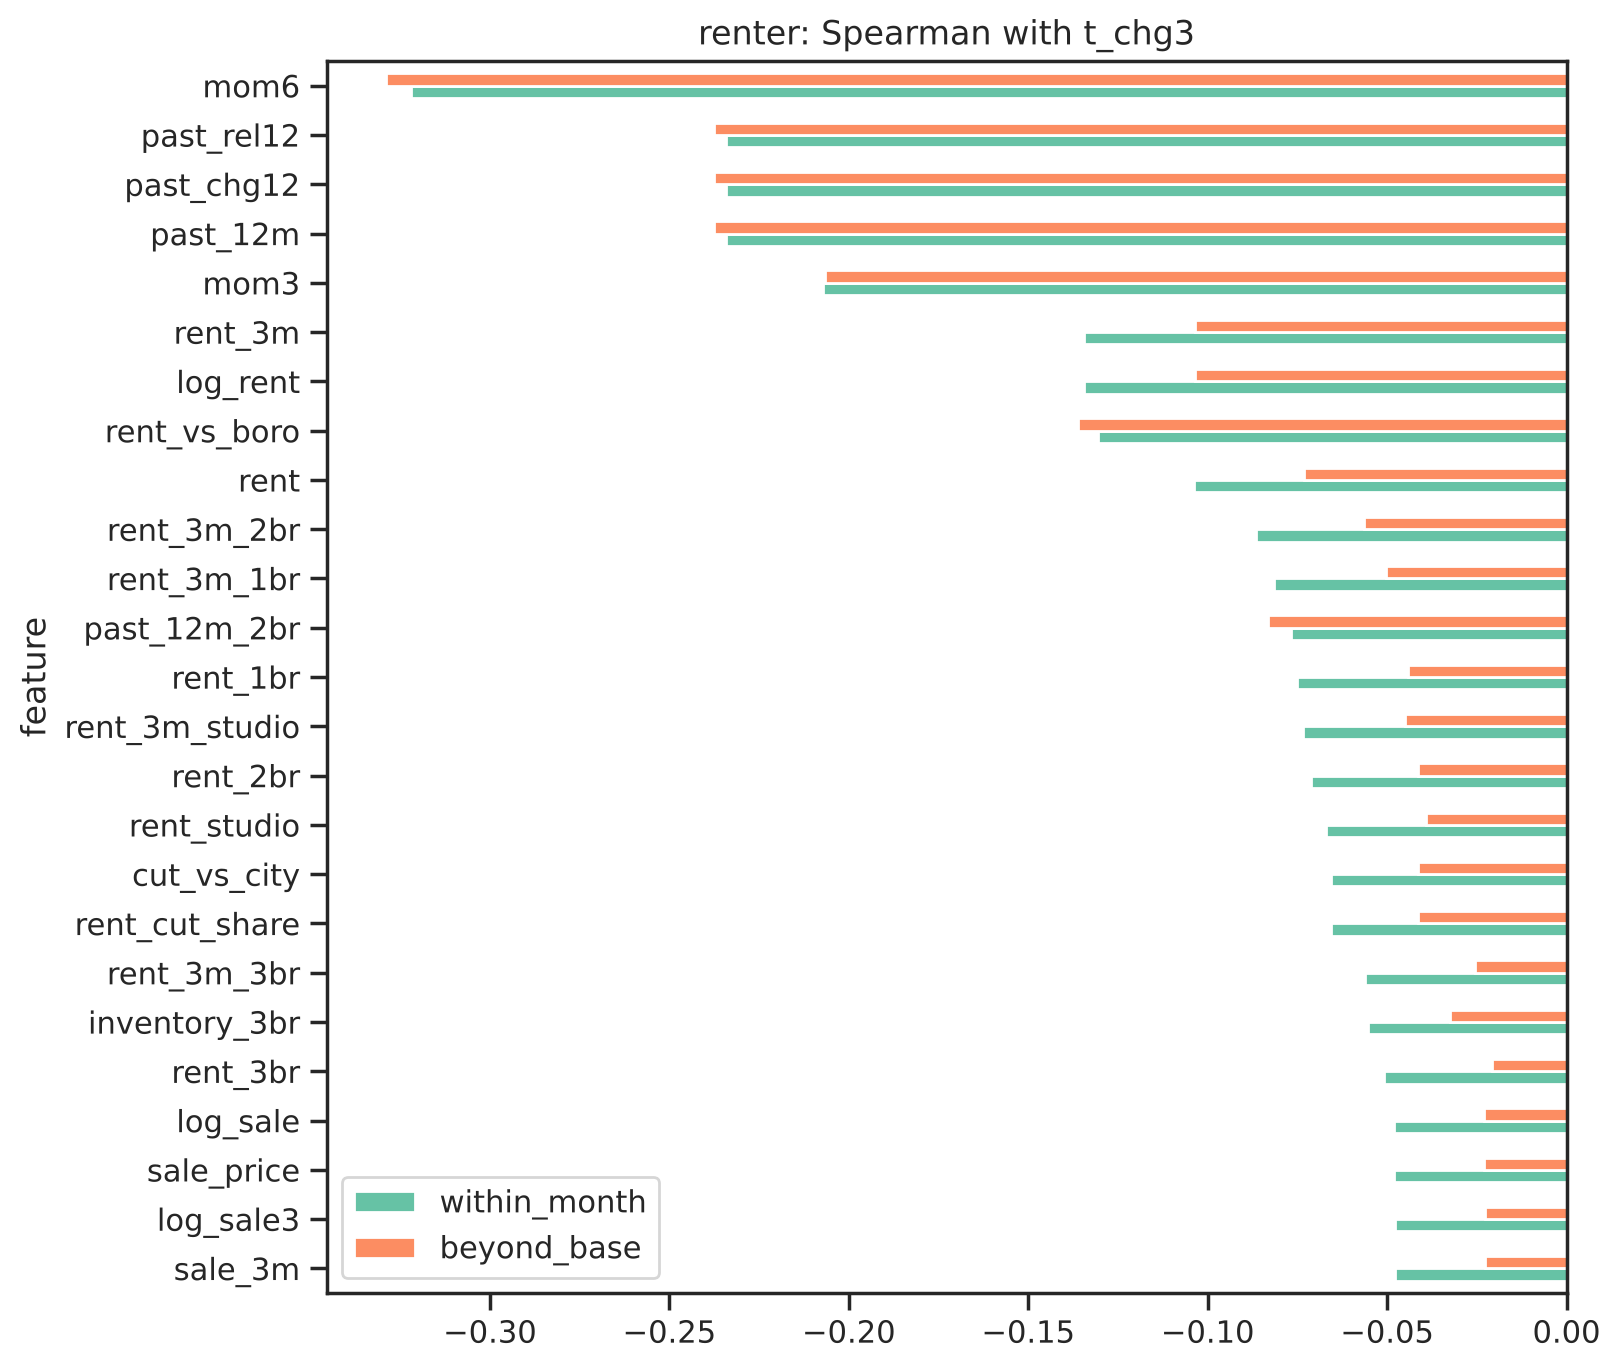

,feature,within_month,beyond_base
46,mom6,-0.322,-0.329
47,past_rel12,-0.234,-0.238
60,past_chg12,-0.234,-0.238
9,past_12m,-0.234,-0.238
45,mom3,-0.207,-0.207
8,rent_3m,-0.135,-0.103
42,log_rent,-0.135,-0.103
52,rent_vs_boro,-0.130,-0.136
3,rent,-0.104,-0.073
34,rent_3m_2br,-0.086,-0.056


In [50]:
EXCL = {"in_model", "covid_period", "eviction_moratorium", "covid_win", "clean", "outlier", "fair_gap", "yq", "yq_lag6", "yq_6m",
        "month", "members"}

def scan(task, base):
    target, h, _ = TASKS[task]
    f = TD[task]
    f = f[f.dev & ~f.covid].copy()
    if base == "season":
        f["resid"] = f[target] - f.groupby(["date", "Borough"])[target].transform("mean")
    else:
        f["resid"] = np.nan
        for _, x in f.dropna(subset=[base]).groupby("date"):
            b = np.polyfit(x[base], x[target], 1)
            f.loc[x.index, "resid"] = x[target] - np.polyval(b, x[base])
    cols = [c for c in f.select_dtypes("number").columns
            if not c.startswith(("t_", "b_", "boro_")) and c not in EXCL and c not in {"resid", "end_month"}]
    rows = []
    for c in cols:
        w = [spearmanr(x[c], x[target], nan_policy="omit")[0] for _, x in f.groupby("date") if x[c].nunique() > 2]
        r = [spearmanr(x[c], x.resid, nan_policy="omit")[0] for _, x in f.groupby("date") if x[c].nunique() > 2]
        rows.append({"feature": c, "within_month": np.nanmean(w) if w else np.nan, "beyond_base": np.nanmean(r) if r else np.nan})
    t = pd.DataFrame(rows).dropna(subset=["within_month"])
    t = t.reindex(t.within_month.abs().sort_values(ascending=False).index).head(25)
    t.set_index("feature")[::-1].plot(kind="barh", figsize=(8, 8), title=f"{task}: Spearman with {target}")
    plt.axvline(0, color="k", lw=0.5)
    plt.show()
    return t.round(3)

scan("renter", "season")

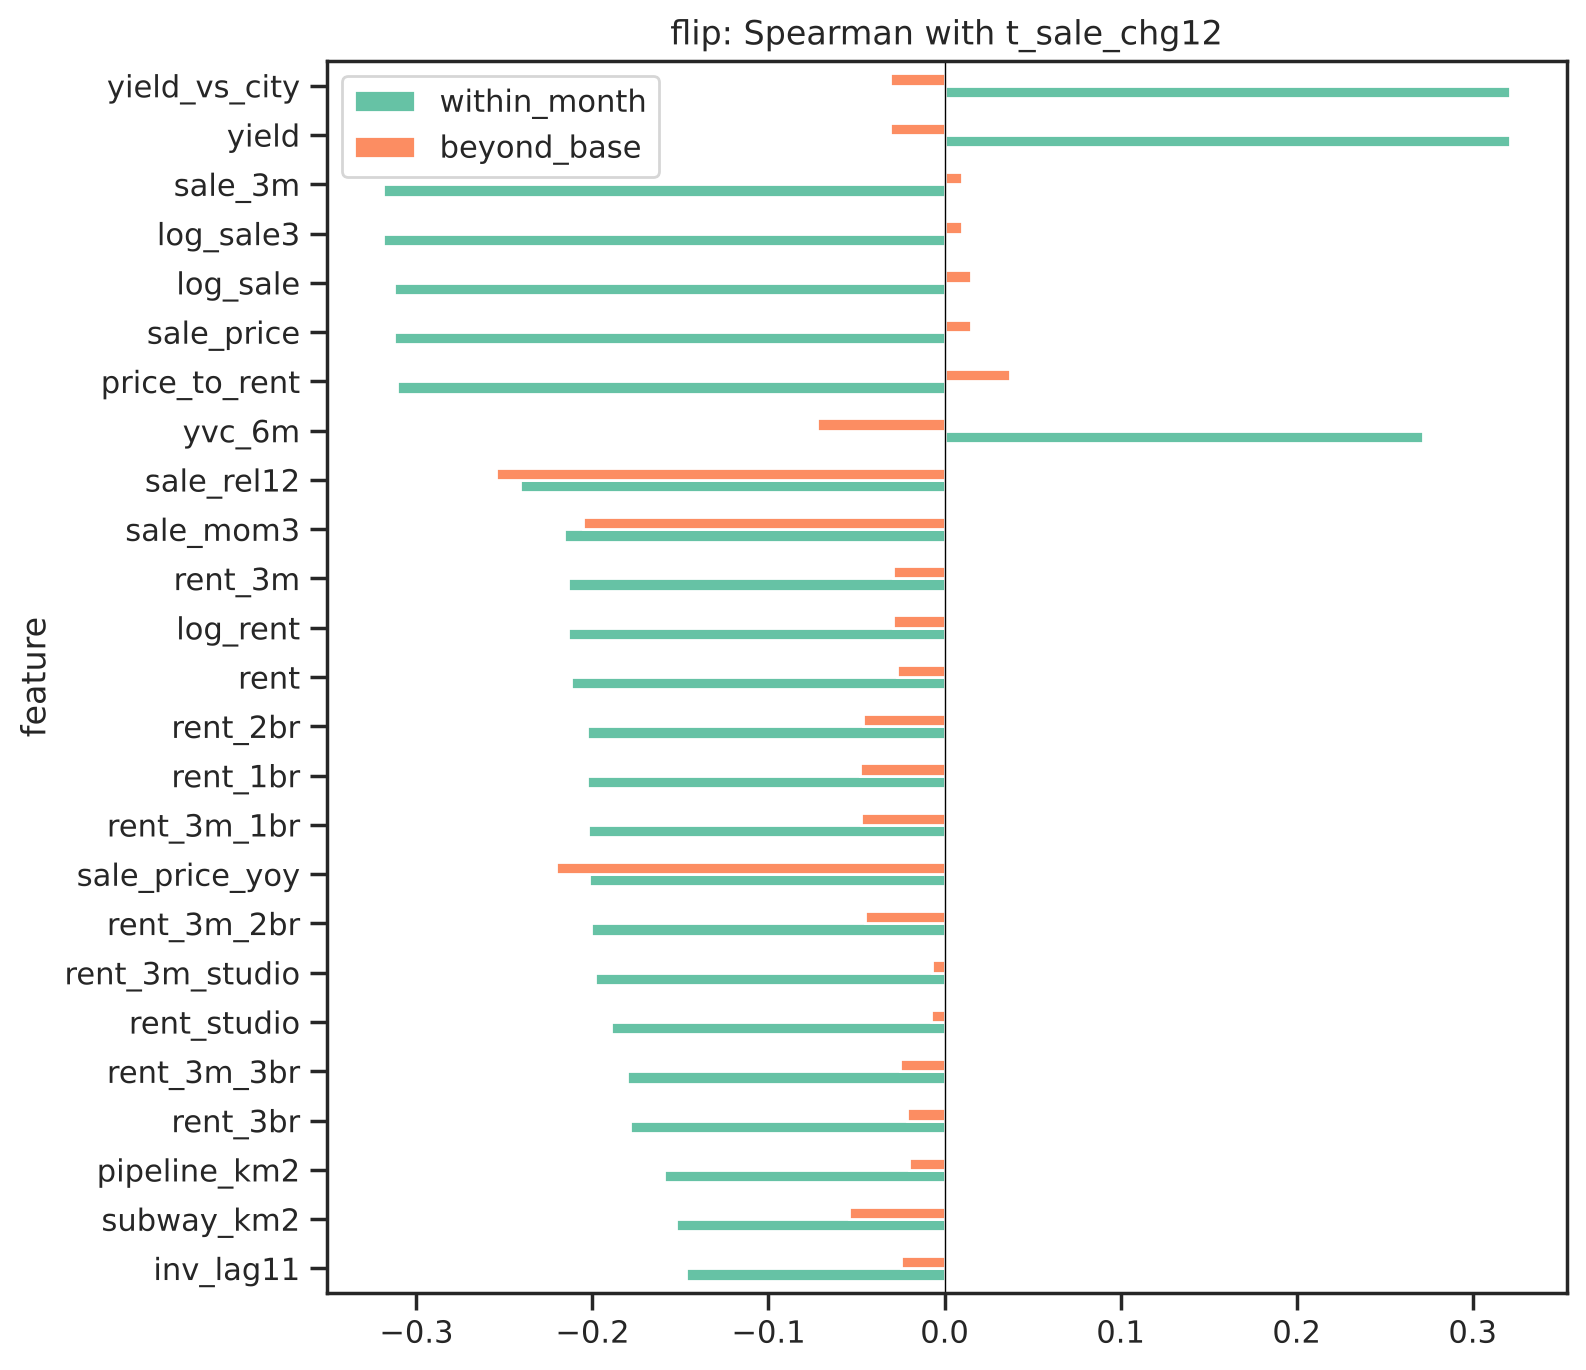

,feature,within_month,beyond_base
59,yield_vs_city,0.321,-0.031
58,yield,0.321,-0.031
57,sale_3m,-0.319,0.010
53,log_sale3,-0.319,0.010
44,log_sale,-0.313,0.015
6,sale_price,-0.313,0.015
12,price_to_rent,-0.311,0.037
61,yvc_6m,0.272,-0.072
55,sale_rel12,-0.241,-0.255
56,sale_mom3,-0.216,-0.206


In [51]:
scan("flip", "yield_vs_city")

### H2. Decision tree: complexity curve and the tree itself

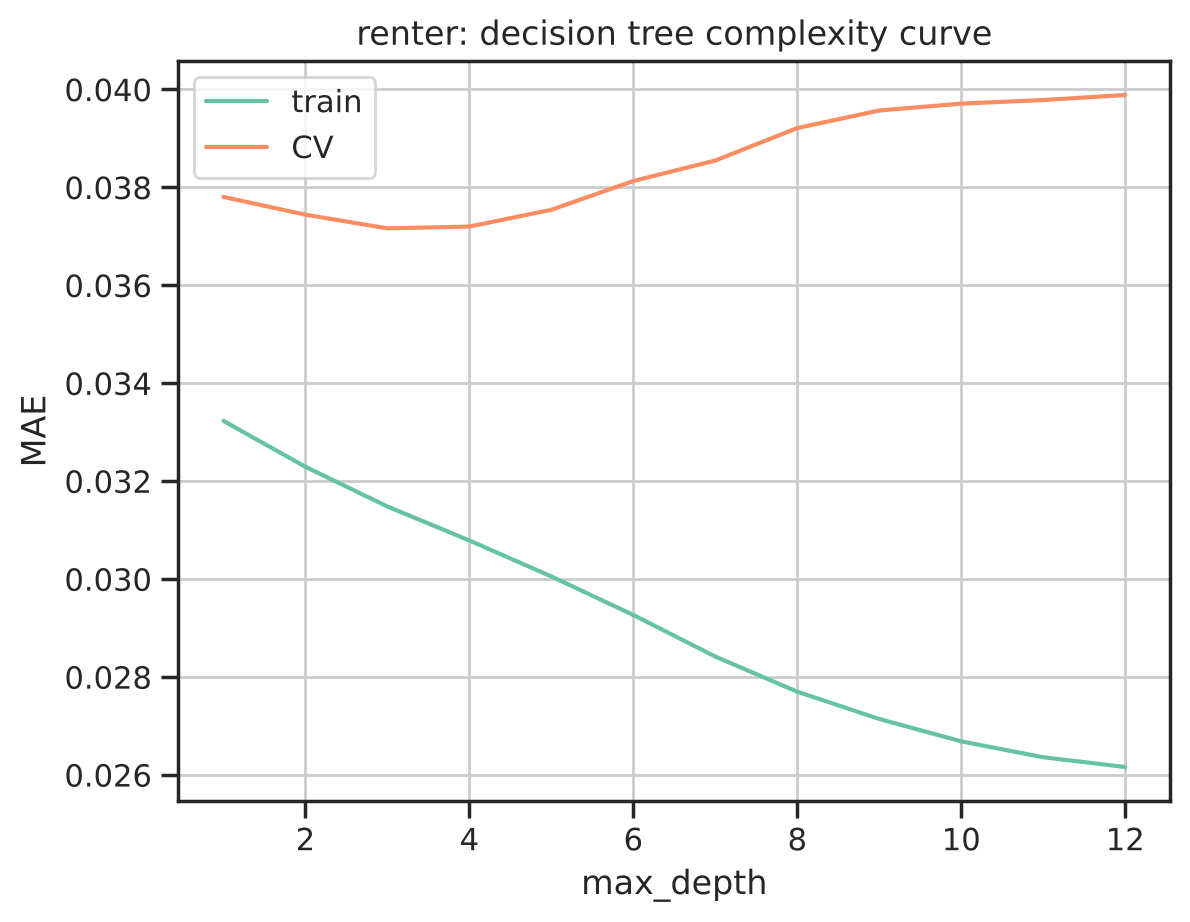

,depth,train_mae,cv_mae
0,1,0.0332,0.0378
1,2,0.0323,0.0374
2,3,0.0315,0.0372
3,4,0.0308,0.0372
4,5,0.0301,0.0375
5,6,0.0293,0.0381
6,7,0.0284,0.0385
7,8,0.0277,0.0392
8,9,0.0271,0.0396
9,10,0.0267,0.0397


In [52]:
def mae_cv(task, make, depth_param=None):
    target, h, feats = TASKS[task]
    f = TD[task]
    tr_s, va_s = [], []
    for tr, va in cv_splits(f, h):
        m = make().fit(f.loc[tr, feats], f.loc[tr, target])
        tr_s.append(mean_absolute_error(f.loc[tr, target], m.predict(f.loc[tr, feats])))
        va_s.append(mean_absolute_error(f.loc[va, target], m.predict(f.loc[va, feats])))
    return np.mean(tr_s), np.mean(va_s)

def tree_curve(task, depths=range(1, 13)):
    r = pd.DataFrame([(dp, *mae_cv(task, lambda: make_pipeline(SimpleImputer(strategy="median"),
                     DecisionTreeRegressor(max_depth=dp, min_samples_leaf=20, random_state=13))))
                      for dp in depths], columns=["depth", "train_mae", "cv_mae"])
    plt.plot(r.depth, r.train_mae, label="train")
    plt.plot(r.depth, r.cv_mae, label="CV")
    plt.xlabel("max_depth")
    plt.ylabel("MAE")
    plt.title(f"{task}: decision tree complexity curve")
    plt.legend()
    plt.grid()
    plt.show()
    return r.round(4)

tree_curve("renter")

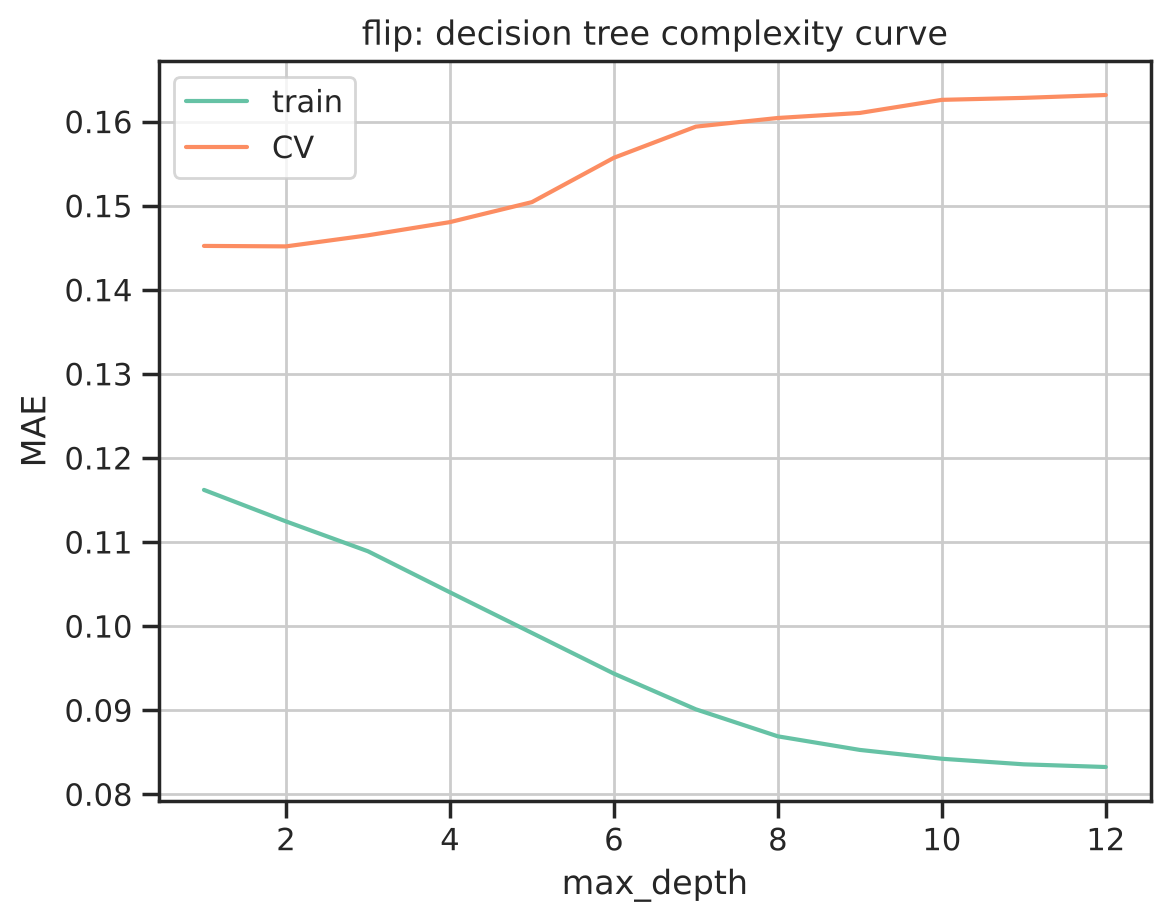

,depth,train_mae,cv_mae
0,1,0.1162,0.1452
1,2,0.1124,0.1451
2,3,0.1089,0.1465
3,4,0.1040,0.1480
4,5,0.0992,0.1504
5,6,0.0943,0.1557
6,7,0.0901,0.1594
7,8,0.0869,0.1604
8,9,0.0853,0.1610
9,10,0.0842,0.1626


In [53]:
tree_curve("flip")

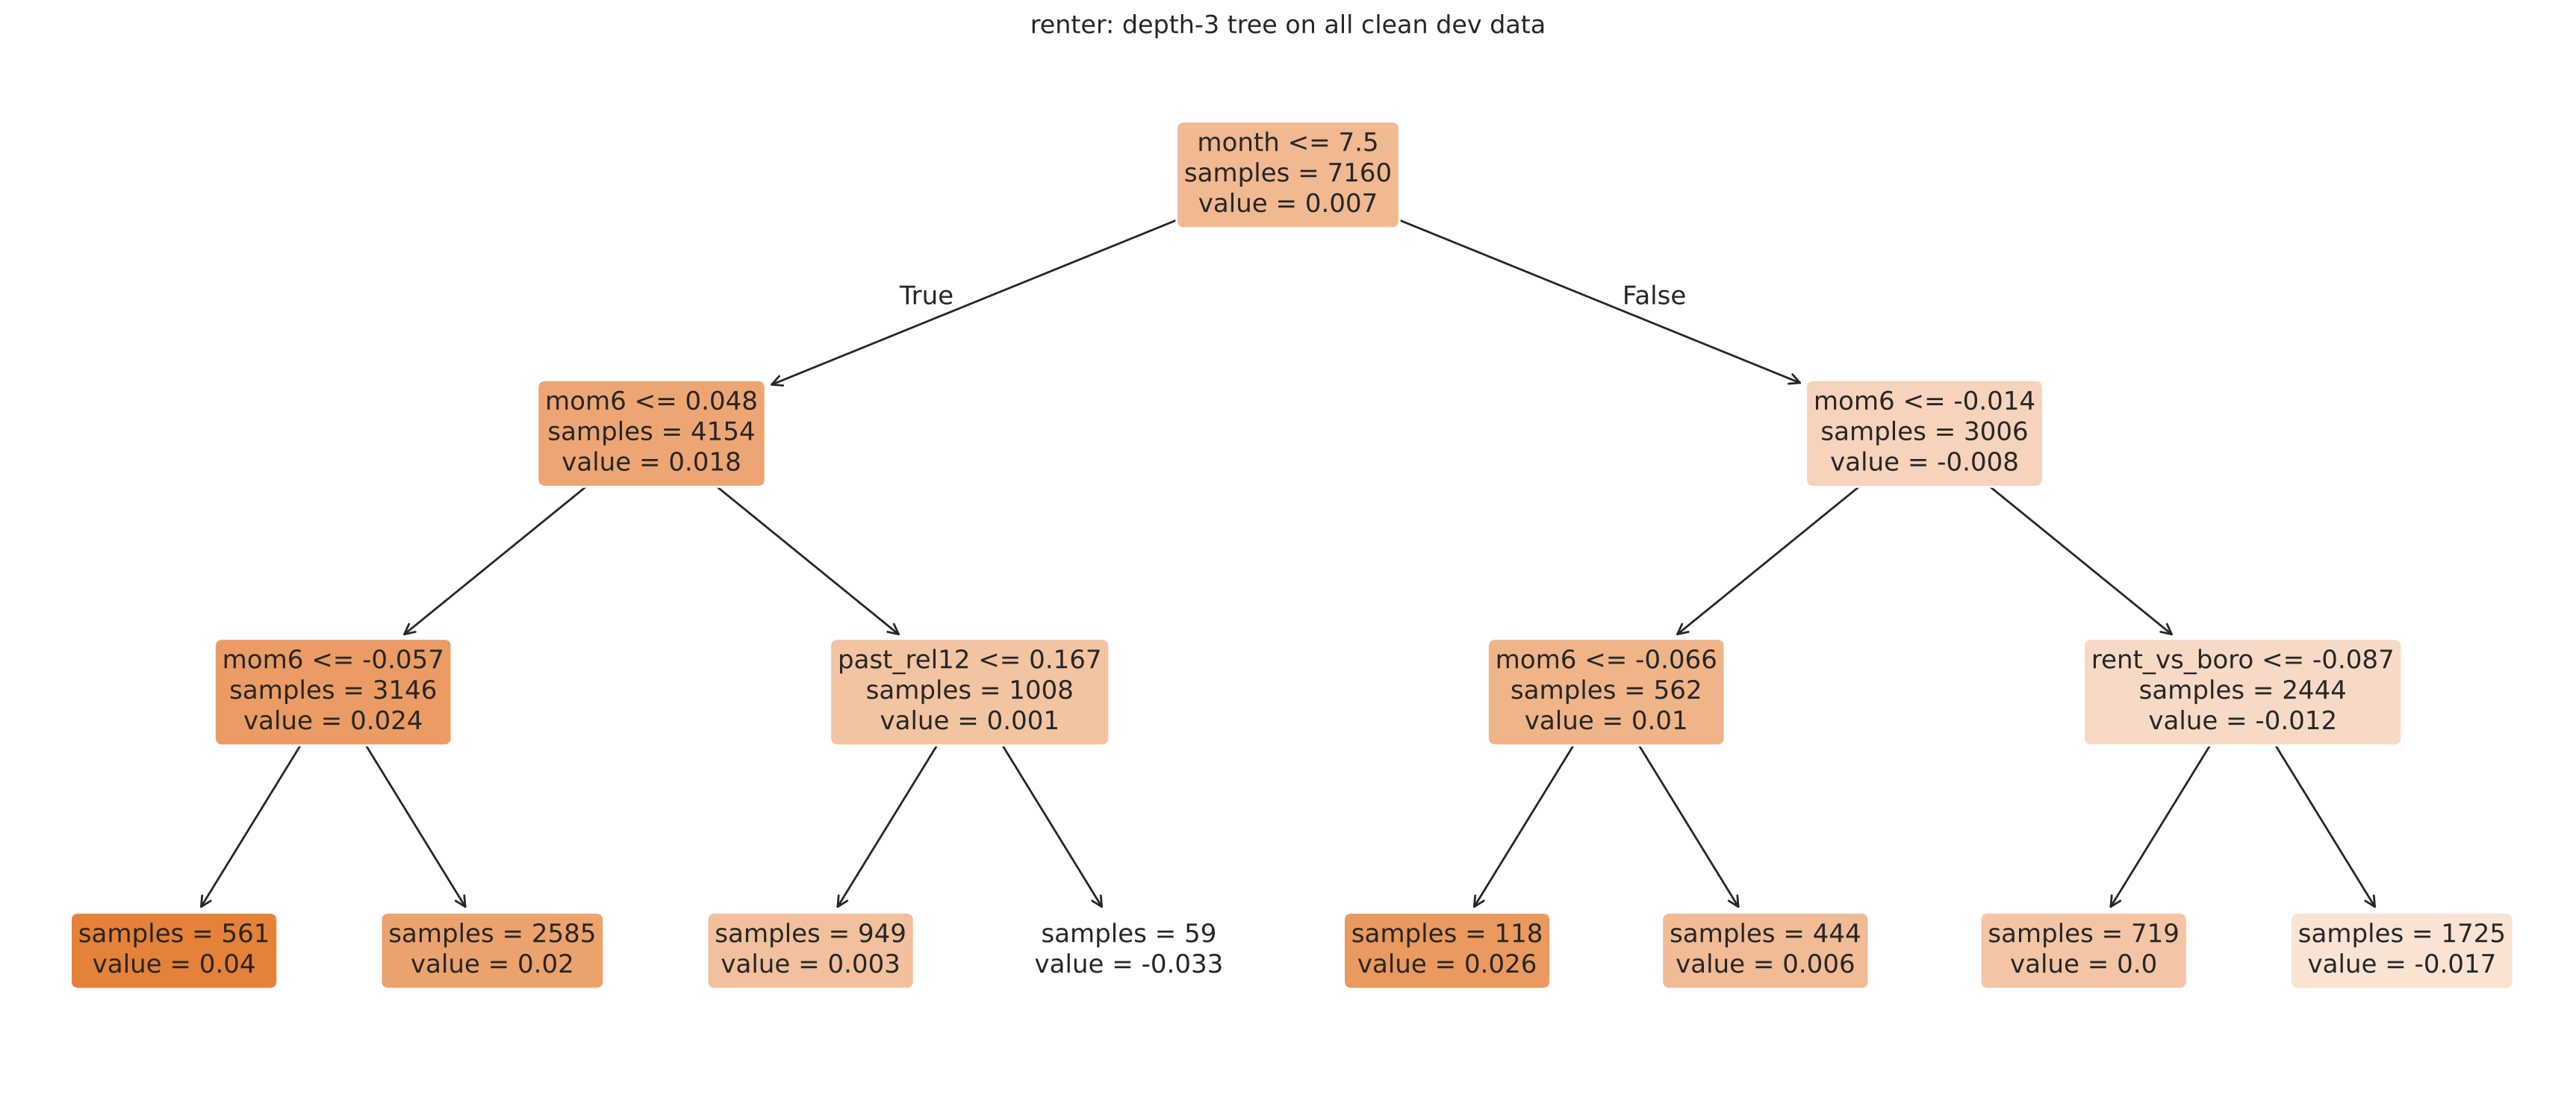

In [54]:
def show_tree(task, depth=3):
    target, h, feats = TASKS[task]
    f = TD[task]
    tr = f[f.dev & ~f.covid & ~f.out]
    X = tr[feats].fillna(tr[feats].median())
    m = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=50, random_state=13).fit(X, tr[target])
    plt.figure(figsize=(22, 9))
    plot_tree(m, feature_names=feats, filled=True, impurity=False, rounded=True, precision=3)
    plt.title(f"{task}: depth-{depth} tree on all clean dev data")
    plt.show()

show_tree("renter")

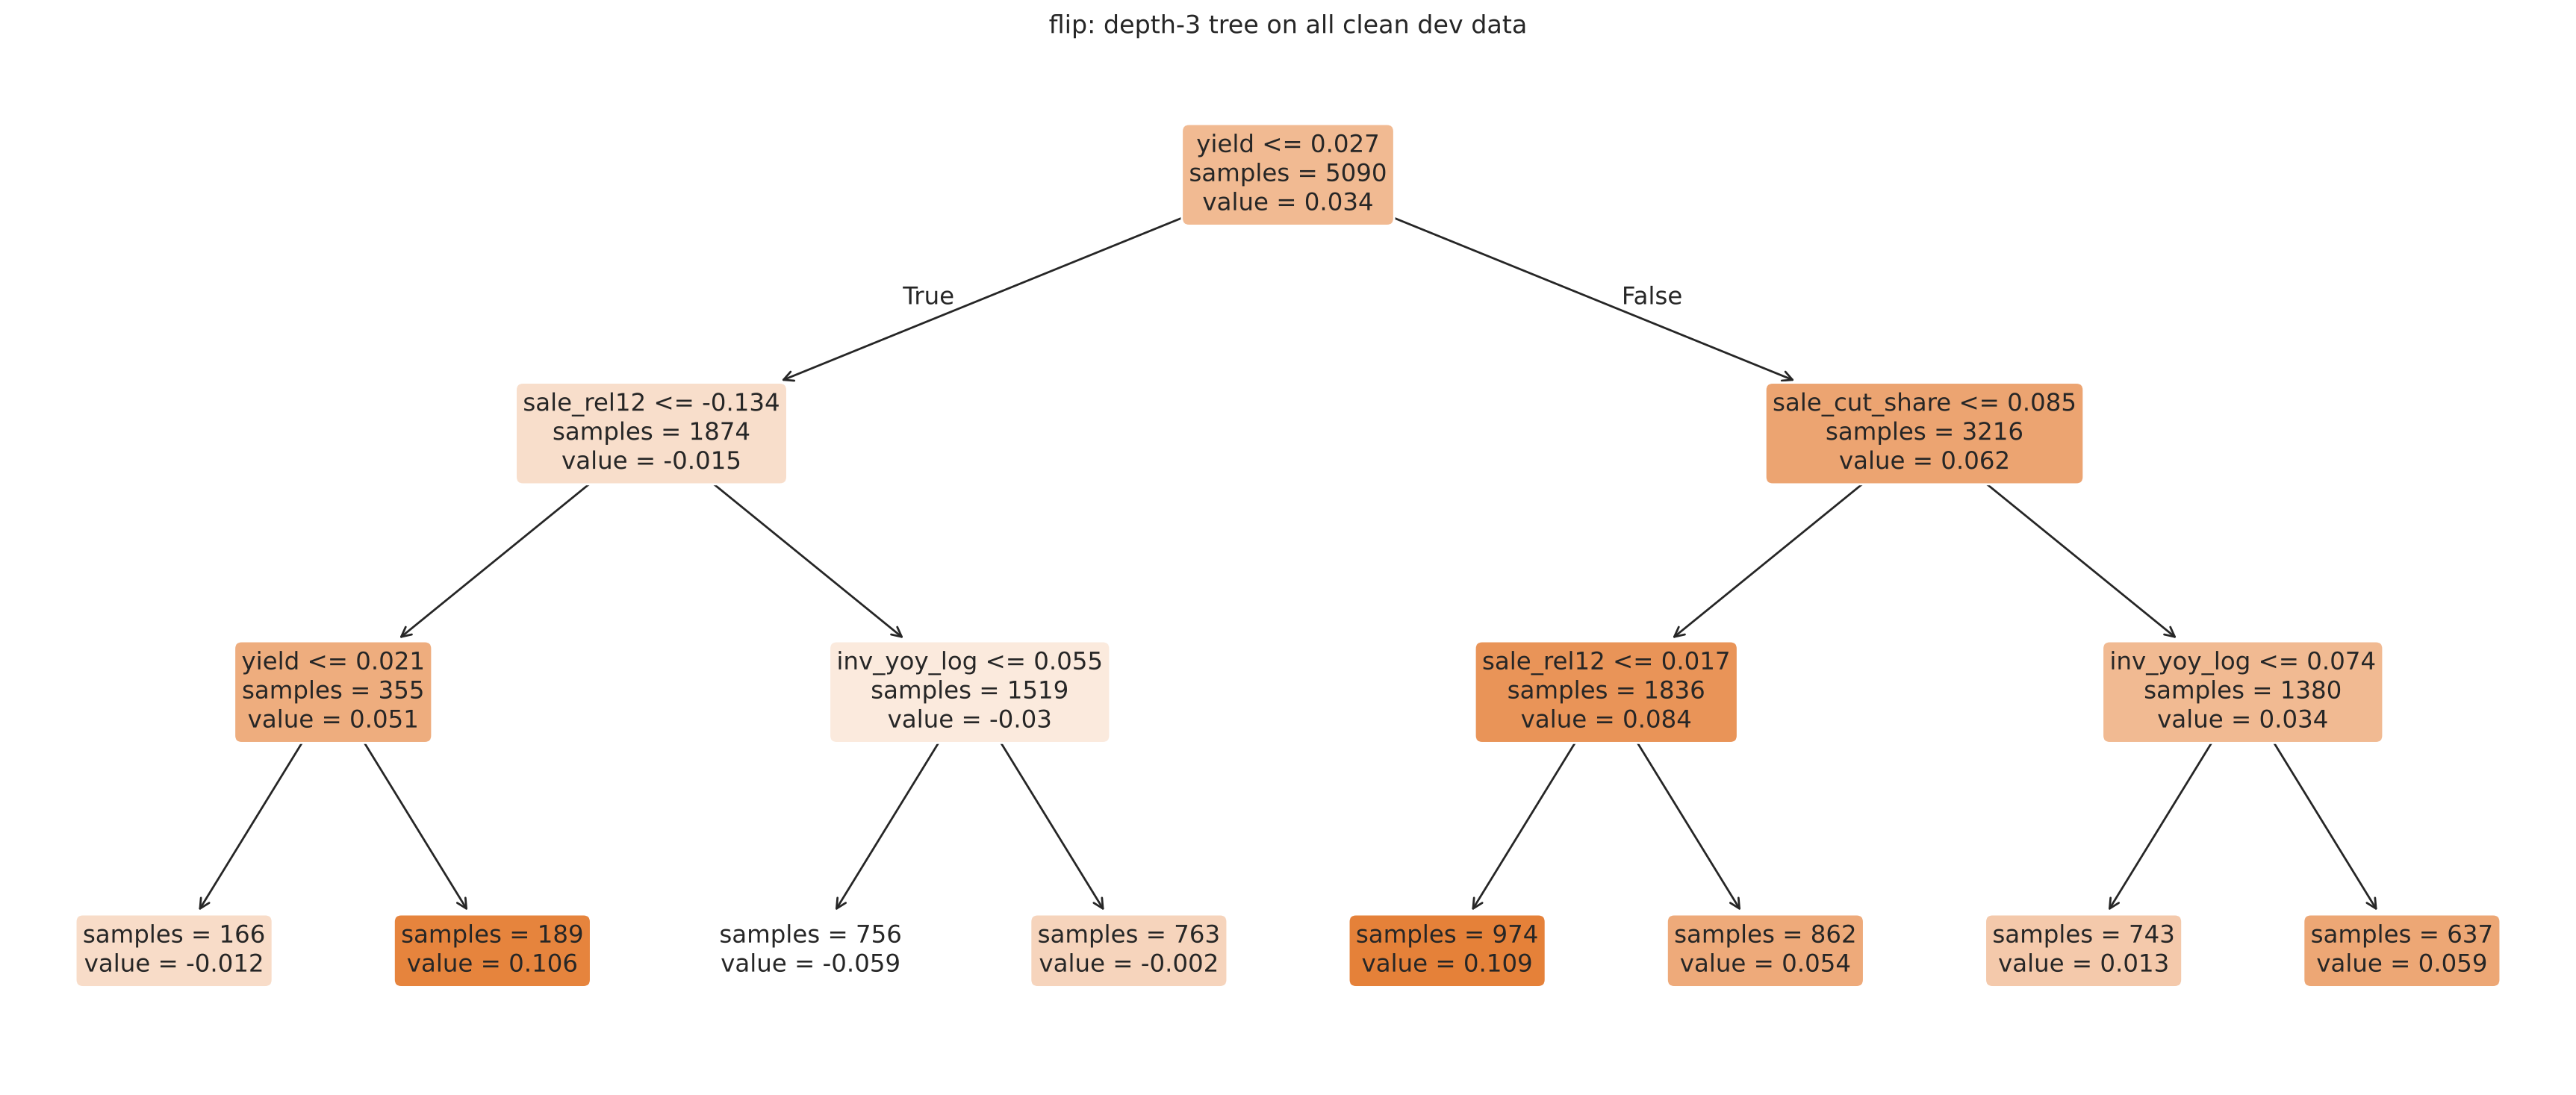

In [55]:
show_tree("flip")

### H3. Ridge and Lasso: alpha curves

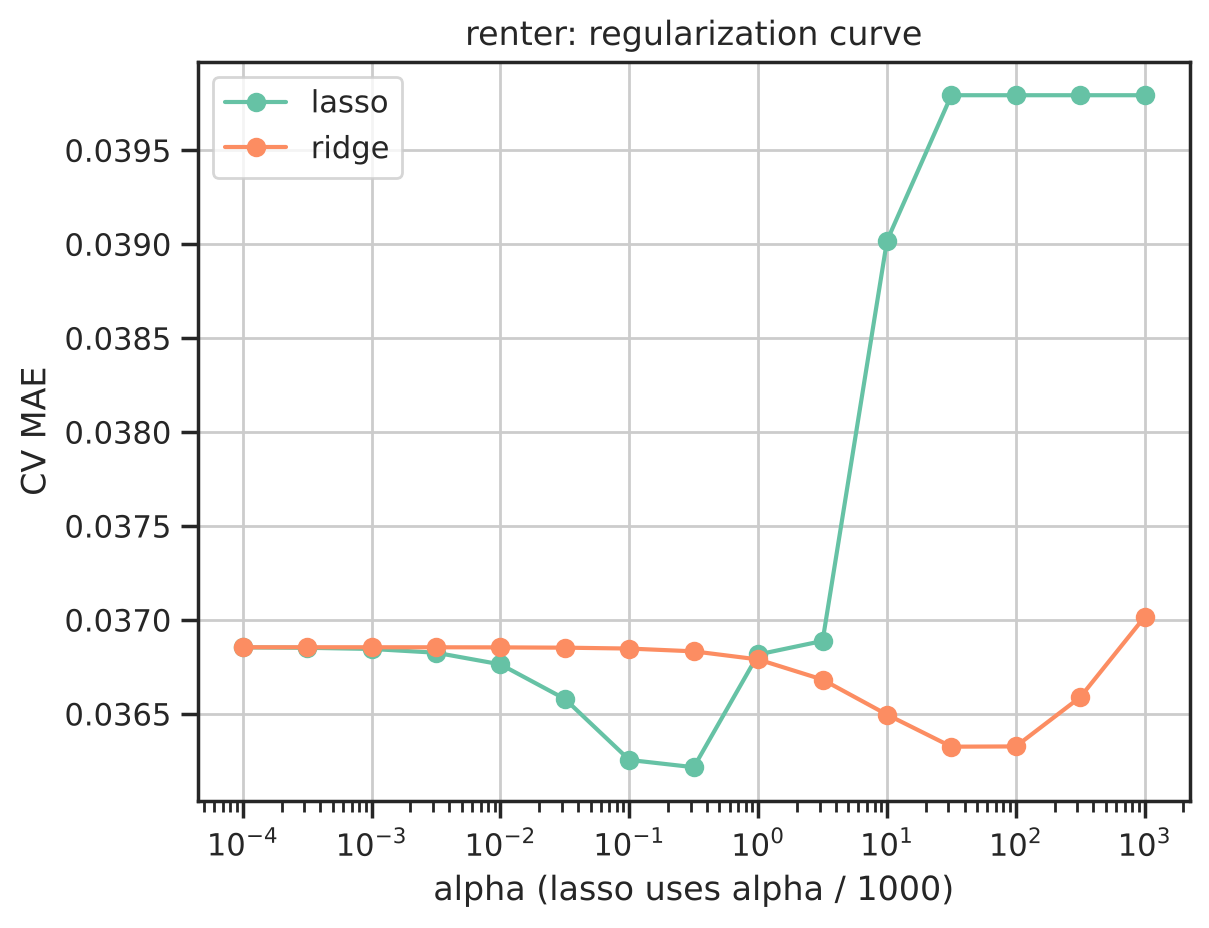

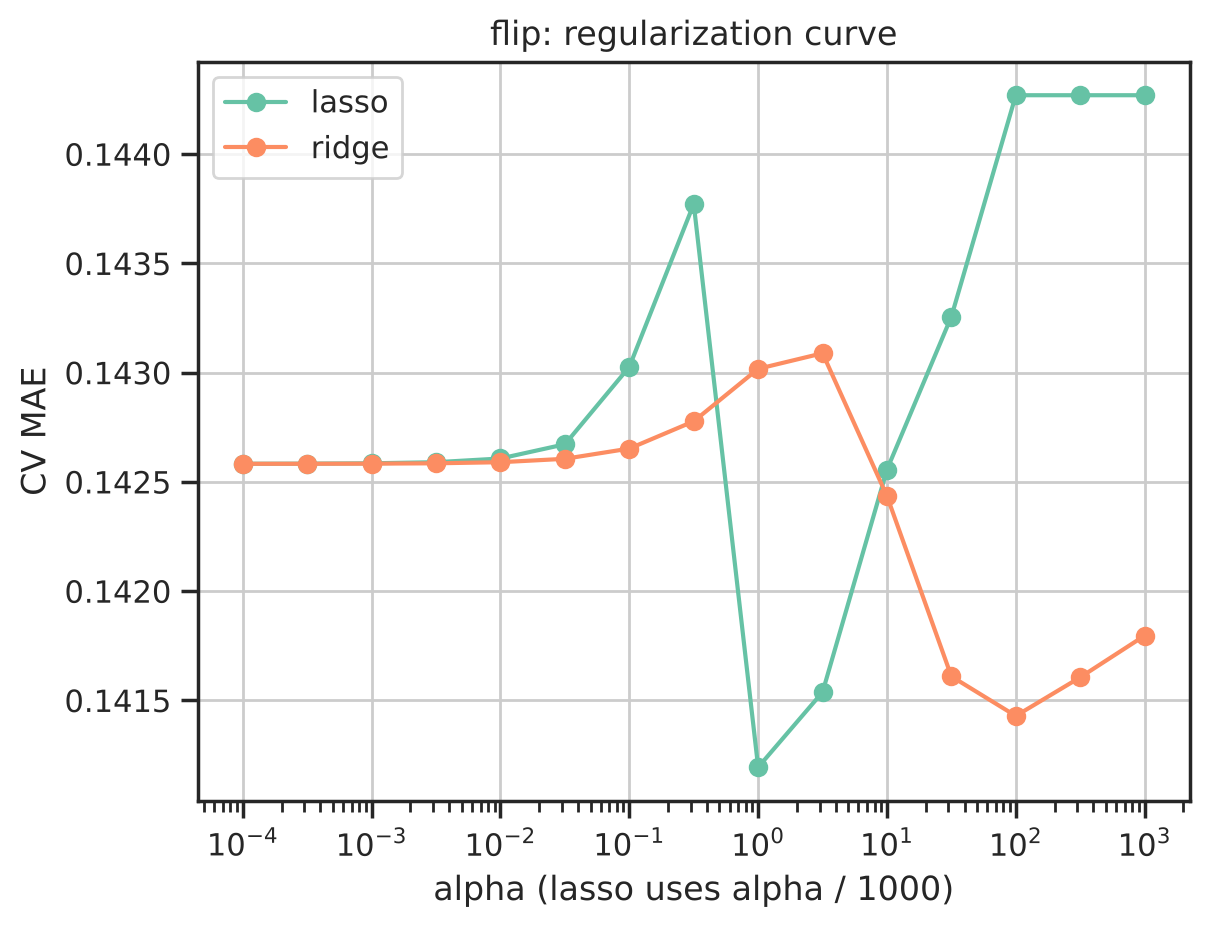

,alpha,model,cv_mae
15,0.31623,lasso,0.03622
22,31.62278,ridge,0.03632


In [56]:
def alpha_curve(task):
    alphas = np.logspace(-4, 3, 15)
    rows = []
    for a in alphas:
        for name, reg in [("ridge", Ridge(alpha=a)), ("lasso", Lasso(alpha=a / 1000, max_iter=5000))]:
            _, cv = mae_cv(task, lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), reg))
            rows.append({"alpha": a, "model": name, "cv_mae": cv})
    r = pd.DataFrame(rows)
    for name, x in r.groupby("model"):
        plt.semilogx(x.alpha, x.cv_mae, "o-", label=name)
    plt.xlabel("alpha (lasso uses alpha / 1000)")
    plt.ylabel("CV MAE")
    plt.title(f"{task}: regularization curve")
    plt.legend()
    plt.grid()
    plt.show()
    return r.loc[r.groupby("model").cv_mae.idxmin()].round(5)

best_alpha = {t: alpha_curve(t) for t in TASKS}
best_alpha["renter"]

In [57]:
best_alpha["flip"]

,alpha,model,cv_mae
17,1.0,lasso,0.14119
24,100.0,ridge,0.14143


In [58]:
def lasso_coefs(task):
    target, h, feats = TASKS[task]
    f = TD[task]
    a = best_alpha[task].set_index("model").alpha["lasso"] / 1000
    tr = f[f.dev & ~f.covid & ~f.out]
    m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Lasso(alpha=a, max_iter=5000)).fit(tr[feats], tr[target])
    c = pd.Series(m[-1].coef_, index=feats)
    print(f"{task}: {(c != 0).sum()} of {len(c)} features kept")
    return c[c != 0].sort_values().round(4)

lasso_coefs("renter")

renter: 15 of 22 features kept


rent_cut_share      -0.0182
mom6                -0.0116
past_rel12          -0.0088
month               -0.0048
rent_vs_boro        -0.0024
cut_lag11           -0.0016
log_inv             -0.0006
boro_Manhattan      -0.0005
boro_Brooklyn        0.0002
new_units_12m_km2    0.0003
mom3                 0.0005
subway_km2           0.0008
boro_Bronx           0.0013
past_12m             0.0051
cut_vs_city          0.0146
dtype: float64

In [59]:
lasso_coefs("flip")

flip: 18 of 21 features kept


sale_rel12          -0.0432
price_to_rent       -0.0192
sale_mom3           -0.0169
boro_Bronx          -0.0166
sale_cut_share      -0.0146
subway_km2          -0.0060
boro_Manhattan      -0.0036
rent_vs_boro        -0.0033
new_units_12m_km2   -0.0029
log_inv             -0.0026
pipeline_km2        -0.0026
mom3                -0.0016
rent_cut_share      -0.0012
past_rel12           0.0075
boro_Brooklyn        0.0083
inv_yoy_log          0.0123
yield                0.0244
sale_price_yoy       0.0298
dtype: float64

### H4. Random forest and gradient boosting: grid search with the same time folds

In [60]:
def grid(task, est, params):
    target, h, feats = TASKS[task]
    f = TD[task]
    gs = GridSearchCV(make_pipeline(SimpleImputer(strategy="median"), est), params, cv=cv_splits(f, h),
                      scoring="neg_mean_absolute_error", n_jobs=-1).fit(f[feats], f[target])
    r = pd.DataFrame(gs.cv_results_)[["params", "mean_test_score", "std_test_score"]]
    r["cv_mae"] = -r.mean_test_score
    return gs.best_params_, r.sort_values("cv_mae")[["params", "cv_mae", "std_test_score"]].head(5)

RF_GRID = {"randomforestregressor__max_depth": [4, 8, None], "randomforestregressor__min_samples_leaf": [20, 100]}
HGB_GRID = {"histgradientboostingregressor__max_depth": [3, None], "histgradientboostingregressor__learning_rate": [0.03, 0.1],
            "histgradientboostingregressor__min_samples_leaf": [20, 100]}

best_grid = {}
for t in TASKS:
    best_grid[(t, "rf")], tab_rf = grid(t, RandomForestRegressor(n_estimators=200, random_state=13, n_jobs=-1), RF_GRID)
    best_grid[(t, "hgb")], tab_hgb = grid(t, HistGradientBoostingRegressor(random_state=13), HGB_GRID)
    print(t, "RF best:", best_grid[(t, "rf")], "| HGB best:", best_grid[(t, "hgb")])

renter RF best: {'randomforestregressor__max_depth': None, 'randomforestregressor__min_samples_leaf': 20} | HGB best: {'histgradientboostingregressor__learning_rate': 0.03, 'histgradientboostingregressor__max_depth': None, 'histgradientboostingregressor__min_samples_leaf': 100}


flip RF best: {'randomforestregressor__max_depth': 4, 'randomforestregressor__min_samples_leaf': 100} | HGB best: {'histgradientboostingregressor__learning_rate': 0.03, 'histgradientboostingregressor__max_depth': 3, 'histgradientboostingregressor__min_samples_leaf': 20}


### H5. Compare all tuned models

Each model gets out-of-fold predictions on the CV years. Positive class for ROC / lift = neighborhood is in the true top 20% that month.
**Selection rule:** lowest CV MAE; take the simplest model whose paired MAE gap to the best (same CV years) is within one SD of that gap
(order from simple to complex: baseline, ridge, lasso, tree, rf, hgb).
Note: the first version compared against the SD of MAE across years, which mostly measures how hard each year was, and picked the baseline. It was corrected to the paired version after the first test run, so the test is no longer fully blind; all models are shown on the test anyway.
Flip is selected by monthly rank, not MAE: the decision is which neighborhoods to buy, and a constant baseline cannot rank (also changed after the first test run).

In [61]:
def make_models(task):
    a = best_alpha[task].set_index("model").alpha
    dp = tree_depth[task]
    imp = lambda: SimpleImputer(strategy="median")
    rf = {k.split("__")[1]: v for k, v in best_grid[(task, "rf")].items()}
    hgb = {k.split("__")[1]: v for k, v in best_grid[(task, "hgb")].items()}
    return {"ridge": lambda: make_pipeline(imp(), StandardScaler(), Ridge(alpha=a["ridge"])),
            "lasso": lambda: make_pipeline(imp(), StandardScaler(), Lasso(alpha=a["lasso"] / 1000, max_iter=5000)),
            "tree": lambda: make_pipeline(imp(), DecisionTreeRegressor(max_depth=dp, min_samples_leaf=20, random_state=13)),
            "rf": lambda: make_pipeline(imp(), RandomForestRegressor(n_estimators=200, random_state=13, n_jobs=-1, **rf)),
            "hgb": lambda: make_pipeline(imp(), HistGradientBoostingRegressor(random_state=13, **hgb))}

tree_depth = {"renter": 4, "flip": 4}

def baseline_pred(task, tr, va):
    target = TASKS[task][0]
    if task == "renter":
        means = tr.groupby(["Borough", "end_month"])[target].mean().rename("p")
        return va.join(means, on=["Borough", "end_month"]).p.fillna(tr[target].mean()).values
    return np.full(len(va), tr[target].mean())

def oof_all(task):
    target, h, feats = TASKS[task]
    f = TD[task]
    out = []
    for (tr, va), y in zip(cv_splits(f, h), CV_YEARS):
        trf, vaf = f.loc[tr], f.loc[va].copy()
        vaf["year"] = y
        vaf["baseline"] = baseline_pred(task, trf, vaf)
        for n, mk in make_models(task).items():
            vaf[n] = mk().fit(trf[feats], trf[target]).predict(vaf[feats])
        out.append(vaf)
    return pd.concat(out)

MODELS = ["baseline", "ridge", "lasso", "tree", "rf", "hgb"]

def metrics(p, task):
    target = TASKS[task][0]
    rows = []
    for (y, n) in [(y, n) for y in sorted(p.year.unique()) for n in MODELS]:
        x = p[p.year == y]
        rows.append({"year": y, "model": n, "mae": mean_absolute_error(x[target], x[n]),
                     "rank": month_rank(x.date, x[target], x[n]), "lift": top_lift(x.date, x[target], x[n])})
    return pd.DataFrame(rows)

def choose(m, metric="mae"):
    t = m.pivot(index="year", columns="model", values=metric)
    if metric == "rank":
        t = -t.drop(columns="baseline")
    best = t.mean().idxmin()
    diff = t.sub(t[best], axis=0)
    s = pd.DataFrame({f"mean_{metric}": t.mean().abs(), "gap_vs_best": diff.mean(), "sd_gap": diff.std()}).reindex(MODELS).dropna()
    for n in MODELS:
        if n in s.index and (n == best or s.loc[n, "gap_vs_best"] <= s.loc[n, "sd_gap"]):
            return n, s.round(5)

SELECT_BY = {"renter": "mae", "flip": "rank"}
OOF = {t: oof_all(t) for t in TASKS}
MET = {t: metrics(OOF[t], t) for t in TASKS}
CHOSEN = {}
for t in TASKS:
    CHOSEN[t], s = choose(MET[t], SELECT_BY[t])
    print(t, "-> chosen:", CHOSEN[t])
    display(s)
    display(MET[t].groupby("model")[["mae", "rank", "lift"]].mean().reindex(MODELS).round(4))

renter -> chosen: ridge


,mean_mae,gap_vs_best,sd_gap
model,,,
baseline,0.03783,0.00165,0.00057
ridge,0.03632,0.00015,0.00115
lasso,0.03622,0.00004,0.00101
tree,0.03720,0.00103,0.00069
rf,0.03619,0.00002,0.00021
hgb,0.03617,0.00000,0.00000


,mae,rank,lift
model,,,
baseline,0.0378,-0.0118,1.0076
ridge,0.0363,0.3120,1.8499
lasso,0.0362,0.3137,1.8660
tree,0.0372,0.2601,1.6080
rf,0.0362,0.3151,1.8570
hgb,0.0362,0.3205,1.8471


flip -> chosen: ridge


,mean_rank,gap_vs_best,sd_gap
model,,,
ridge,0.27040,0.00000,0.00000
lasso,0.26607,0.00433,0.01175
tree,0.20867,0.06173,0.10898
rf,0.25229,0.01812,0.04821
hgb,0.26626,0.00415,0.01764


,mae,rank,lift
model,,,
baseline,0.1443,NaN,NaN
ridge,0.1414,0.2704,1.8202
lasso,0.1412,0.2661,1.8421
tree,0.1480,0.2087,1.5625
rf,0.1423,0.2523,1.7050
hgb,0.1409,0.2663,1.8421


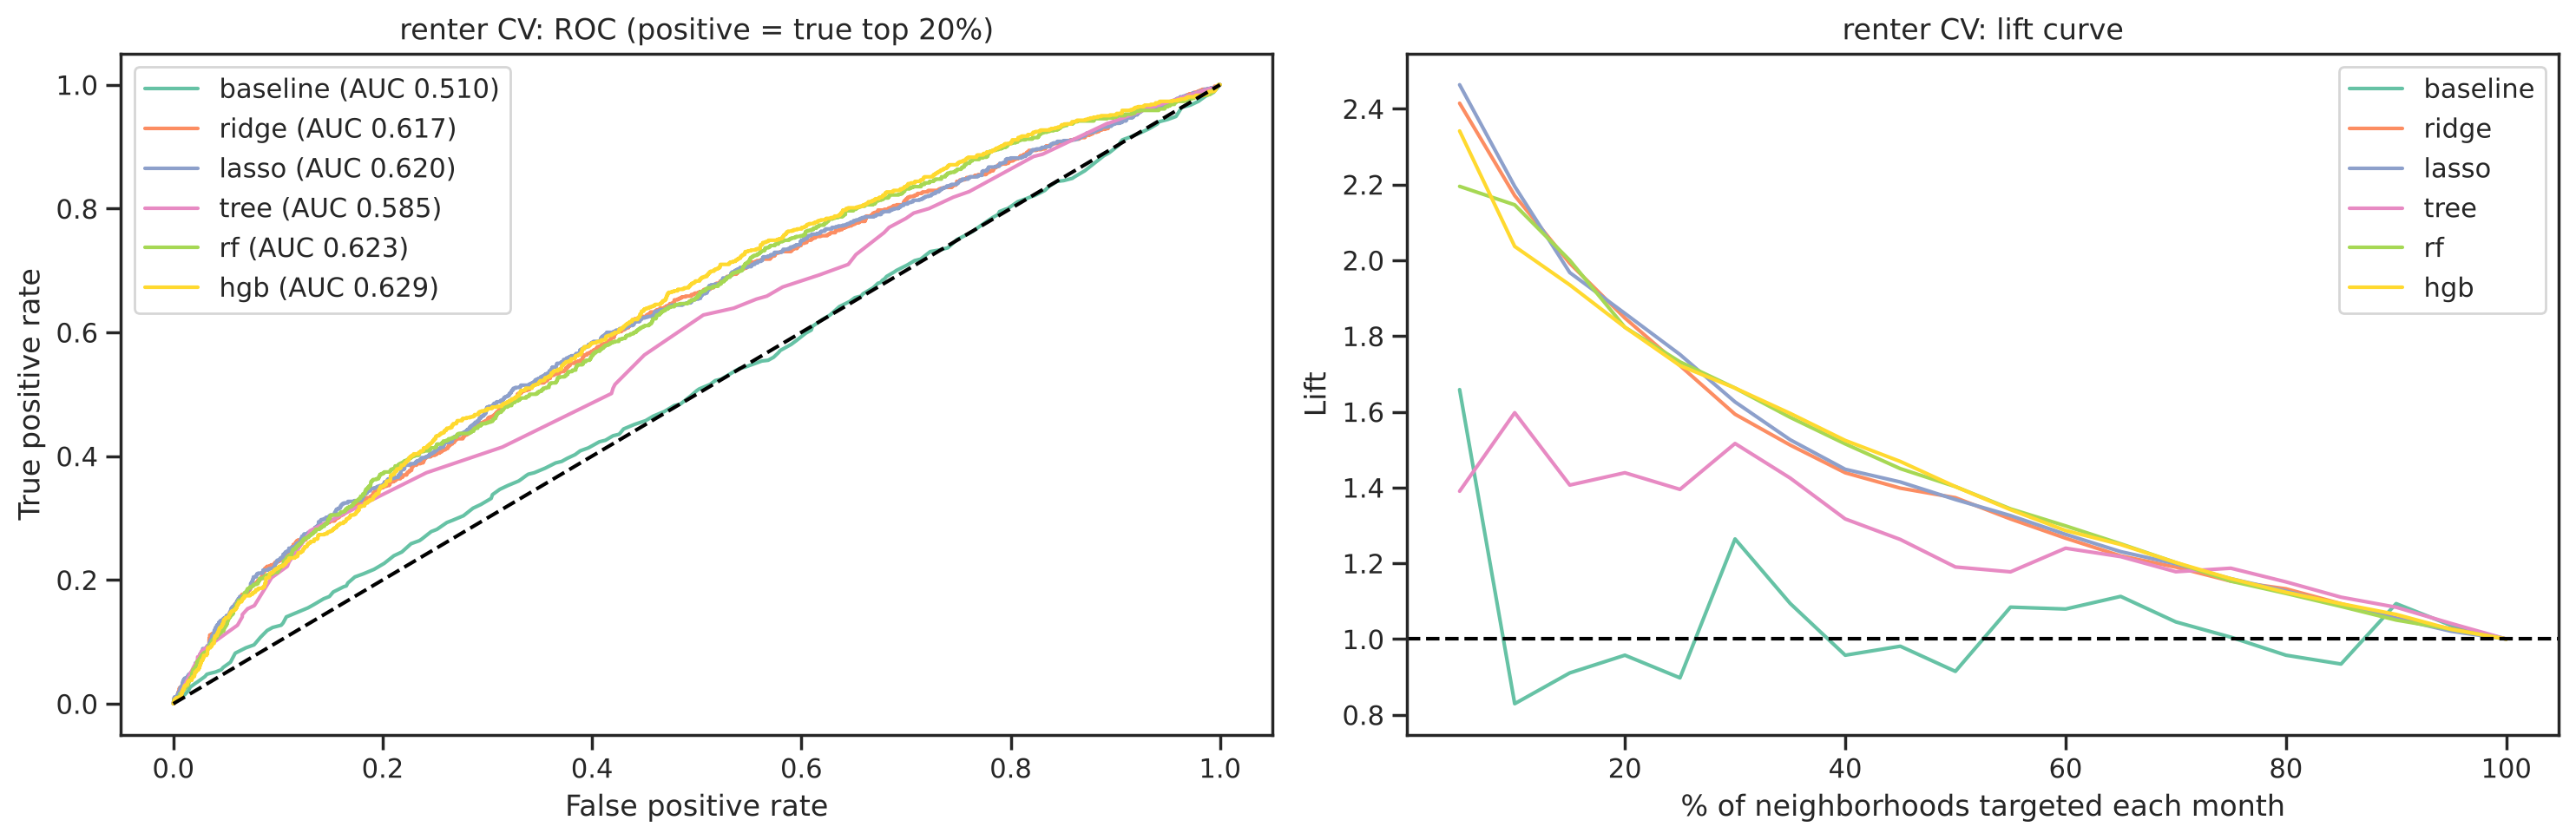

In [62]:
def top20_label(p, task):
    target = TASKS[task][0]
    return p.groupby("date")[target].transform(lambda s: s >= s.quantile(0.8)).astype(int)

def compare_curves(p, task, title):
    y = top20_label(p, task)
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    for n in MODELS:
        if p[n].nunique() < 2:
            continue
        fpr, tpr, _ = roc_curve(y, p[n])
        axs[0].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y, p[n]):.3f})")
        pct = p.groupby("date")[n].rank(pct=True, ascending=False)
        qs = np.arange(0.05, 1.01, 0.05)
        lift = [y[pct <= q].sum() / y.sum() / q for q in qs]
        axs[1].plot(qs * 100, lift, label=n)
    axs[0].plot([0, 1], [0, 1], "k--")
    axs[0].set_xlabel("False positive rate")
    axs[0].set_ylabel("True positive rate")
    axs[0].set_title(f"{title}: ROC (positive = true top 20%)")
    axs[0].legend()
    axs[1].axhline(1, color="k", ls="--")
    axs[1].set_xlabel("% of neighborhoods targeted each month")
    axs[1].set_ylabel("Lift")
    axs[1].set_title(f"{title}: lift curve")
    axs[1].legend()
    plt.tight_layout()
    plt.show()

compare_curves(OOF["renter"], "renter", "renter CV")

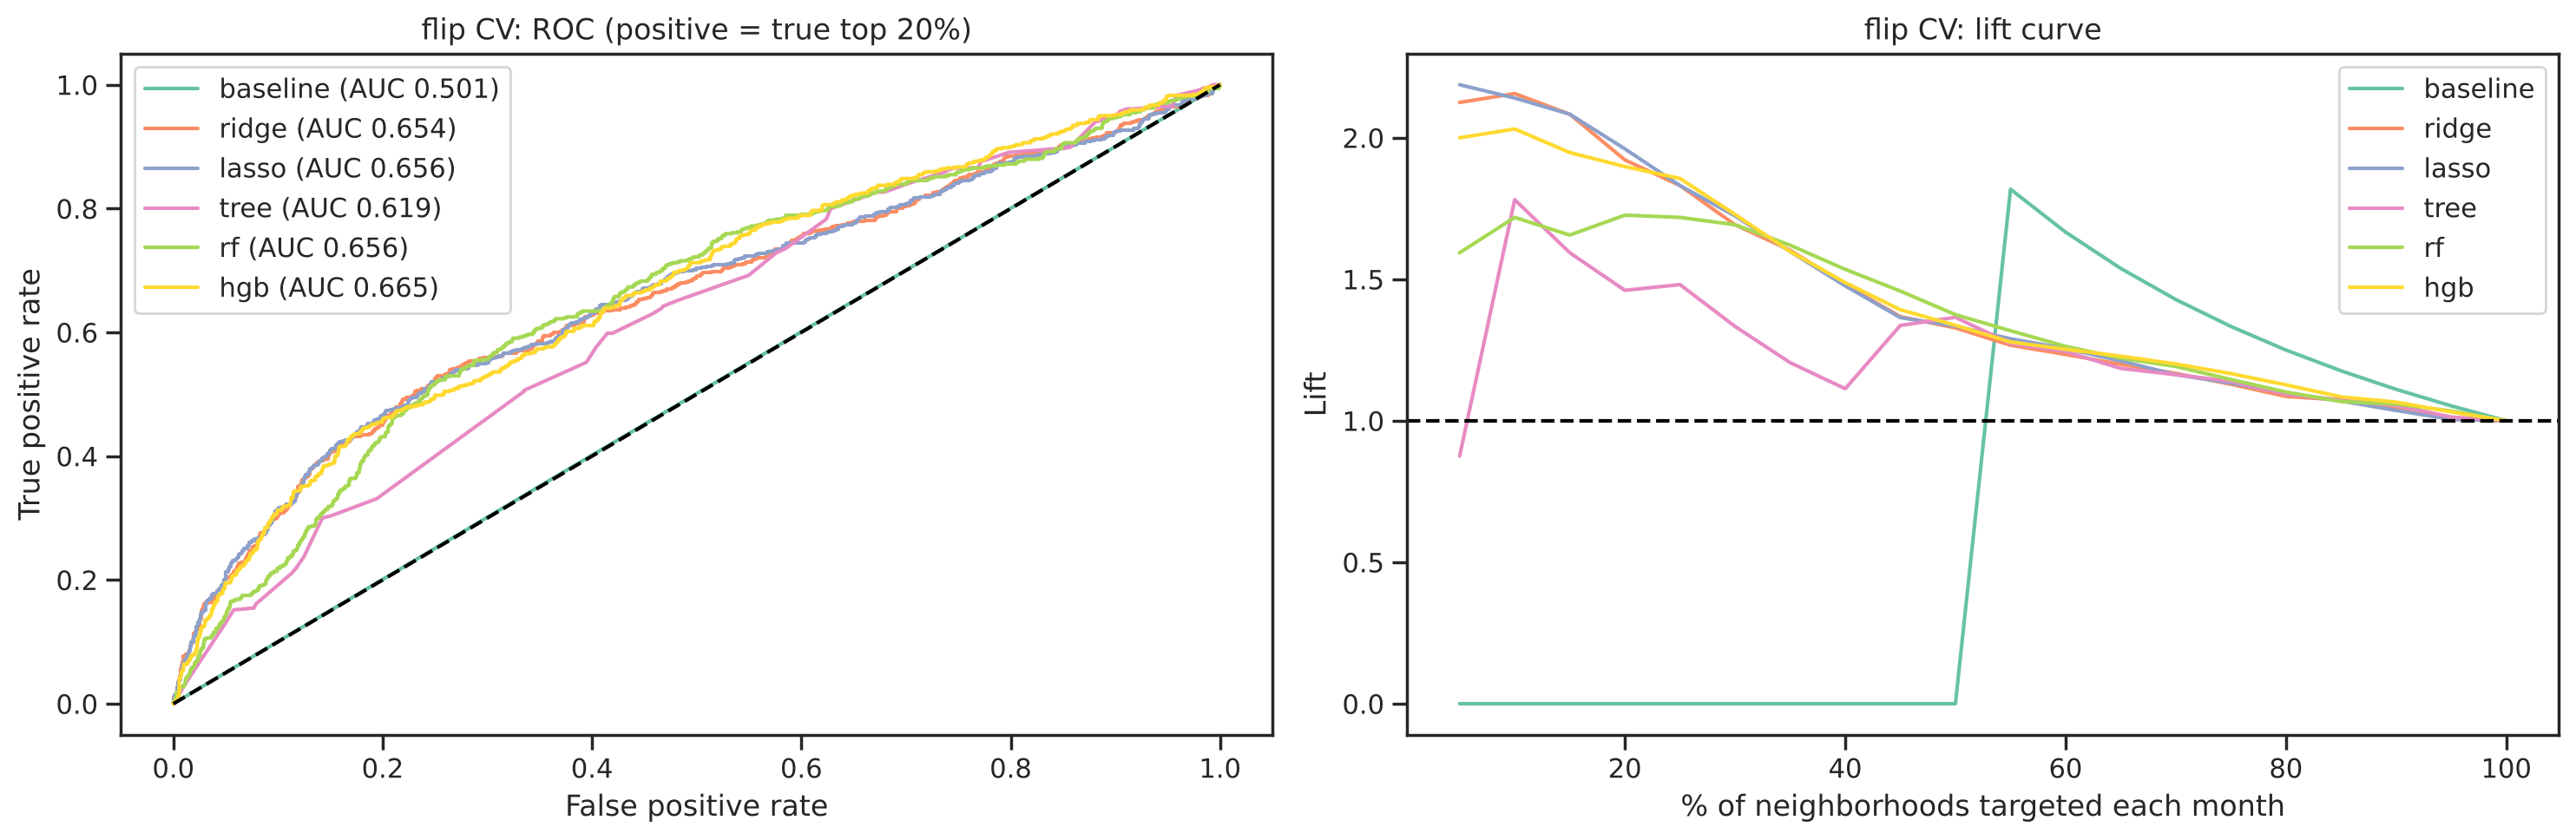

In [63]:
compare_curves(OOF["flip"], "flip", "flip CV")

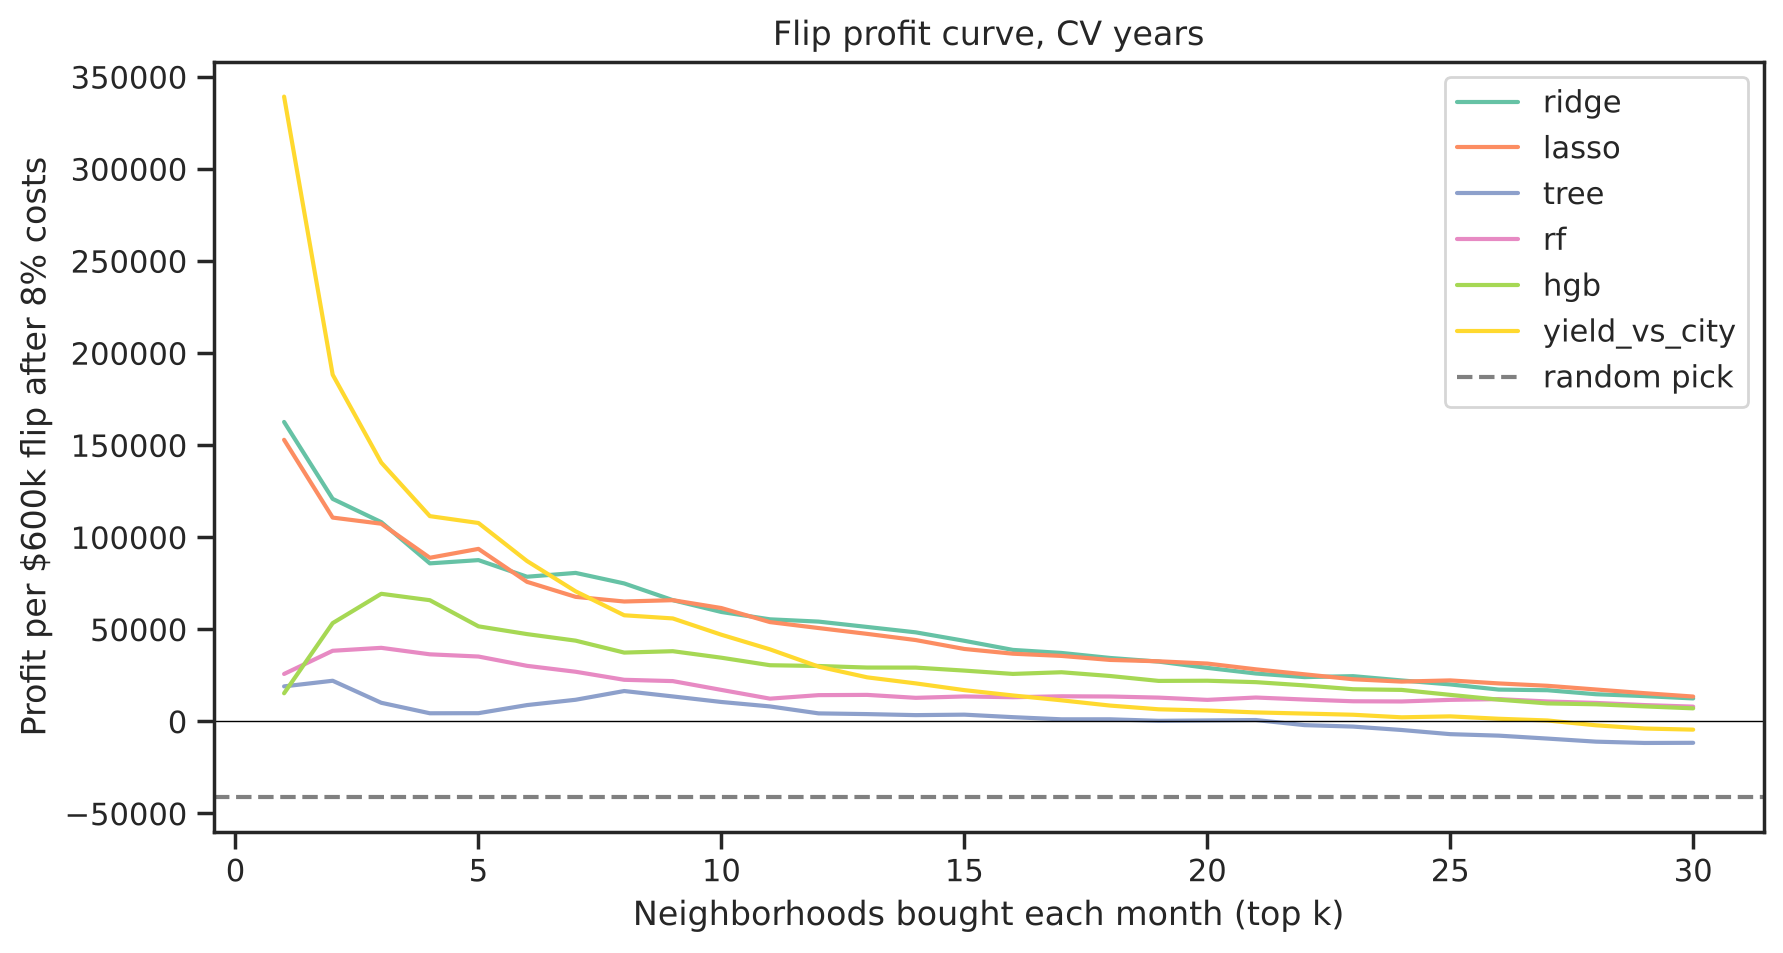

In [64]:
def flip_profit(p, title, ks=range(1, 31)):
    plt.figure(figsize=(10, 5))
    for n in MODELS[1:] + ["yield_vs_city"]:
        prof = [usd(p.sort_values(n, ascending=False).groupby("date").head(k).t_sale_chg12.mean()) for k in ks]
        plt.plot(list(ks), prof, label=n)
    plt.axhline(usd(p.t_sale_chg12.mean()), color="gray", ls="--", label="random pick")
    plt.axhline(0, color="k", lw=0.5)
    plt.xlabel("Neighborhoods bought each month (top k)")
    plt.ylabel(f"Profit per ${PRICE // 1000}k flip after {COST:.0%} costs")
    plt.title(title)
    plt.legend()
    plt.show()

flip_profit(OOF["flip"], "Flip profit curve, CV years")

## T. Test: 2024 → latest (run once)

Every model is refit on all clean dev data (target window ends before 2024) with the settings chosen above, then scored on test months.
The chosen model is marked; all others are shown for honesty.

In [65]:
def test_preds(task):
    target, h, feats = TASKS[task]
    f = TD[task]
    tr = f[f.dev & ~f.covid & ~f.out]
    te = f[~f.dev & (f.date >= TEST_START)].copy()
    te["year"] = te.date.dt.year
    te["baseline"] = baseline_pred(task, tr, te)
    for n, mk in make_models(task).items():
        te[n] = mk().fit(tr[feats], tr[target]).predict(te[feats])
    return te

TEST = {t: test_preds(t) for t in TASKS}
for t in TASKS:
    m = metrics(TEST[t], t)
    print(t, "| test months:", TEST[t].date.min().date(), "->", TEST[t].date.max().date(), "| chosen:", CHOSEN[t])
    display(m.groupby("model")[["mae", "rank", "lift"]].mean().reindex(MODELS).round(4))

renter | test months: 2024-01-01 -> 2026-06-01 | chosen: ridge


,mae,rank,lift
model,,,
baseline,0.0433,0.0300,1.1597
ridge,0.0404,0.3309,2.0764
lasso,0.0405,0.3388,2.0833
tree,0.0416,0.2831,1.8750
rf,0.0402,0.3396,1.8889
hgb,0.0403,0.3352,1.9514


flip | test months: 2024-01-01 -> 2025-09-01 | chosen: ridge


,mae,rank,lift
model,,,
baseline,0.1259,NaN,NaN
ridge,0.1297,0.2749,1.6118
lasso,0.1243,0.2692,1.6265
tree,0.1257,0.1701,1.7069
rf,0.1253,0.2401,1.6849
hgb,0.1263,0.2674,1.5570


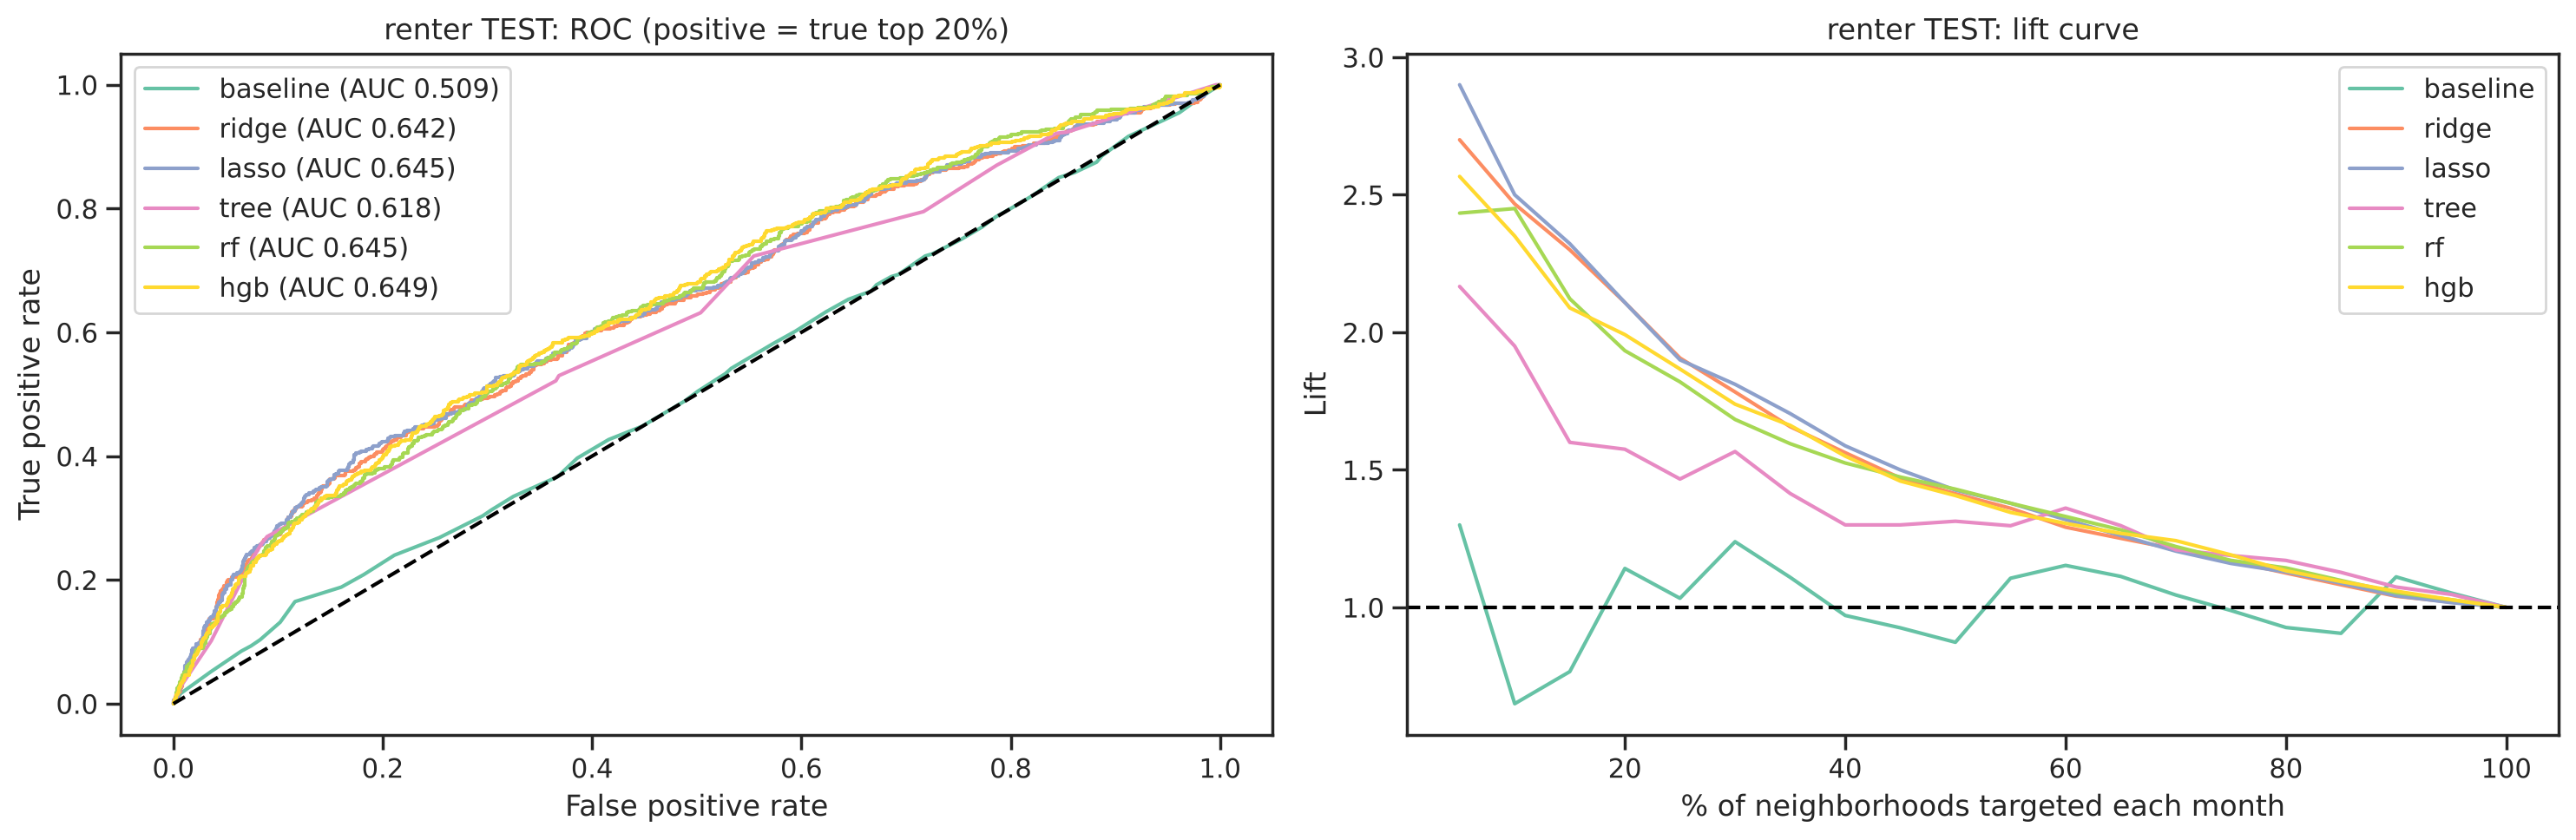

In [66]:
compare_curves(TEST["renter"], "renter", "renter TEST")

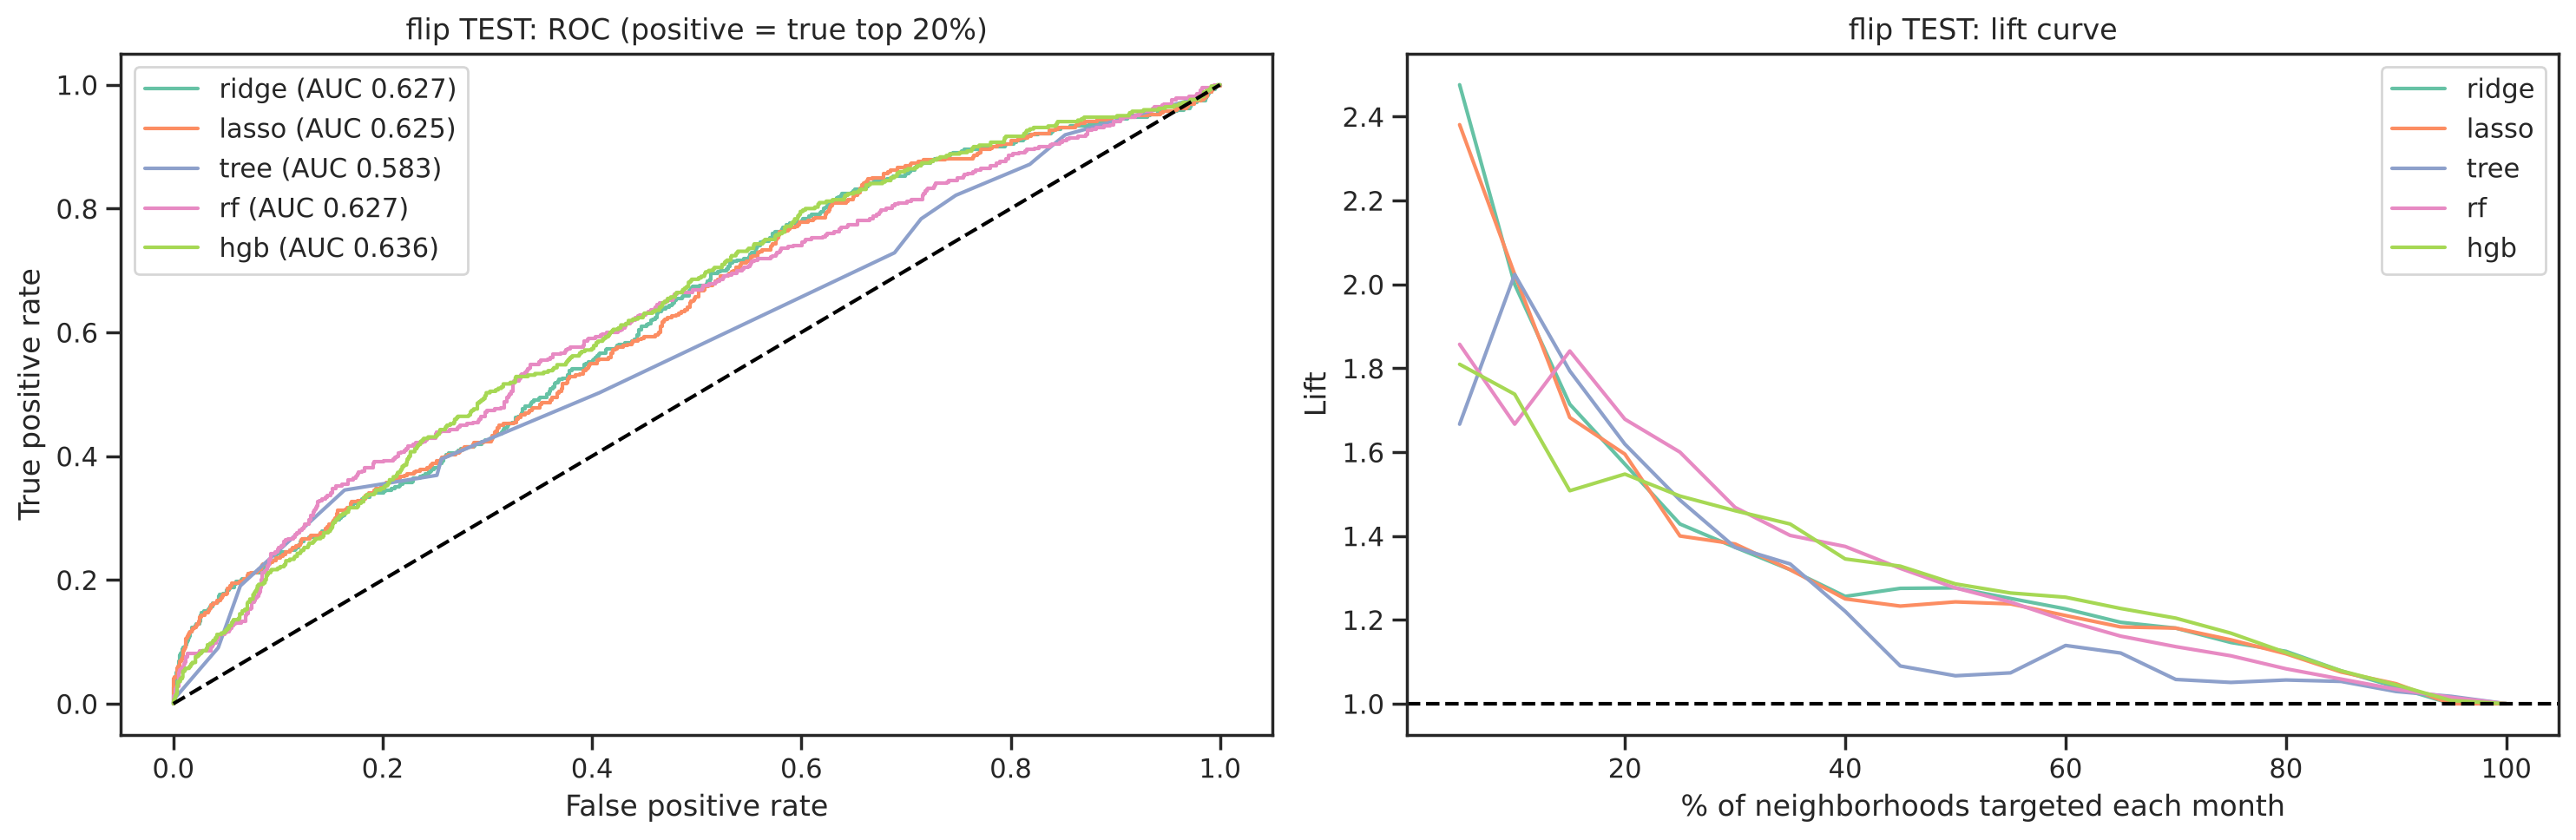

In [67]:
compare_curves(TEST["flip"], "flip", "flip TEST")

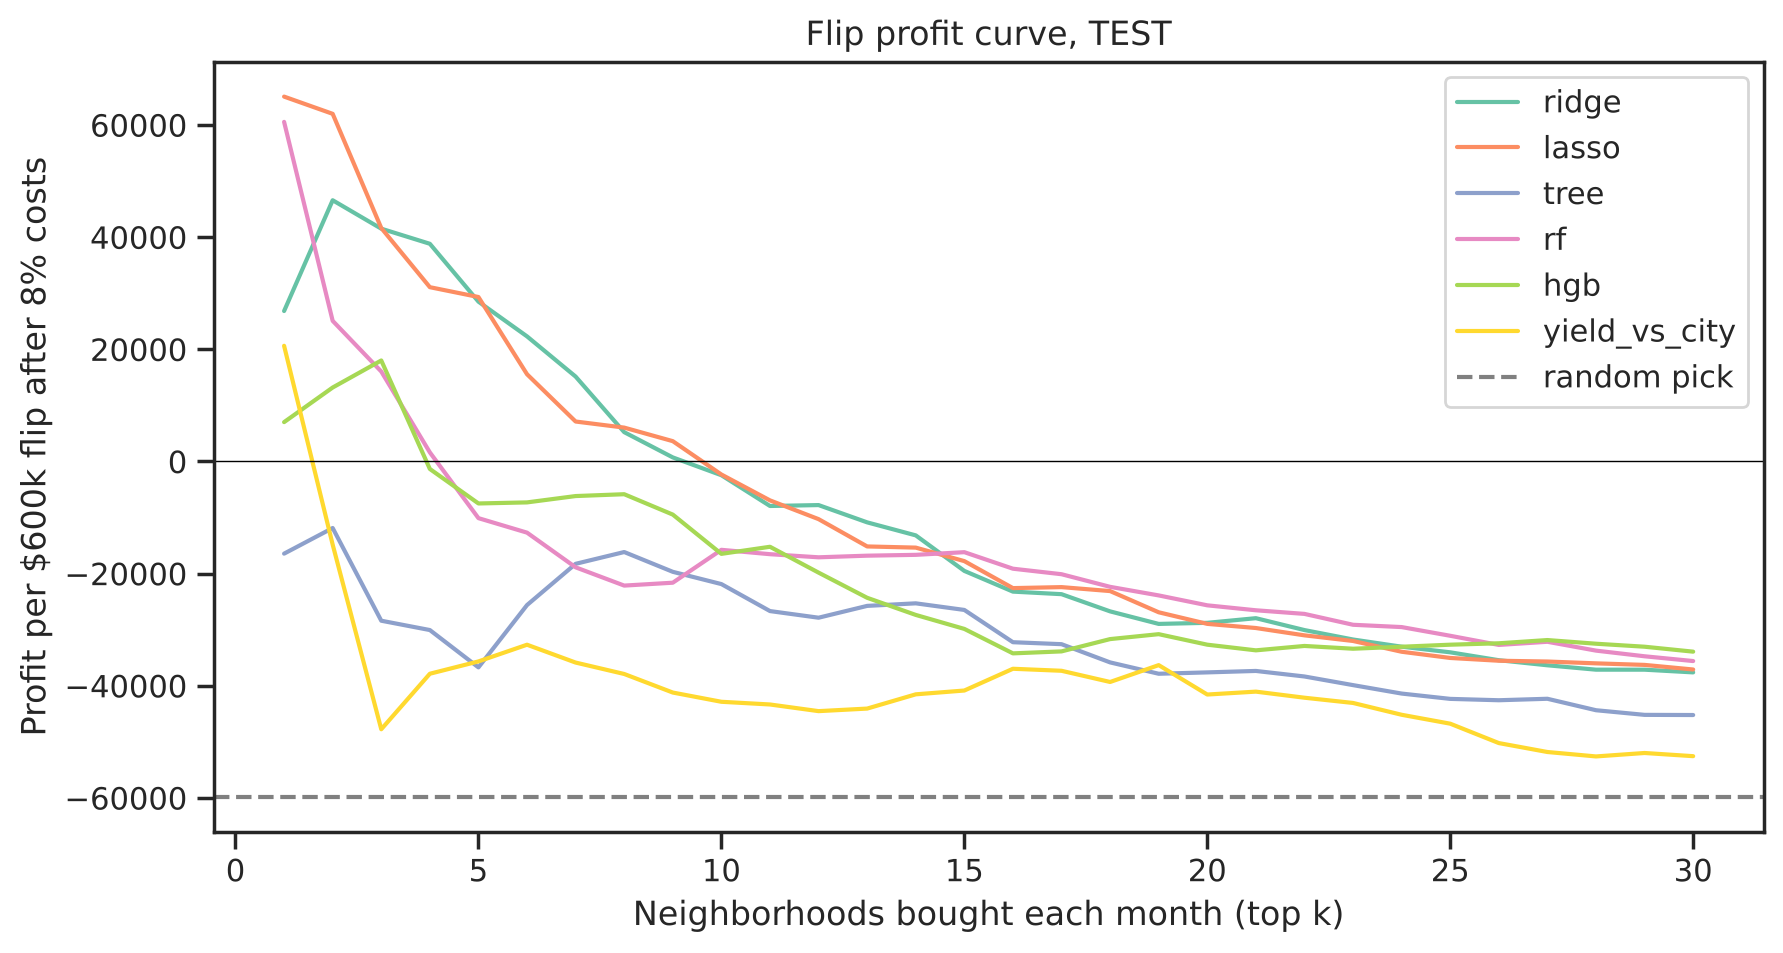

,5,10,20,random
ridge,28500.0,-2500.0,-28800.0,-59800.0
lasso,29300.0,-2300.0,-29000.0,-59800.0
tree,-36700.0,-21900.0,-37600.0,-59800.0
rf,-10100.0,-15800.0,-25700.0,-59800.0
hgb,-7500.0,-16500.0,-32700.0,-59800.0
yield_vs_city,-35700.0,-42900.0,-41600.0,-59800.0


In [68]:
flip_profit(TEST["flip"], "Flip profit curve, TEST")
p = TEST["flip"]
pd.DataFrame({k: {n: round(usd(p.sort_values(n, ascending=False).groupby("date").head(k).t_sale_chg12.mean()), -2)
                  for n in MODELS[1:] + ["yield_vs_city"]} for k in [5, 10, 20]}).assign(random=round(usd(p.t_sale_chg12.mean()), -2))

In [69]:
p.groupby("year").apply(lambda x: pd.Series({n: x.sort_values(n, ascending=False).groupby("date").head(10).t_sale_chg12.mean()
                                             for n in [CHOSEN["flip"], "yield_vs_city"]} | {"all": x.t_sale_chg12.mean()})).round(3)

,ridge,yield_vs_city,all
year,,,
2024,0.080,0.006,-0.016
2025,0.063,0.012,-0.025


In [70]:
r = TEST["renter"]
c = CHOSEN["renter"]
print(f"renter test, direction right: chosen {np.mean(np.sign(r[c]) == np.sign(r.t_chg3)):.1%} | season {np.mean(np.sign(r.baseline) == np.sign(r.t_chg3)):.1%}")
for n in [c, "baseline"]:
    w = r[n] < 0
    saved = (-(np.exp(r.t_chg3) - 1) * r.rent_3m)[w]
    print(f"{n}: says wait in {w.mean():.1%} of cases | rent really dropped in {(r.t_chg3[w] < 0).mean():.1%} of those | avg $ saved per month = {saved.mean():.0f}")

renter test, direction right: chosen 70.6% | season 67.6%
ridge: says wait in 26.6% of cases | rent really dropped in 69.9% of those | avg $ saved per month = 99
baseline: says wait in 28.1% of cases | rent really dropped in 63.3% of those | avg $ saved per month = 34


## K. More correlation checks

K1: for the original target (`t_rel12`), what adds beyond `past_rel12`?
K2: two-feature tables. Does one signal get stronger or weaker depending on another (interaction)?
Spread = mean target in quintile 1 minus quintile 5 of the main feature, inside each group. Then a CV check: Ridge with vs without the interaction term.

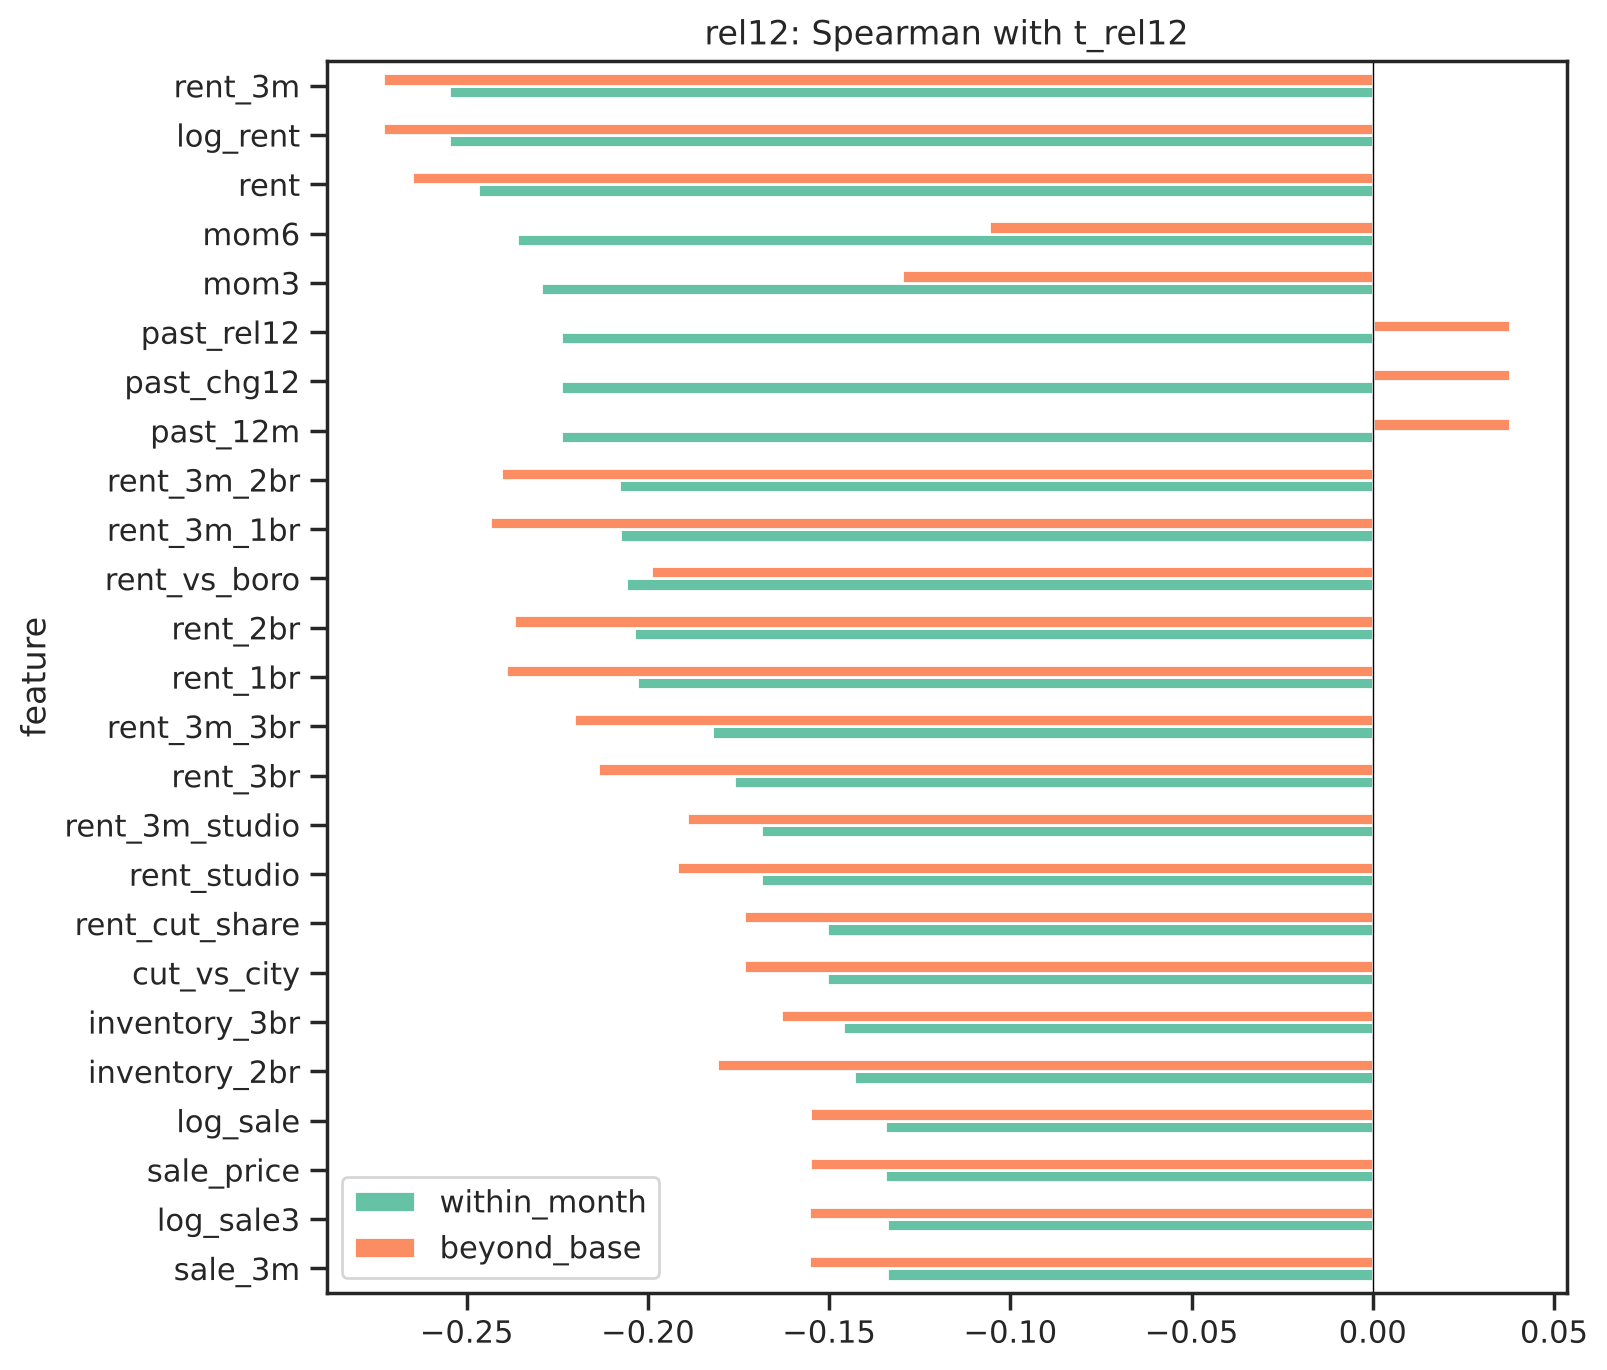

,feature,within_month,beyond_base
8,rent_3m,-0.255,-0.273
42,log_rent,-0.255,-0.273
3,rent,-0.247,-0.265
46,mom6,-0.236,-0.106
45,mom3,-0.229,-0.130
47,past_rel12,-0.224,0.038
60,past_chg12,-0.224,0.038
9,past_12m,-0.224,0.038
34,rent_3m_2br,-0.208,-0.241
29,rent_3m_1br,-0.208,-0.244


In [71]:
TASKS["rel12"] = ("t_rel12", 12, MARKET + CITY + BORO)
TD["rel12"] = task_data("t_rel12", 12)
scan("rel12", "past_rel12")

In [72]:
def resid_target(task):
    target = TASKS[task][0]
    f = TD[task]
    f = f[f.dev & ~f.covid].copy()
    f["y"] = f[target] - f.groupby(["date", "Borough"])[target].transform("mean") if task == "renter" else f[target]
    return f

def two_way(task, main, by):
    f = resid_target(task).dropna(subset=[main])
    f["q"] = f.groupby("date")[main].transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=False) + 1)
    if by in ("Borough",):
        f["g"] = f[by]
    else:
        f = f.dropna(subset=[by])
        f["g"] = f.groupby("date")[by].transform(lambda s: pd.qcut(s.rank(method="first"), 3, labels=["low", "mid", "high"]))
    t = f.pivot_table(index="g", columns="q", values="y", aggfunc="mean", observed=True)
    t["spread_q1_q5"] = t[1] - t[5]
    t["rows"] = f.groupby("g", observed=True).size()
    plt.figure(figsize=(8, 0.6 * len(t) + 1.5))
    sns.heatmap(t[[1, 2, 3, 4, 5]] * 100, annot=True, fmt=".1f", cmap="RdBu", center=0)
    plt.title(f"{task}: target (%) by {main} quintile (cols) and {by} (rows)")
    plt.xlabel(f"{main} quintile")
    plt.ylabel(by)
    plt.show()
    return t.round(4)

def interaction_cv(task, main, other):
    target, h, _ = TASKS[task]
    f = TD[task].copy()
    if other == "Borough":
        return None
    f["inter"] = f[main] * f[other]
    rows = []
    for name, feats in [("main + other", [main, other]), ("main + other + main*other", [main, other, "inter"])]:
        mae, rk = [], []
        for tr, va in cv_splits(f, h):
            m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10)).fit(f.loc[tr, feats], f.loc[tr, target])
            p = m.predict(f.loc[va, feats])
            mae.append(mean_absolute_error(f.loc[va, target], p))
            rk.append(month_rank(f.loc[va, "date"], f.loc[va, target], p))
        rows.append({"task": task, "pair": f"{main} x {other}", "model": name, "cv_mae": np.mean(mae), "cv_rank": np.mean(rk)})
    return pd.DataFrame(rows)

PAIRS = [("renter", "mom6", "rent_cut_share"), ("renter", "mom6", "inventory"), ("renter", "mom6", "Borough"),
         ("rel12", "past_rel12", "cut_vs_city"), ("rel12", "past_rel12", "inventory"), ("rel12", "past_rel12", "Borough"),
         ("flip", "sale_rel12", "yield_vs_city"), ("flip", "yield_vs_city", "inventory"), ("flip", "yield_vs_city", "Borough")]

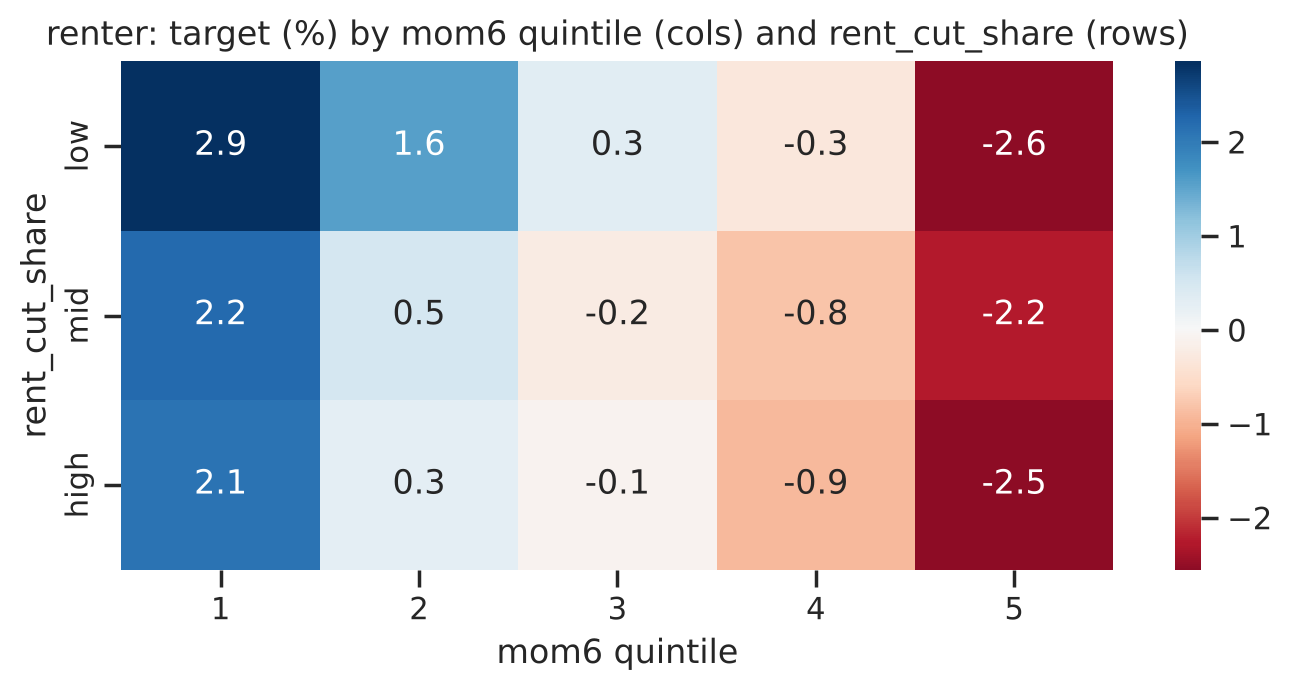

q,1,2,3,4,5,spread_q1_q5,rows
g,,,,,,,
low,0.0286,0.0157,0.0033,-0.0033,-0.0255,0.0541,2516
mid,0.0220,0.0049,-0.0024,-0.0081,-0.0225,0.0445,2442
high,0.0210,0.0027,-0.0009,-0.0091,-0.0254,0.0464,2442


In [73]:
two_way("renter", "mom6", "rent_cut_share")

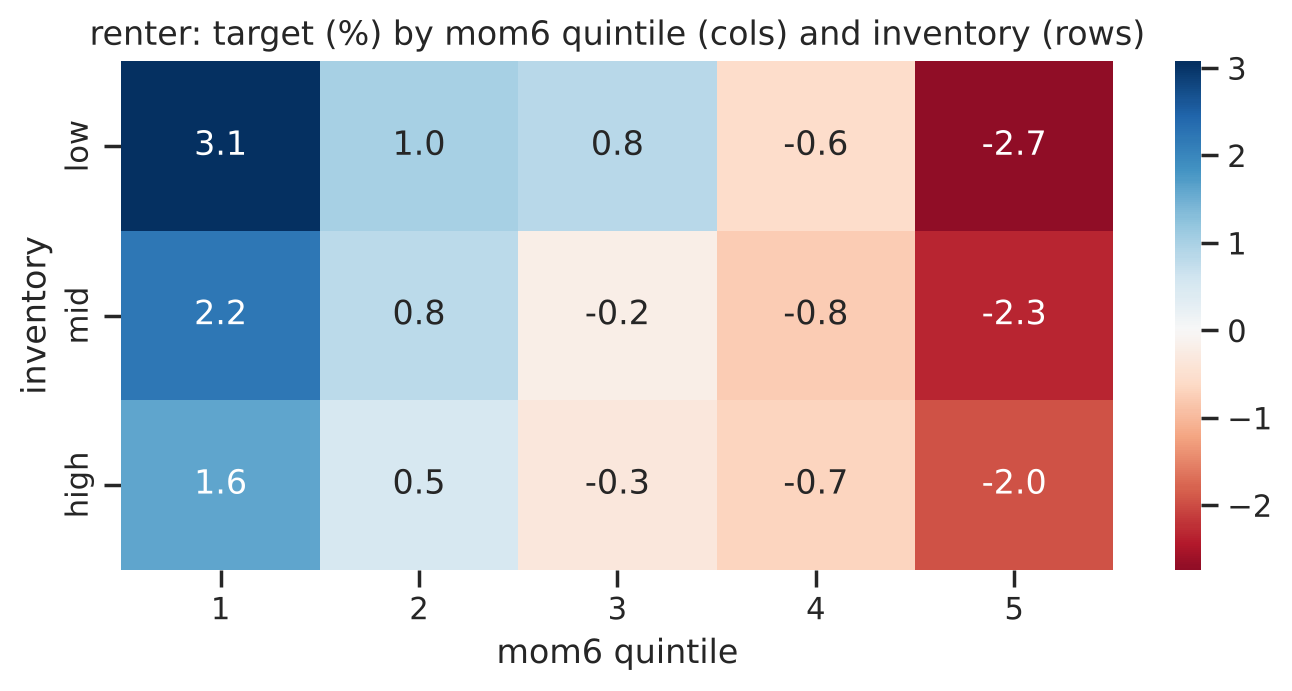

q,1,2,3,4,5,spread_q1_q5,rows
g,,,,,,,
low,0.0307,0.0102,0.0084,-0.0057,-0.0274,0.0581,2516
mid,0.0221,0.0082,-0.0020,-0.0076,-0.0235,0.0456,2442
high,0.0160,0.0051,-0.0035,-0.0068,-0.0195,0.0356,2442


In [74]:
two_way("renter", "mom6", "inventory")

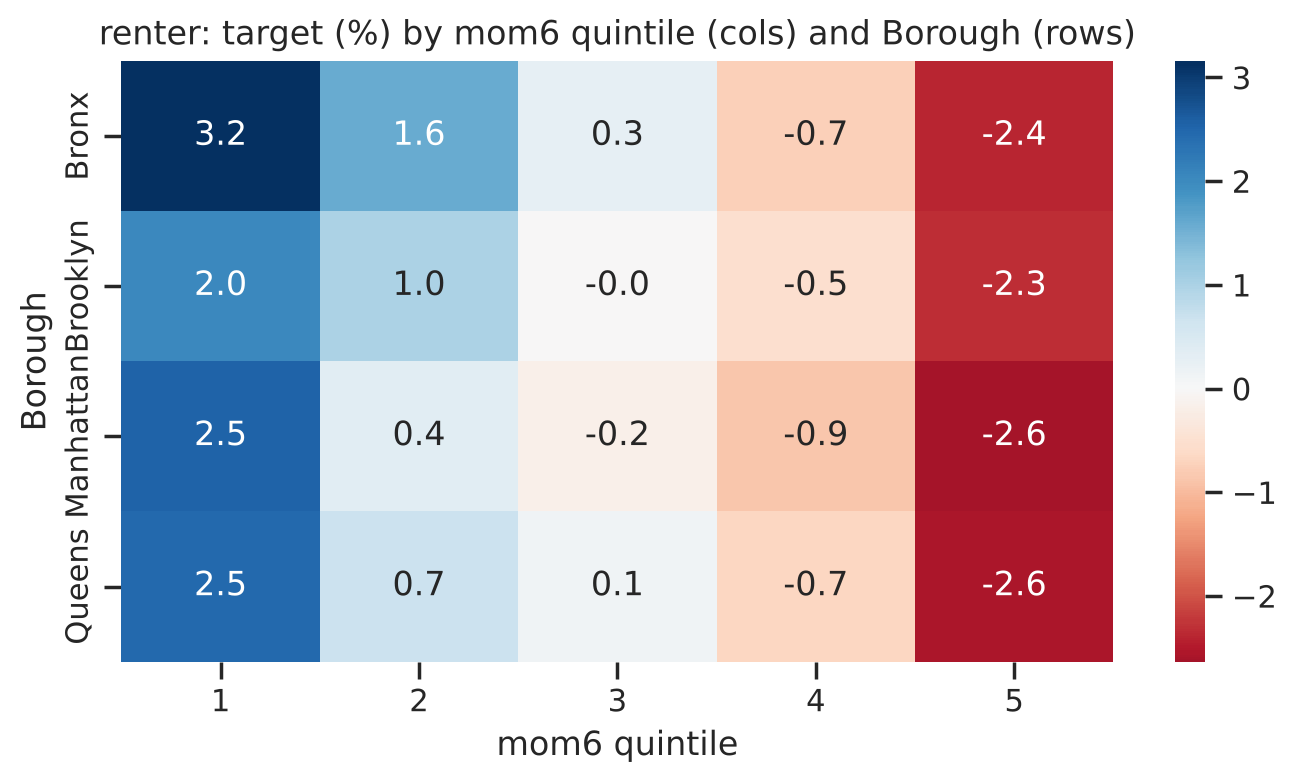

q,1,2,3,4,5,spread_q1_q5,rows
g,,,,,,,
Bronx,0.0316,0.0159,0.0028,-0.0074,-0.0238,0.0554,666
Brooklyn,0.0204,0.0099,-0.0003,-0.0052,-0.0232,0.0437,2960
Manhattan,0.0254,0.0036,-0.0017,-0.0088,-0.0263,0.0517,2220
Queens,0.0248,0.0067,0.0014,-0.0068,-0.0258,0.0506,1554


In [75]:
two_way("renter", "mom6", "Borough")

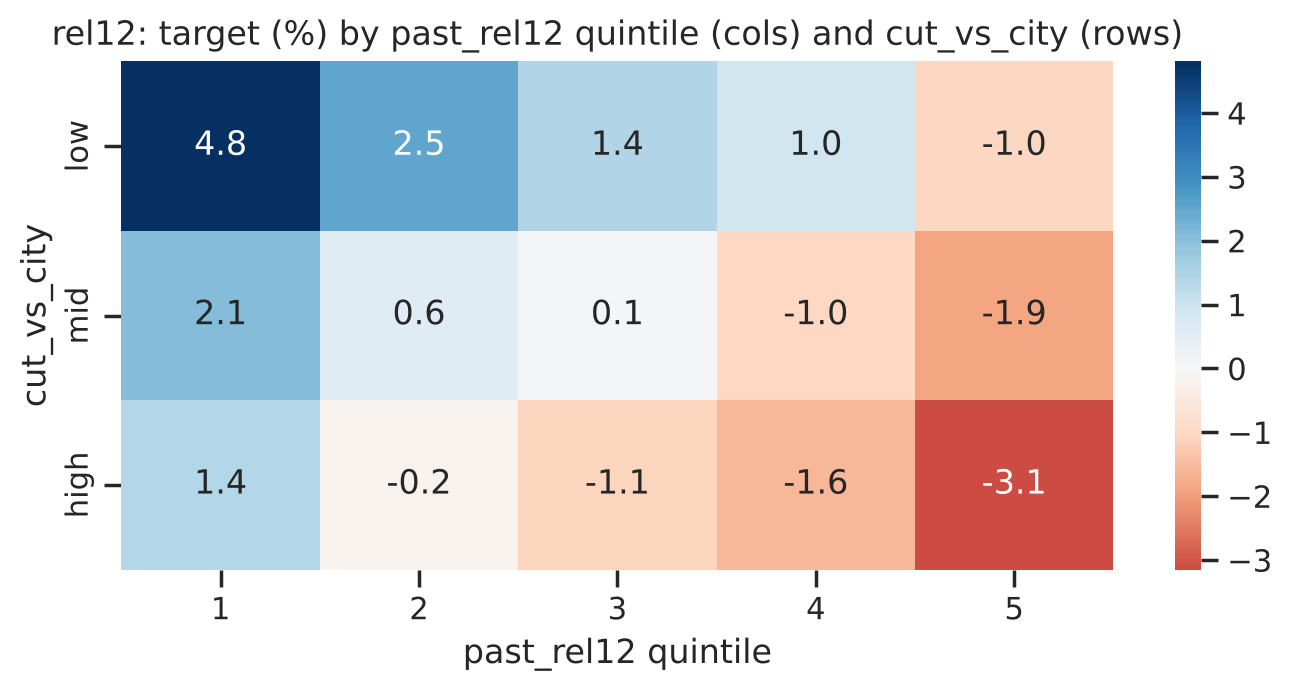

q,1,2,3,4,5,spread_q1_q5,rows
g,,,,,,,
low,0.0481,0.0253,0.0142,0.0095,-0.0103,0.0584,1904
mid,0.0208,0.0057,0.0008,-0.0100,-0.0188,0.0395,1848
high,0.0140,-0.0020,-0.0107,-0.0158,-0.0315,0.0455,1848


In [76]:
two_way("rel12", "past_rel12", "cut_vs_city")

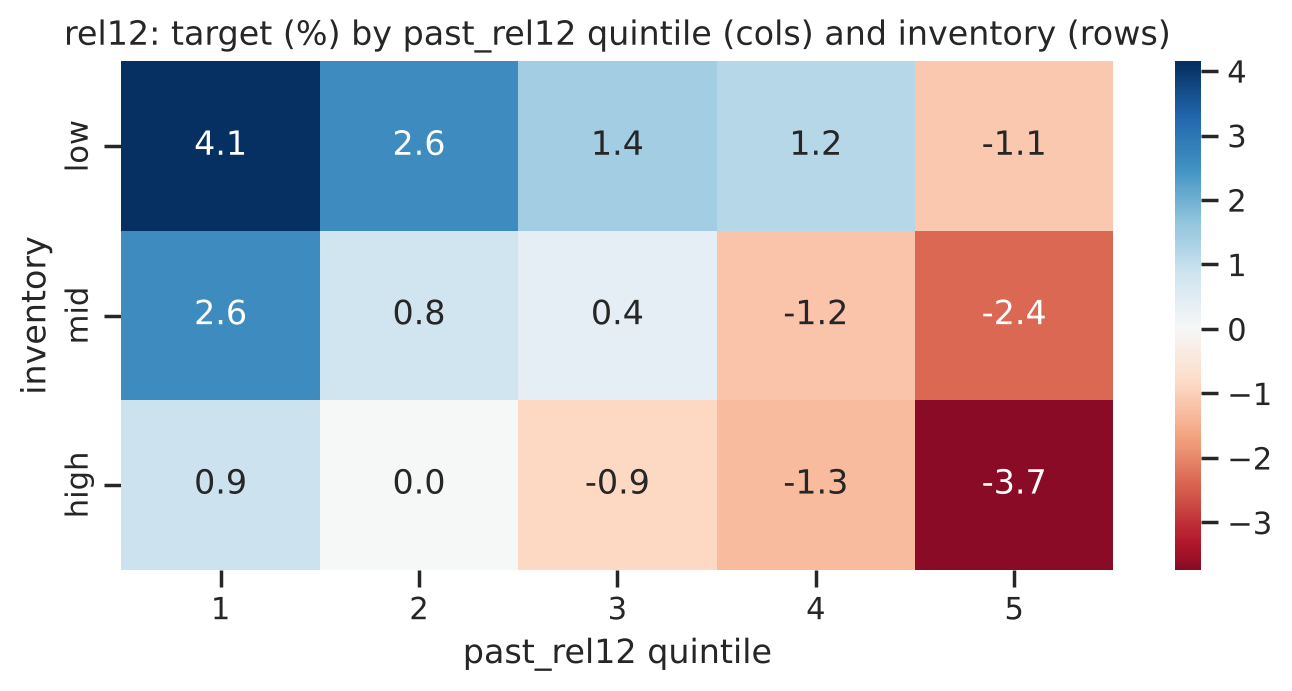

q,1,2,3,4,5,spread_q1_q5,rows
g,,,,,,,
low,0.0415,0.0259,0.0143,0.0117,-0.0109,0.0524,1904
mid,0.0258,0.0082,0.0042,-0.0120,-0.0237,0.0495,1848
high,0.0091,0.0002,-0.0086,-0.0131,-0.0373,0.0464,1848


In [77]:
two_way("rel12", "past_rel12", "inventory")

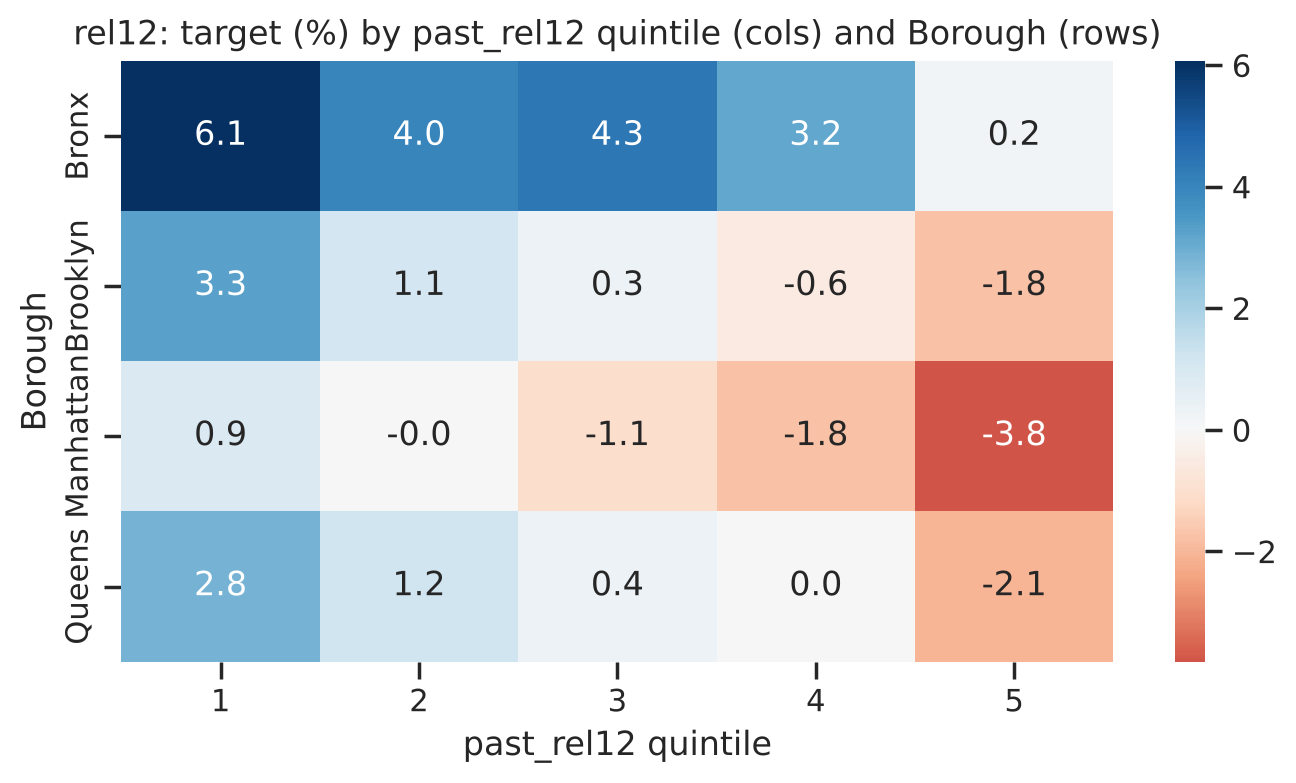

q,1,2,3,4,5,spread_q1_q5,rows
g,,,,,,,
Bronx,0.0607,0.0401,0.0433,0.0317,0.0024,0.0583,504
Brooklyn,0.0332,0.0111,0.0033,-0.0055,-0.0178,0.0511,2240
Manhattan,0.0091,-0.0003,-0.0106,-0.0179,-0.0381,0.0472,1680
Queens,0.0285,0.0118,0.0037,0.0000,-0.0205,0.0490,1176


In [78]:
two_way("rel12", "past_rel12", "Borough")

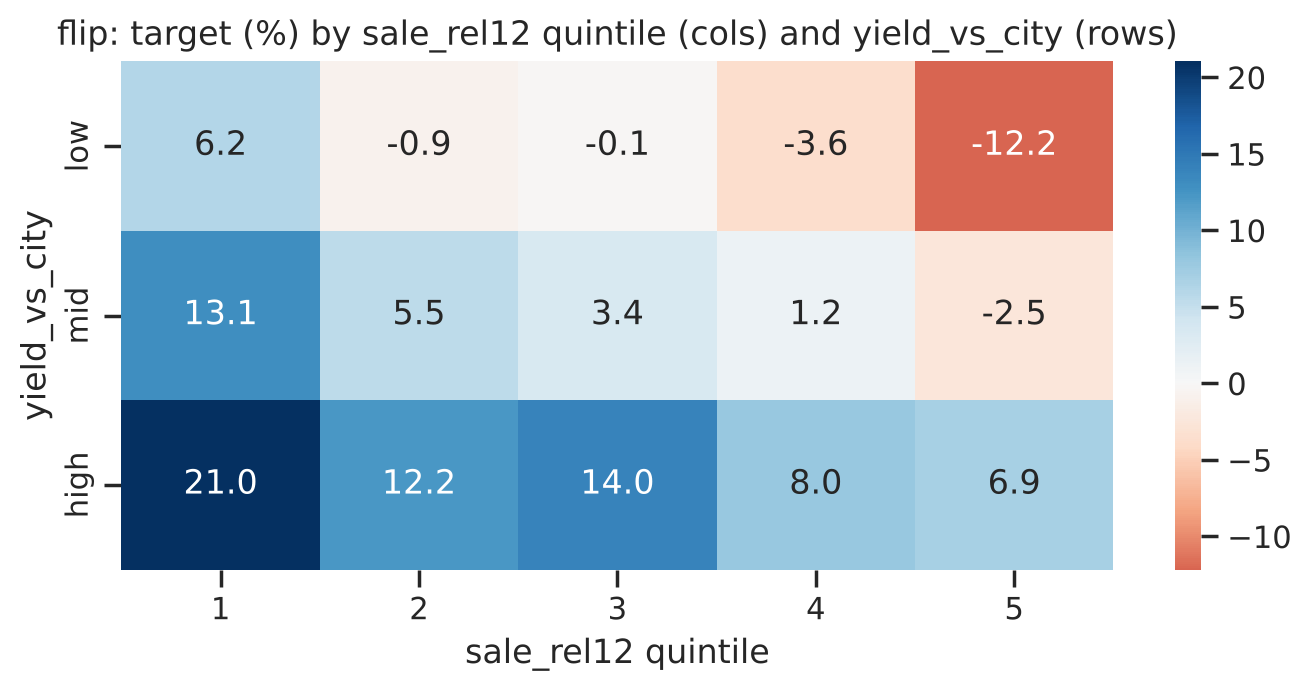

q,1,2,3,4,5,spread_q1_q5,rows
g,,,,,,,
low,0.0623,-0.0089,-0.0014,-0.0362,-0.1217,0.1841,1839
mid,0.1310,0.0552,0.0337,0.0124,-0.0246,0.1556,1792
high,0.2104,0.1225,0.1399,0.0798,0.0692,0.1412,1824


In [79]:
two_way("flip", "sale_rel12", "yield_vs_city")

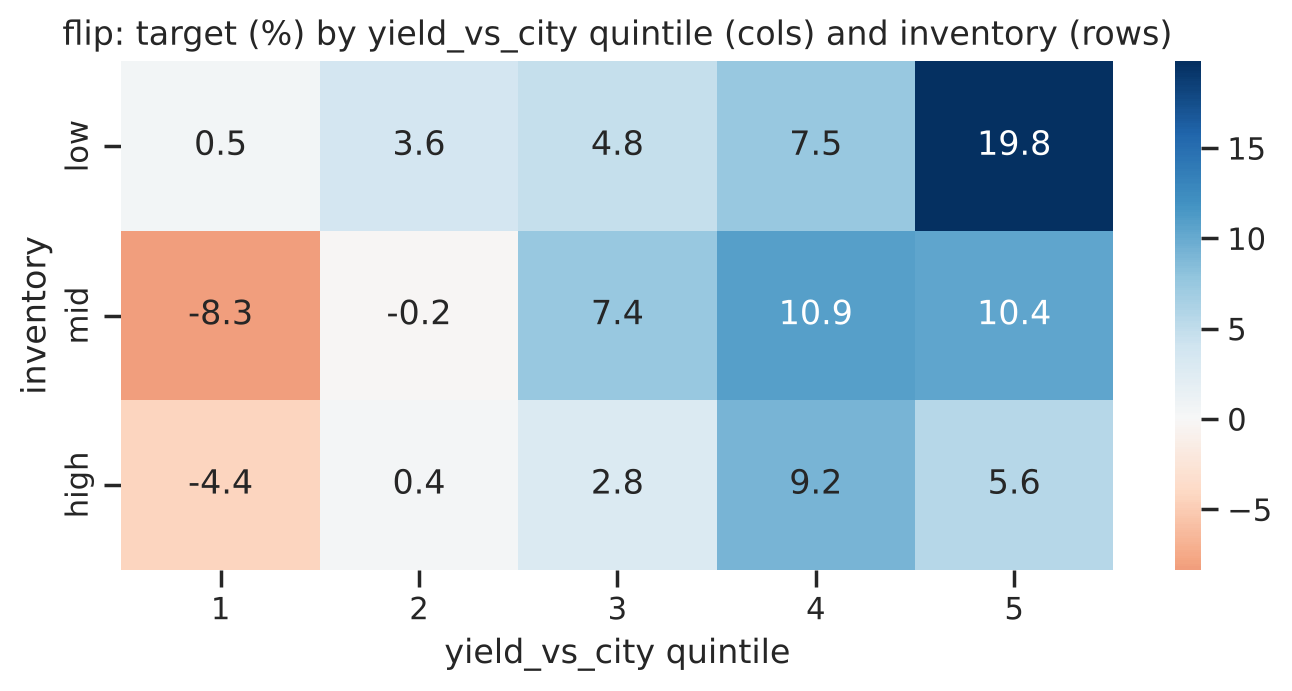

q,1,2,3,4,5,spread_q1_q5,rows
g,,,,,,,
low,0.0046,0.0356,0.0481,0.0749,0.1979,-0.1933,1842
mid,-0.0835,-0.0024,0.0744,0.1092,0.1041,-0.1876,1800
high,-0.0435,0.0041,0.0279,0.0921,0.0562,-0.0998,1838


In [80]:
two_way("flip", "yield_vs_city", "inventory")

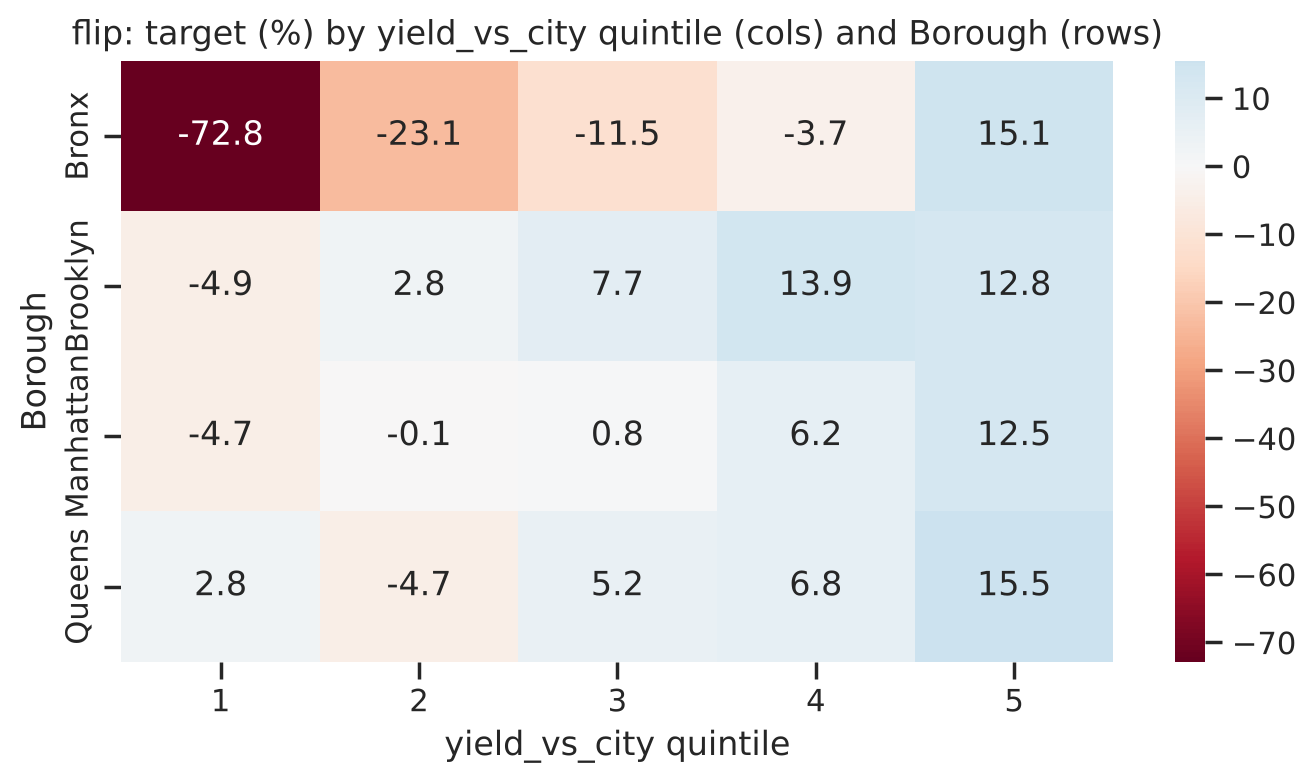

q,1,2,3,4,5,spread_q1_q5,rows
g,,,,,,,
Bronx,-0.7281,-0.2312,-0.1154,-0.0374,0.1506,-0.8787,440
Brooklyn,-0.0488,0.0280,0.0768,0.1388,0.1281,-0.1769,2240
Manhattan,-0.0465,-0.0006,0.0076,0.0621,0.1251,-0.1716,1624
Queens,0.0277,-0.0465,0.0521,0.0676,0.1547,-0.1270,1176


In [81]:
two_way("flip", "yield_vs_city", "Borough")

In [82]:
ic = pd.concat([interaction_cv(t, a, b) for t, a, b in PAIRS if b != "Borough"], ignore_index=True)
ic.pivot_table(index=["task", "pair"], columns="model", values=["cv_mae", "cv_rank"]).round(4)

cv_mae                            \
model                             main + other main + other + main*other   
task   pair                                                                
flip   sale_rel12 x yield_vs_city       0.1404                    0.1404   
       yield_vs_city x inventory        0.1425                    0.1432   
rel12  past_rel12 x cut_vs_city         0.0435                    0.0435   
       past_rel12 x inventory           0.0448                    0.0450   
renter mom6 x inventory                 0.0379                    0.0379   
       mom6 x rent_cut_share            0.0372                    0.0373   

                                       cv_rank                            
model                             main + other main + other + main*other  
task   pair                                                               
flip   sale_rel12 x yield_vs_city       0.2848                    0.2870  
       yield_vs_city x inventory        0.1578                    0.1631  
rel12  past_rel12 x cut_vs_city         0.1994                    0.1984  
       past_rel12 x inventory           0.1613                    0.1591  
renter mom6 x inventory                 0.3256                    0.3284  
       mom6 x rent_cut_share            0.3259                    0.3201

In [83]:
def feat_cv(task, sets, alpha=10):
    target, h, _ = TASKS[task]
    f = TD[task]
    rows = []
    for name, feats in sets.items():
        for (tr, va), y in zip(cv_splits(f, h), CV_YEARS):
            m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha)).fit(f.loc[tr, feats], f.loc[tr, target])
            p = m.predict(f.loc[va, feats])
            rows.append({"set": name, "year": y, "mae": mean_absolute_error(f.loc[va, target], p),
                         "rank": month_rank(f.loc[va, "date"], f.loc[va, target], p)})
    r = pd.DataFrame(rows)
    display(r.pivot_table(index="set", columns="year", values="rank").round(3))
    return r.groupby("set")[["mae", "rank"]].mean().round(4)

feat_cv("rel12", {"past_rel12": ["past_rel12"],
                  "past_rel12 + log_rent": ["past_rel12", "log_rent"],
                  "past_rel12 + log_rent + rent_vs_boro + cut_vs_city + log_inv": ["past_rel12", "log_rent", "rent_vs_boro", "cut_vs_city", "log_inv"],
                  "all MARKET + CITY + BORO": MARKET + CITY + BORO,
                  "all + log_rent": MARKET + CITY + BORO + ["log_rent"]})

year,2017,2018,2019,2022
set,,,,
all + log_rent,0.345,-0.009,-0.051,0.485
all MARKET + CITY + BORO,0.347,-0.011,-0.055,0.462
past_rel12,0.146,0.251,0.105,0.385
past_rel12 + log_rent,0.307,-0.058,-0.124,0.521
past_rel12 + log_rent + rent_vs_boro + cut_vs_city + log_inv,0.307,-0.086,-0.157,0.525


,mae,rank
set,,
all + log_rent,0.0473,0.1928
all MARKET + CITY + BORO,0.0463,0.1859
past_rel12,0.0433,0.2217
past_rel12 + log_rent,0.0454,0.1617
past_rel12 + log_rent + rent_vs_boro + cut_vs_city + log_inv,0.0459,0.1473


## L. Remaining checks

L1. Rent increase range: expected 12m rent growth per neighborhood + a "normal" range (10th–90th percentile of model errors). Is the range honest on the test?
L2. Renter: lock a 2-year lease or renew yearly, based on that forecast.
L3. Citywide rent: can we predict next year's city growth better than its long-run average?
L4. Flip with a 2-year hold (costs spread over 2 years).
L5. Live forecast from the latest month (2026-09).

In [84]:
def ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10))

TASKS["rent12"] = ("t_chg12", 12, FLIP)
TD["rent12"] = task_data("t_chg12", 12)
f = TD["rent12"]
oof = []
for tr, va in cv_splits(f, 12):
    x = f.loc[va].copy()
    x["pred"] = ridge().fit(f.loc[tr, FLIP], f.loc[tr, "t_chg12"]).predict(x[FLIP])
    x["long_run"] = f.loc[tr, "t_chg12"].mean()
    oof.append(x)
oof = pd.concat(oof)
lo_q, hi_q = np.quantile(oof.t_chg12 - oof.pred, [0.1, 0.9])

tr = f[f.dev & ~f.covid & ~f.out]
te = f[~f.dev & (f.date >= TEST_START)].copy()
te["pred"] = ridge().fit(tr[FLIP], tr.t_chg12).predict(te[FLIP])
te["long_run"] = tr.t_chg12.mean()

rows = []
for name, x in [("CV", oof), ("test", te)]:
    inside = (x.t_chg12 >= x.pred + lo_q) & (x.t_chg12 <= x.pred + hi_q)
    rows.append({"set": name, "mae_model": mean_absolute_error(x.t_chg12, x.pred),
                 "mae_long_run_avg": mean_absolute_error(x.t_chg12, x.long_run),
                 "mae_last_year": mean_absolute_error(x.t_chg12, x.past_chg12.fillna(0)),
                 "range_coverage": inside.mean(), "range_width_pts": 100 * (hi_q - lo_q)})
pd.DataFrame(rows).round(4)

,set,mae_model,mae_long_run_avg,mae_last_year,range_coverage,range_width_pts
0,CV,0.0537,0.0486,0.0881,0.8000,16.8792
1,test,0.0519,0.0552,0.0852,0.7914,16.8792


In [85]:
x = te.copy()
x["err"] = x.t_chg12 - x.pred
x["year"] = x.date.dt.year
x.groupby("year").agg(actual=("t_chg12", "mean"), predicted=("pred", "mean"), coverage=("err", lambda e: ((e >= lo_q) & (e <= hi_q)).mean())).round(3)

,actual,predicted,coverage
year,,,
2024,0.045,0.046,0.802
2025,0.047,0.052,0.778


In [86]:
def lease_lock(x, bump):
    r0 = x.rent_3m
    r1 = r0 * np.exp(x.t_chg12)
    gain = r1 - r0 * (1 + bump)
    return pd.Series({"always 12m": 0.0,
                      "always 24m": gain.mean(),
                      "model (lock if pred > bump)": gain.where(x.pred > np.log(1 + bump), 0).mean(),
                      "oracle": gain.clip(lower=0).mean(),
                      "share locked by model": (x.pred > np.log(1 + bump)).mean()})

pd.DataFrame({f"{name}, 2y lease bump {b:.0%}": lease_lock(x, b)
              for name, x in [("CV", oof), ("test", te)] for b in [0.0, 0.03]}).round(2)

,"CV, 2y lease bump 0%","CV, 2y lease bump 3%","test, 2y lease bump 0%","test, 2y lease bump 3%"
always 12m,0.00,0.00,0.00,0.00
always 24m,78.21,-5.61,181.29,73.89
model (lock if pred > bump),51.06,6.84,175.19,78.70
oracle,113.89,64.90,219.77,143.77
share locked by model,0.70,0.38,0.97,0.78


set     dev  test
months   68    21


,long_run_avg,last_year,ar1
set,,,
dev,0.0175,0.0380,0.0195
test,0.0162,0.0212,0.0172


AR slope (latest): 0.12 (<0 = city growth mean-reverts, >0 = momentum)


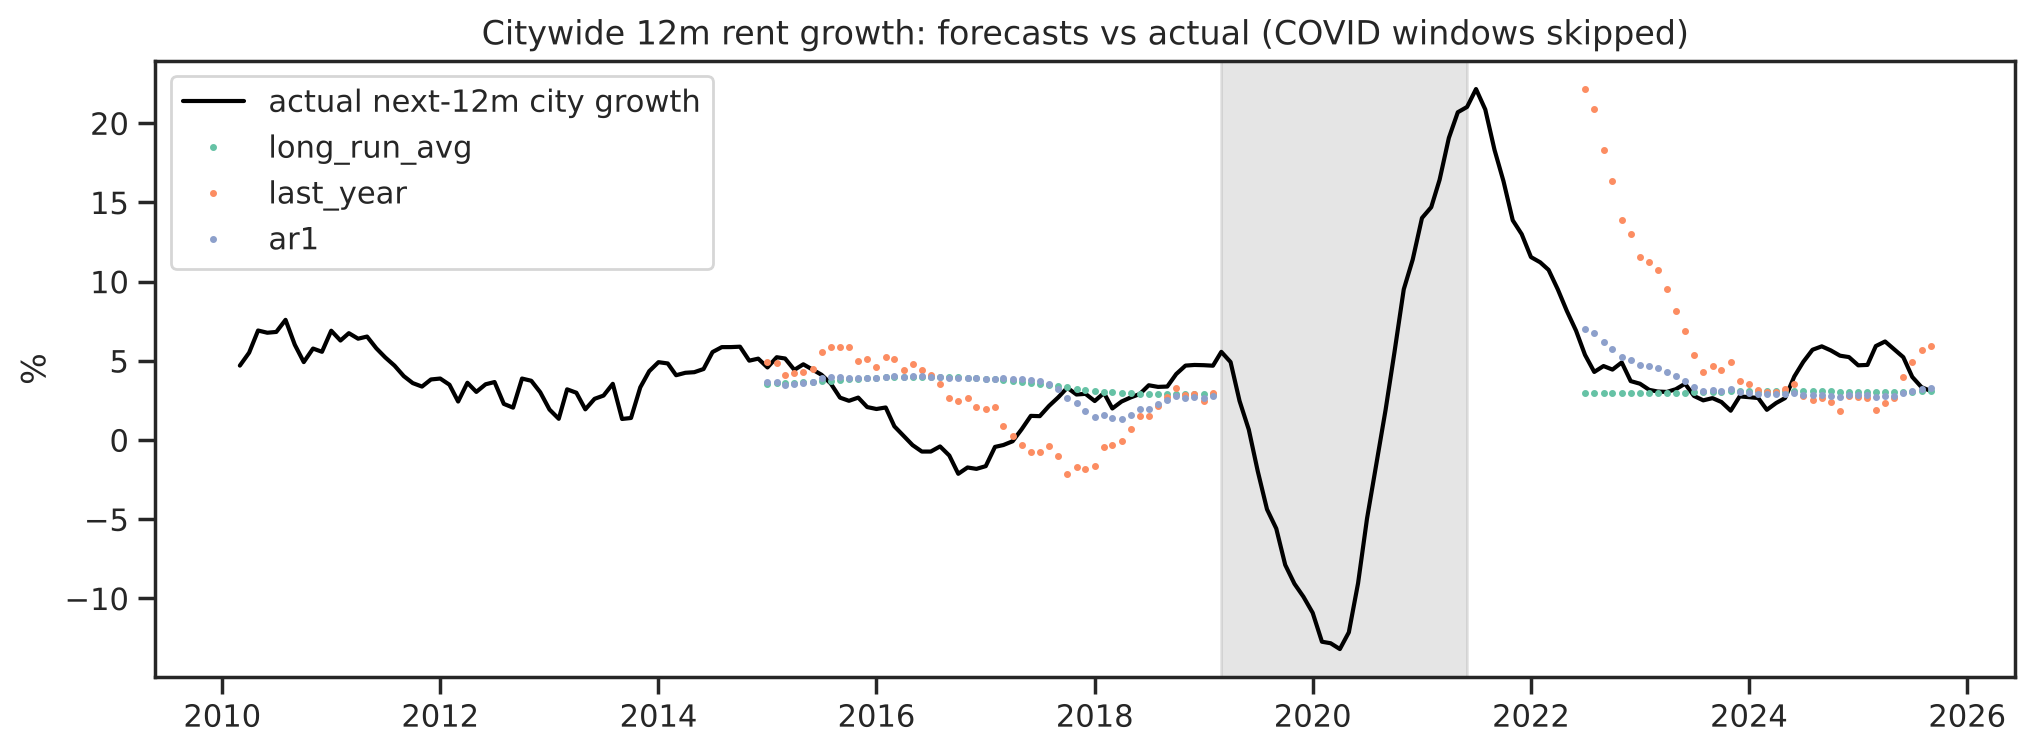

In [87]:
city = pd.DataFrame({"fwd": d.groupby("date").t_chg12.median(), "past": d.groupby("date").past_chg12.median()}).reset_index()
mi = city.date.dt.year * 12 + city.date.dt.month
city["covid"] = (mi + 12 >= c_start) & (mi - 12 <= c_end)
city["mi"] = mi
rows = []
for _, r in city[(city.date >= START) & city.fwd.notna() & city.past.notna() & ~city.covid].iterrows():
    tr = city[(city.mi + 12 <= r.mi) & ~city.covid & city.fwd.notna() & city.past.notna() & (city.date >= "2011-01-01")]
    b = np.polyfit(tr.past, tr.fwd, 1)
    rows.append({"date": r.date, "actual": r.fwd, "long_run_avg": tr.fwd.mean(), "last_year": r.past, "ar1": np.polyval(b, r.past), "slope": b[0]})
cf = pd.DataFrame(rows)
cf["set"] = np.where(cf.date >= TEST_START, "test", "dev")
print(cf.groupby("set")[["actual"]].count().rename(columns={"actual": "months"}).T)
display(cf.groupby("set").apply(lambda x: pd.Series({m: mean_absolute_error(x.actual, x[m]) for m in ["long_run_avg", "last_year", "ar1"]})).round(4))
print("AR slope (latest):", round(cf.slope.iloc[-1], 2), "(<0 = city growth mean-reverts, >0 = momentum)")

plt.figure(figsize=(12, 4))
plt.plot(city.date, city.fwd * 100, color="k", label="actual next-12m city growth")
for m in ["long_run_avg", "last_year", "ar1"]:
    plt.plot(cf.date, cf[m] * 100, ".", ms=3, label=m)
plt.axvspan(pd.Timestamp("2019-03-01"), pd.Timestamp("2021-06-01"), color="gray", alpha=0.2)
plt.ylabel("%")
plt.title("Citywide 12m rent growth: forecasts vs actual (COVID windows skipped)")
plt.legend()
plt.show()

In [88]:
d["t_sale_chg24"] = d.groupby("areaName").log_sale3.shift(-24) - d.log_sale3
f24 = d[(d.date >= "2011-04-01") & d.t_sale_chg24.notna()].reset_index(drop=True)
f24["covid"] = covid_mask(f24, 24)
tr24 = f24[(f24.date < TEST_START - pd.DateOffset(months=24)) & ~f24.covid]
te24 = f24[f24.date >= TEST_START].copy()
te24["pred"] = ridge().fit(tr24[YIELD_F], tr24.t_sale_chg24).predict(te24[YIELD_F])
print("train origins:", tr24.date.min().date(), "->", tr24.date.max().date(), "| test origins:", te24.date.min().date(), "->", te24.date.max().date())

rows = []
for k in [3, 5, 10, 20]:
    row = {"k": k}
    for n in ["pred", "yield_vs_city"]:
        row[n] = usd(te24.sort_values(n, ascending=False).groupby("date").head(k).t_sale_chg24.mean())
    rows.append(row)
out = pd.DataFrame(rows).set_index("k").rename(columns={"pred": "ridge 24m hold", "yield_vs_city": "yield only 24m hold"})
out["random 24m hold"] = usd(te24.t_sale_chg24.mean())
out.round(-2)

train origins: 2011-04-01 -> 2018-02-01 | test origins: 2024-01-01 -> 2024-09-01


,ridge 24m hold,yield only 24m hold,random 24m hold
k,,,
3,7300.0,-52000.0,-65000.0
5,-3300.0,-60700.0,-65000.0
10,-24800.0,-56300.0,-65000.0
20,-41200.0,-36600.0,-65000.0


In [89]:
LAST = d.date.max()

def live(task_feats, target, frame_filter):
    f = d[frame_filter & d[target].notna()]
    q1, q3 = f[target].quantile([0.25, 0.75])
    f = f[(f[target] >= q1 - 1.5 * (q3 - q1)) & (f[target] <= q3 + 1.5 * (q3 - q1))]
    m = ridge().fit(f[task_feats], f[target])
    now = d[d.date == LAST].copy()
    now["pred"] = m.predict(now[task_feats])
    return now

base_filter = lambda h: (d.date >= START) & ~covid_mask(d, h)

now_r = live(MARKET + CITY + BORO, "t_chg3", base_filter(3))
now_r["pred_pct"] = 100 * (np.exp(now_r.pred) - 1)
now_r["usd_month"] = now_r.rent_3m * (np.exp(now_r.pred) - 1)
cols = ["areaName", "Borough", "rent_3m", "pred_pct", "usd_month"]
print(f"Renter, {LAST.date()} -> 3 months ahead")
display(pd.concat([now_r.nsmallest(10, "pred")[cols].assign(side="likely to drop"),
                   now_r.nlargest(10, "pred")[cols].assign(side="likely to rise")]).round(1))

Renter, 2026-09-01 -> 3 months ahead


,areaName,Borough,rent_3m,pred_pct,usd_month,side
5024,Concourse,Bronx,3222.3,-6.2,-198.2,likely to drop
3818,Central Park South,Manhattan,14500.0,-4.6,-669.3,likely to drop
4823,Columbia St Waterfront District,Brooklyn,4866.7,-3.7,-181.2,likely to drop
11255,Jamaica Estates,Queens,2808.3,-3.7,-102.7,likely to drop
12260,Little Italy,Manhattan,5399.3,-3.4,-183.5,likely to drop
18290,Tribeca,Manhattan,9296.7,-1.9,-177.6,likely to drop
10853,Jackson Heights,Queens,2816.7,-1.6,-45.7,likely to drop
19496,West Village,Manhattan,6196.7,-1.4,-84.4,likely to drop
15074,Park Slope,Brooklyn,4675.0,-1.2,-57.1,likely to drop
8039,Flatiron,Manhattan,6530.0,-1.2,-76.6,likely to drop


Rent increase guide, 2026-09-01 -> 12 months. Above 'above_market_pct' = higher than 9 of 10 similar cases.


,areaName,Borough,rent_3m,expected_pct,normal_low_pct,above_market_pct
3818,Central Park South,Manhattan,14500.0,-7.5,-13.9,1.9
5024,Concourse,Bronx,3222.3,-2.0,-8.8,8.0
4823,Columbia St Waterfront District,Brooklyn,4866.7,1.2,-5.8,11.5
18290,Tribeca,Manhattan,9296.7,1.7,-5.3,12.1
15878,Red Hook,Brooklyn,4863.3,2.2,-4.9,12.6
11255,Jamaica Estates,Queens,2808.3,2.5,-4.6,13.0
19496,West Village,Manhattan,6196.7,2.6,-4.6,13.0
5828,DUMBO,Brooklyn,6224.3,2.7,-4.4,13.1
3215,Canarsie,Brooklyn,2883.3,8.9,1.4,20.0
401,Bath Beach,Brooklyn,2215.0,9.3,1.7,20.4


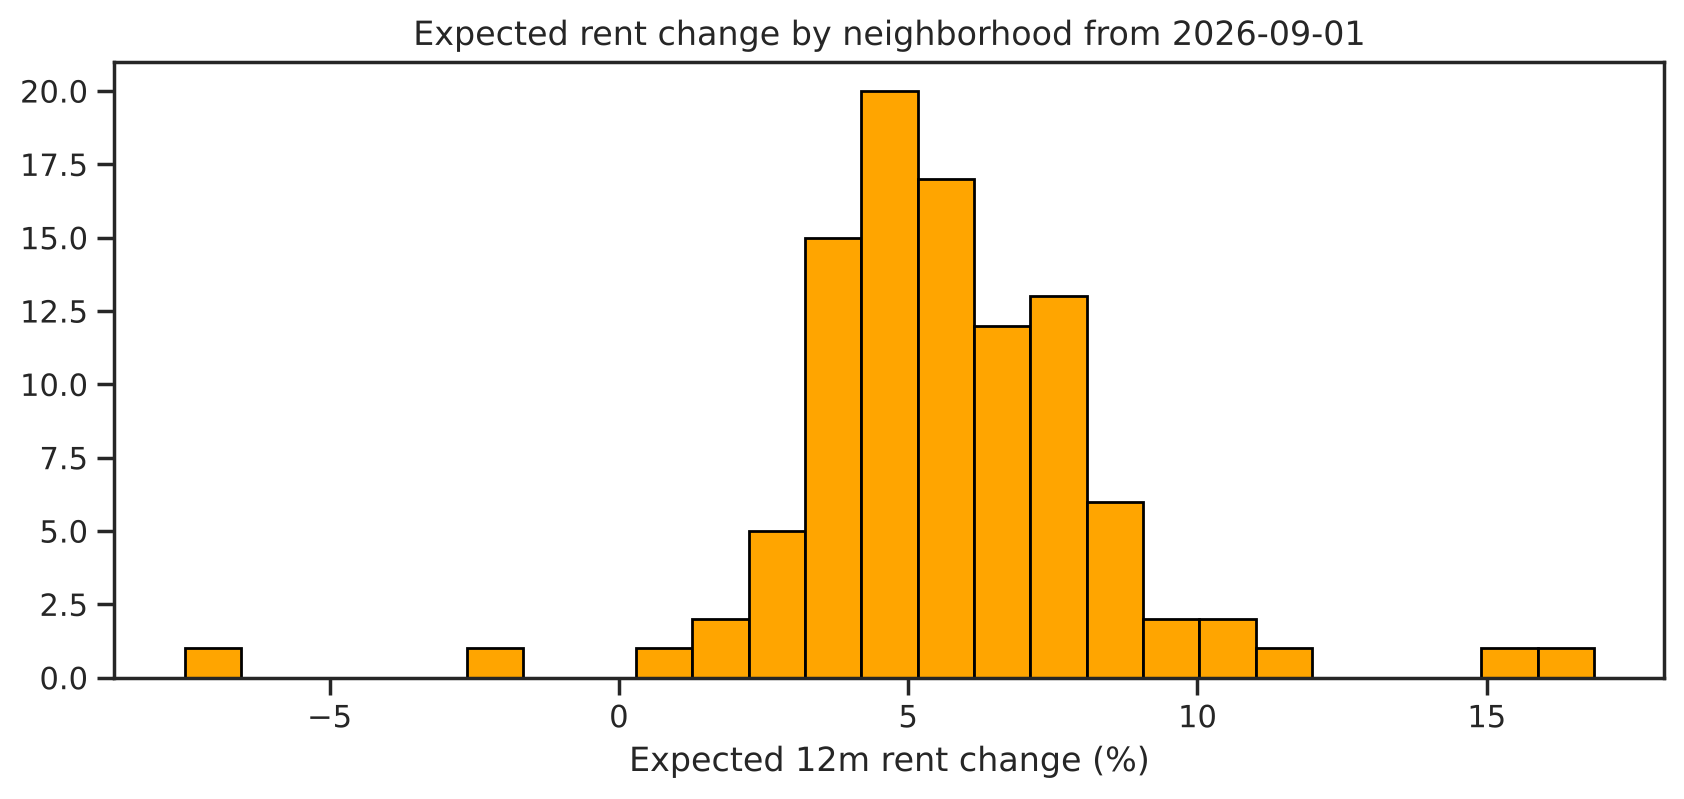

In [90]:
now_12 = live(FLIP, "t_chg12", base_filter(12))
now_12["expected_pct"] = 100 * (np.exp(now_12.pred) - 1)
now_12["normal_low_pct"] = 100 * (np.exp(now_12.pred + lo_q) - 1)
now_12["above_market_pct"] = 100 * (np.exp(now_12.pred + hi_q) - 1)
tab = now_12[["areaName", "Borough", "rent_3m", "expected_pct", "normal_low_pct", "above_market_pct"]].sort_values("expected_pct")
print(f"Rent increase guide, {LAST.date()} -> 12 months. Above 'above_market_pct' = higher than 9 of 10 similar cases.")
display(pd.concat([tab.head(8), tab.tail(8)]).round(1))

plt.figure(figsize=(10, 4))
plt.hist(now_12.expected_pct, bins=25, color="orange", edgecolor="black")
plt.xlabel("Expected 12m rent change (%)")
plt.title(f"Expected rent change by neighborhood from {LAST.date()}")
plt.show()

In [91]:
now_f = live(YIELD_F, "t_sale_chg12", base_filter(12))
now_f["sale_3m_k"] = now_f.sale_3m / 1000
now_f["yield_pct"] = 100 * now_f["yield"]
now_f["pred_pct"] = 100 * (np.exp(now_f.pred) - 1)
print(f"Flip candidates, {LAST.date()} -> 12 months (sale price change, before 8% costs)")
now_f.nlargest(10, "pred")[["areaName", "Borough", "sale_3m_k", "yield_pct", "pred_pct"]].round(1)

Flip candidates, 2026-09-01 -> 12 months (sale price change, before 8% costs)


,areaName,Borough,sale_3m_k,yield_pct,pred_pct
17084,Sheepshead Bay,Brooklyn,527.0,6.4,7.4
11255,Jamaica Estates,Queens,1265.0,2.7,6.7
14873,Norwood,Bronx,192.2,11.8,6.7
4823,Columbia St Waterfront District,Brooklyn,1865.0,3.1,5.8
4421,Clinton Hill,Brooklyn,990.1,5.3,4.7
1004,Bayside,Queens,577.3,6.4,4.5
6029,Ditmas Park,Brooklyn,708.3,5.1,4.3
14069,Midwood,Brooklyn,624.8,5.4,4.1
5225,Coney Island,Brooklyn,461.0,8.5,4.1
10853,Jackson Heights,Queens,411.5,8.2,4.1


## M. Neighborhood card: "I want to rent in X" / "I want to buy in X"

Everything the data can say about one neighborhood, with how reliable each part is.
First a check that a neighborhood's own seasonal pattern repeats (otherwise "best month" per neighborhood is noise).

In [92]:
def season_profile(x):
    x = x.dropna(subset=["rent"]).copy()
    x["lr"] = np.log(x.rent)
    x["trend"] = x.lr.rolling(13, center=True, min_periods=13).mean()
    x["dev"] = x.lr - x.trend
    return x.groupby(x.date.dt.month).dev.mean()

early = d[(d.date >= "2011-01-01") & (d.date < "2019-01-01")]
late = d[d.date >= "2022-01-01"]
rows = []
for name, x in d.groupby("areaName"):
    e = season_profile(early[early.areaName == name])
    l = season_profile(late[late.areaName == name])
    b = season_profile(early[early.Borough == x.Borough.iloc[0]].groupby("date", as_index=False).agg(rent=("rent", "median")))
    if len(e) == 12 and len(l) == 12:
        rows.append({"areaName": name, "inv": x.inventory.median(), "corr_early_late": e.corr(l),
                     "own_mae": (e - l).abs().mean(), "borough_mae": (b - l).abs().mean()})
sp = pd.DataFrame(rows)
sp["inv_bucket"] = pd.cut(sp.inv, [0, 100, 300, np.inf], labels=["<=100", "101-300", ">300"])
print("own pattern beats borough pattern in", f"{(sp.own_mae < sp.borough_mae).mean():.0%}", "of neighborhoods")
sp.groupby("inv_bucket", observed=True)[["corr_early_late", "own_mae", "borough_mae"]].median().round(4)

own pattern beats borough pattern in 38% of neighborhoods


,corr_early_late,own_mae,borough_mae
inv_bucket,,,
<=100,0.1150,0.0394,0.0300
101-300,0.4591,0.0225,0.0193
>300,0.6545,0.0150,0.0191


===== Tribeca (Manhattan) — Sep 2026 =====
Rent now (3m avg): $9,297 | last 12m: -8.4% (city +3.1%)
Listings: 245 vs 229 avg for Sep (last 5y) | price cuts: 12% vs 19% usual
Sale price (3m avg): $4,531,667 | gross yield 2.5% (city median 4.7%)
RENT next 3m: -1.9% (80% range -7.1% to +3.9%) | model error here vs avg: 0.072 vs 0.035
RENT next 12m: +1.7% (normal -5.3% to +12.1%) | Good Cause cap 8.38%
SALE next 12m: -9.9% (80% range -30.4% to +2.9%) | flip costs ~8%
Own seasonal pattern repeat (corr early vs late): 0.27


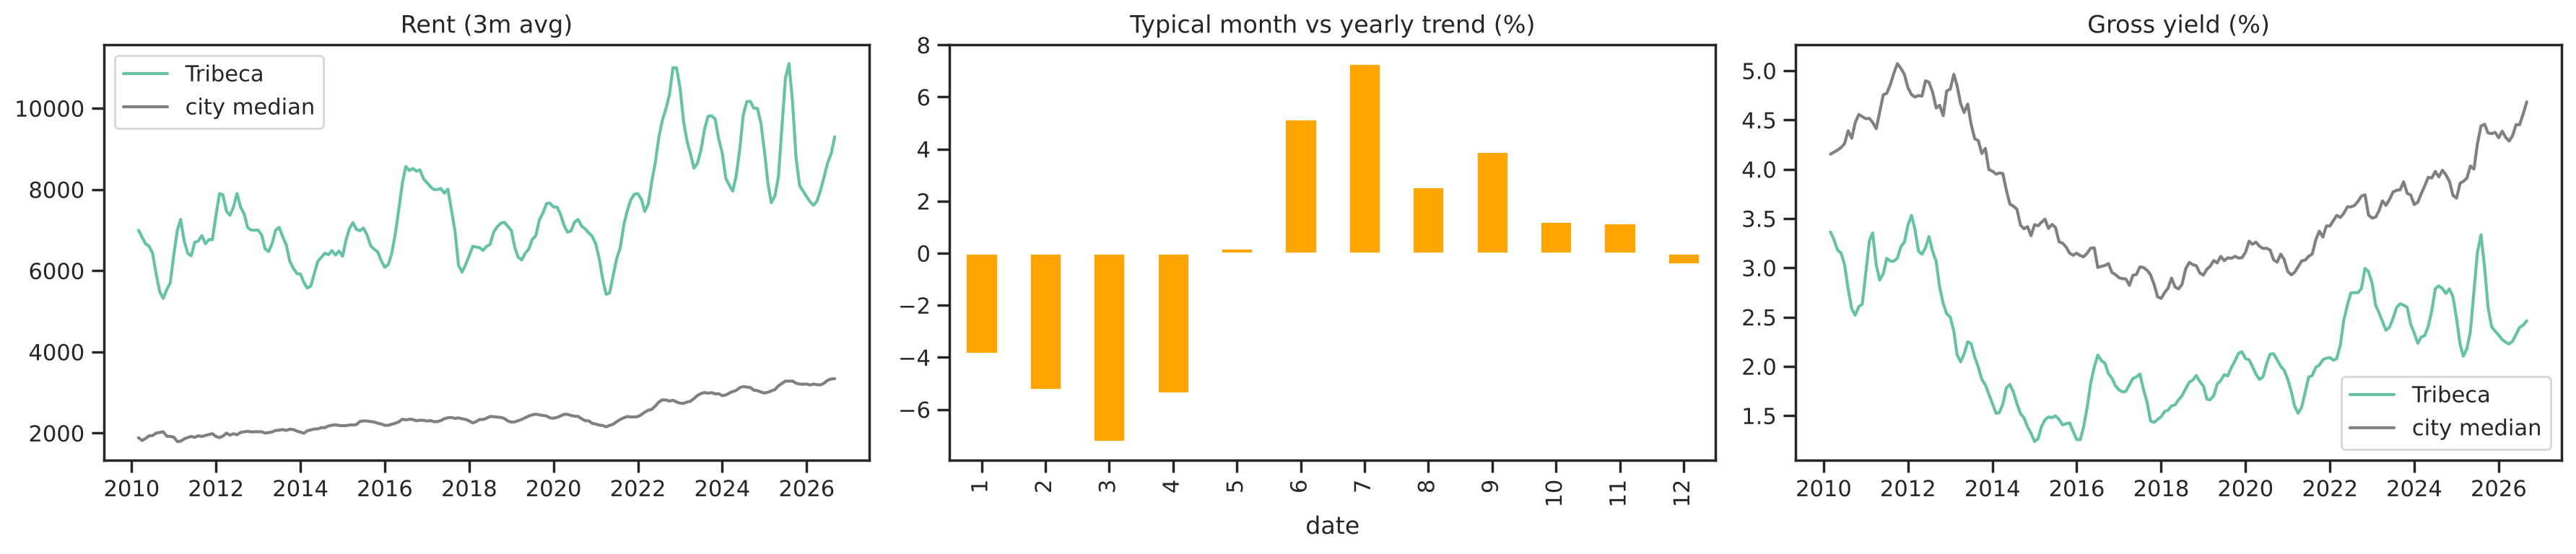

Similar neighborhoods (kNN on rent level, yield, momentum, listings, cuts):


,Borough,rent_3m,sale_3m,yield,distance,cheaper_rent
areaName,,,,,,
Soho,Manhattan,6200.000,3916666.667,0.019,1.49,True
Nolita,Manhattan,5415.000,3372500.000,0.019,2.09,True
Boerum Hill,Brooklyn,4833.333,2577500.000,0.023,2.19,True
Gramercy Park,Manhattan,5496.667,1370666.667,0.048,2.21,True
Fort Greene,Brooklyn,4493.333,1338333.333,0.040,2.30,True


In [93]:
def q_range(oof_frame, target, model="ridge"):
    return np.quantile(oof_frame[target] - oof_frame[model], [0.1, 0.9])

r3_lo, r3_hi = q_range(OOF["renter"], "t_chg3")
s12_lo, s12_hi = q_range(OOF["flip"], "t_sale_chg12")
GOOD_CAUSE = 0.0838

err_by_area = OOF["renter"].assign(e=(OOF["renter"].t_chg3 - OOF["renter"].ridge).abs()).groupby("areaName").e.mean()

SIM_F = ["log_rent", "yield", "past_rel12", "log_inv", "rent_cut_share"]
snap = d[d.date == LAST].set_index("areaName")
Z = snap[SIM_F].dropna()
Z = (Z - Z.mean()) / Z.std()

def similar(name, k=5):
    dist = np.sqrt(((Z - Z.loc[name]) ** 2).sum(axis=1)).drop(name)
    out = snap.loc[dist.nsmallest(k).index, ["Borough", "rent_3m", "sale_3m", "yield"]].copy()
    out["distance"] = dist.nsmallest(k).round(2)
    out["cheaper_rent"] = out.rent_3m < snap.loc[name, "rent_3m"]
    return out.round(3)

def card(name):
    x = d[d.areaName == name].sort_values("date")
    now = x[x.date == LAST].iloc[0]
    m = LAST.month
    same_month = x[(x.date.dt.month == m) & (x.date < LAST) & (x.date >= LAST - pd.DateOffset(years=5))]
    print(f"===== {name} ({now.Borough}) — {LAST:%b %Y} =====")
    print(f"Rent now (3m avg): ${now.rent_3m:,.0f} | last 12m: {100 * (np.exp(now.past_chg12) - 1):+.1f}% (city {100 * (np.exp(now.past_chg12 - now.past_rel12) - 1):+.1f}%)")
    print(f"Listings: {now.inventory:.0f} vs {same_month.inventory.mean():.0f} avg for {LAST:%b} (last 5y) | price cuts: {now.rent_cut_share:.0%} vs {same_month.rent_cut_share.mean():.0%} usual")
    print(f"Sale price (3m avg): ${now.sale_3m:,.0f} | gross yield {now['yield']:.1%} (city median {d[d.date == LAST]['yield'].median():.1%})")
    r = now_r.set_index("areaName").loc[name]
    print(f"RENT next 3m: {100 * (np.exp(r.pred) - 1):+.1f}% (80% range {100 * (np.exp(r.pred + r3_lo) - 1):+.1f}% to {100 * (np.exp(r.pred + r3_hi) - 1):+.1f}%)"
          f" | model error here vs avg: {err_by_area.get(name, np.nan):.3f} vs {err_by_area.mean():.3f}")
    r12 = now_12.set_index("areaName").loc[name]
    print(f"RENT next 12m: {r12.expected_pct:+.1f}% (normal {r12.normal_low_pct:+.1f}% to {r12.above_market_pct:+.1f}%) | Good Cause cap {GOOD_CAUSE:.2%}")
    f12 = now_f.set_index("areaName").loc[name]
    print(f"SALE next 12m: {f12.pred_pct:+.1f}% (80% range {100 * (np.exp(f12.pred + s12_lo) - 1):+.1f}% to {100 * (np.exp(f12.pred + s12_hi) - 1):+.1f}%) | flip costs ~{COST:.0%}")
    row = sp.set_index("areaName").loc[name] if name in set(sp.areaName) else None
    if row is not None:
        print(f"Own seasonal pattern repeat (corr early vs late): {row.corr_early_late:.2f}")

    fig, axs = plt.subplots(1, 3, figsize=(18, 4))
    city_rent = d.groupby("date").rent_3m.median()
    xx = x.set_index("date")
    axs[0].plot(xx.rent_3m, label=name)
    axs[0].plot(city_rent, label="city median", color="gray")
    axs[0].set_title("Rent (3m avg)")
    axs[0].legend()
    prof = season_profile(x[x.date >= "2011-01-01"].copy()) * 100
    prof.plot(kind="bar", ax=axs[1], color="orange")
    axs[1].set_title("Typical month vs yearly trend (%)")
    axs[2].plot(xx["yield"] * 100, label=name)
    axs[2].plot(d.groupby("date")["yield"].median() * 100, label="city median", color="gray")
    axs[2].set_title("Gross yield (%)")
    axs[2].legend()
    plt.tight_layout()
    plt.show()
    print("Similar neighborhoods (kNN on rent level, yield, momentum, listings, cuts):")
    display(similar(name))

card("Tribeca")

===== Williamsburg (Brooklyn) — Sep 2026 =====
Rent now (3m avg): $5,087 | last 12m: +3.2% (city +3.1%)
Listings: 1334 vs 1498 avg for Sep (last 5y) | price cuts: 15% vs 18% usual
Sale price (3m avg): $1,735,383 | gross yield 3.5% (city median 4.7%)
RENT next 3m: -0.5% (80% range -5.8% to +5.4%) | model error here vs avg: 0.030 vs 0.035
RENT next 12m: +3.8% (normal -3.4% to +14.3%) | Good Cause cap 8.38%
SALE next 12m: +0.5% (80% range -22.4% to +14.7%) | flip costs ~8%
Own seasonal pattern repeat (corr early vs late): 0.92


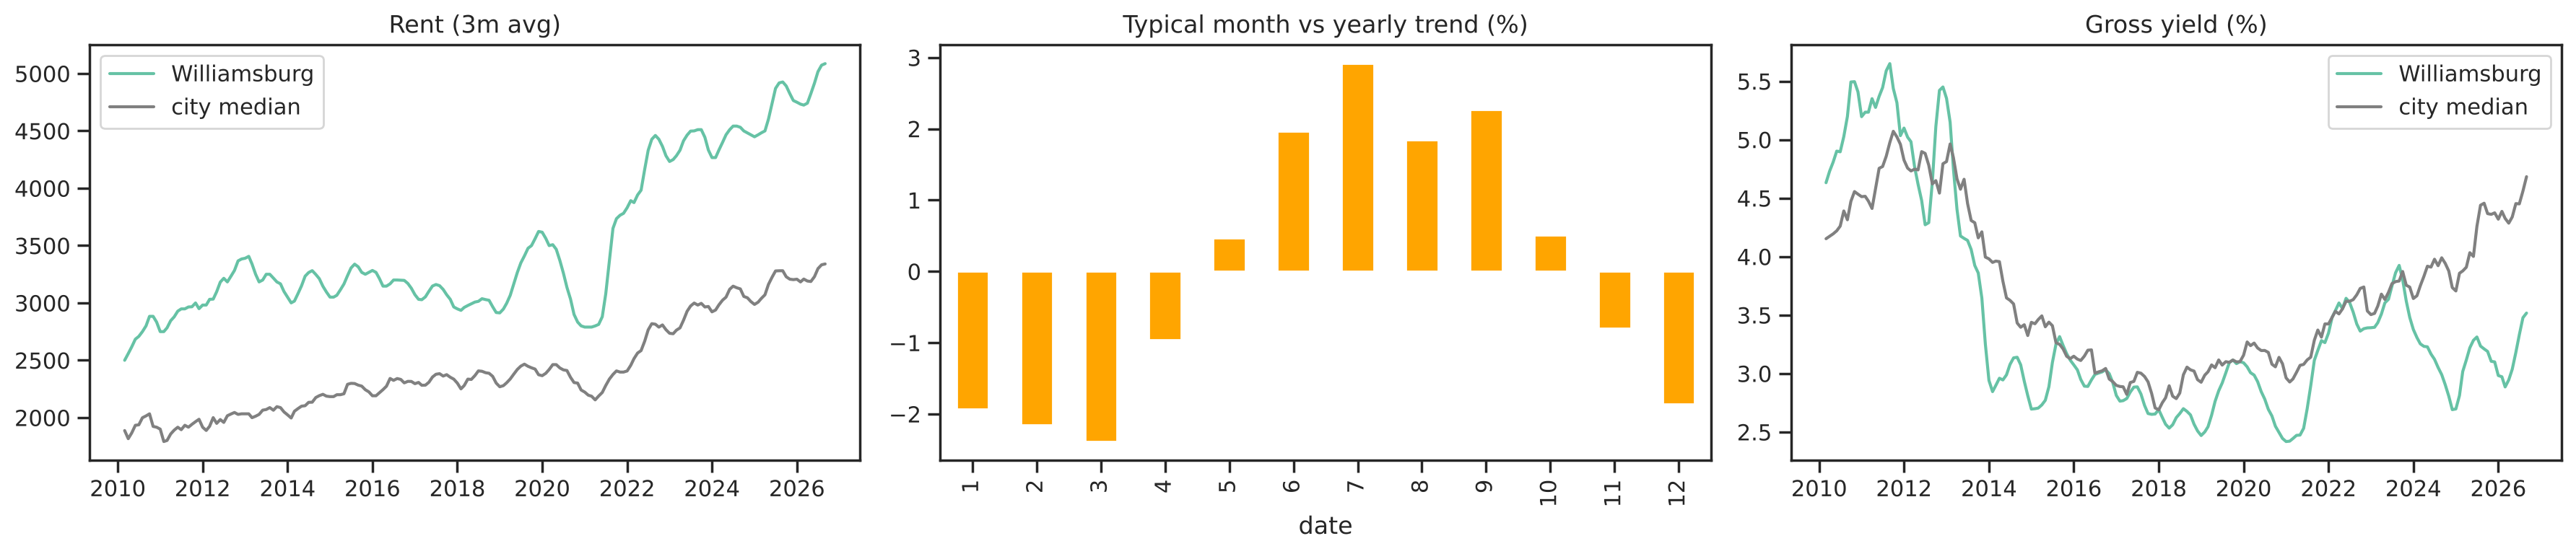

Similar neighborhoods (kNN on rent level, yield, momentum, listings, cuts):


,Borough,rent_3m,sale_3m,yield,distance,cheaper_rent
areaName,,,,,,
Upper East Side,Manhattan,4498.333,1530833.333,0.035,0.58,True
East Village,Manhattan,5035.000,1381333.333,0.044,0.72,True
Long Island City,Queens,4616.000,1154666.667,0.048,0.82,True
Downtown Brooklyn,Brooklyn,4688.000,1066333.333,0.053,0.85,True
Upper West Side,Manhattan,5030.000,1708333.333,0.035,0.87,True


In [94]:
card("Williamsburg")

### M2. Flip card for a specific apartment

Input: neighborhood, price, current rent.
Rent-based value uses the idea: value = 12 × rent / neighborhood yield (yield assumed constant for a year).
The apartment part is an indication only (neighborhood yield mixes different apartments for sale and for rent); the neighborhood forecast is the tested part.

In [95]:
def flip_card(name, price, rent):
    n = snap.loc[name]
    y_n = n["yield"]
    r12 = now_12.set_index("areaName").loc[name]
    f12 = now_f.set_index("areaName").loc[name]
    g, g_lo, g_hi = np.exp(r12.pred) - 1, np.exp(r12.pred + lo_q) - 1, np.exp(r12.pred + hi_q) - 1
    s, s_lo, s_hi = np.exp(f12.pred) - 1, np.exp(f12.pred + s12_lo) - 1, np.exp(f12.pred + s12_hi) - 1
    flip_rank = now_f.pred.rank(ascending=False)[now_f.areaName == name].iloc[0]
    rent_rank = now_12.pred.rank(ascending=False)[now_12.areaName == name].iloc[0]
    print(f"===== {name}: ${price:,.0f} apartment renting at ${rent:,.0f} =====")
    print(f"Apartment yield {12 * rent / price:.1%} vs neighborhood {y_n:.1%} (city {snap['yield'].median():.1%})")
    t = pd.Series({"value now (12×rent / nbhd yield)": 12 * rent / y_n,
                   "value in 12m, expected": 12 * rent * (1 + g) / y_n,
                   "value in 12m, low (10%)": 12 * rent * (1 + g_lo) / y_n,
                   "value in 12m, high (90%)": 12 * rent * (1 + g_hi) / y_n})
    t["gain in 12m from rent growth"] = t["value in 12m, expected"] - t["value now (12×rent / nbhd yield)"]
    t["gain vs price, expected"] = t["value in 12m, expected"] - price
    display(t.round(-3).to_frame("usd"))
    print(f"Neighborhood rent next 12m: {100 * g:+.1f}% ({100 * g_lo:+.1f}% to {100 * g_hi:+.1f}%) | rank {rent_rank:.0f} of {len(now_12)}")
    print(f"Neighborhood sale price next 12m (tested model): {100 * s:+.1f}% ({100 * s_lo:+.1f}% to {100 * s_hi:+.1f}%) | flip rank {flip_rank:.0f} of {len(now_f)}"
          f" -> on your price: {price * s:+,.0f} ({price * s_lo:+,.0f} to {price * s_hi:+,.0f})")

flip_card("Williamsburg", 600_000, 3_000)

===== Williamsburg: $600,000 apartment renting at $3,000 =====
Apartment yield 6.0% vs neighborhood 3.5% (city 4.7%)


,usd
value now (12×rent / nbhd yield),1023000.0
"value in 12m, expected",1062000.0
"value in 12m, low (10%)",989000.0
"value in 12m, high (90%)",1170000.0
gain in 12m from rent growth,39000.0
"gain vs price, expected",462000.0


Neighborhood rent next 12m: +3.8% (-3.4% to +14.3%) | rank 82 of 100
Neighborhood sale price next 12m (tested model): +0.5% (-22.4% to +14.7%) | flip rank 38 of 100 -> on your price: +2,713 (-134,252 to +88,387)


In [96]:
flip_card("Sheepshead Bay", 600_000, 3_000)

===== Sheepshead Bay: $600,000 apartment renting at $3,000 =====
Apartment yield 6.0% vs neighborhood 6.4% (city 4.7%)


,usd
value now (12×rent / nbhd yield),565000.0
"value in 12m, expected",609000.0
"value in 12m, low (10%)",567000.0
"value in 12m, high (90%)",671000.0
gain in 12m from rent growth,45000.0
"gain vs price, expected",9000.0


Neighborhood rent next 12m: +7.9% (+0.4% to +18.9%) | rank 17 of 100
Neighborhood sale price next 12m (tested model): +7.4% (-17.0% to +22.6%) | flip rank 1 of 100 -> on your price: +44,157 (-102,226 to +135,722)


## N. Renter by apartment size (Studio, 2BR, 3+BR)

Does a size-specific forecast beat the all-apartments forecast for the "wait or sign" question?
Compared on each size's own 3-month rent change: all-apartments model (same forecast for every size), size-specific model, seasonality (borough × month × size), random.
No 1BR file and no listing counts by size.

In [97]:
TYPES = ["Studio", "TwoBd", "ThreePlusBd"]
long = []
for t in TYPES:
    x = pd.read_csv(f"medianAskingRent_{t}.csv")
    x = x[x.areaType == "neighborhood"].melt(id_vars=["areaName", "Borough", "areaType"], var_name="month", value_name="rent_t")
    x["date"] = pd.to_datetime(x.month)
    x["type"] = t
    long.append(x[["areaName", "date", "type", "rent_t"]])
bt = pd.concat(long).merge(d[["areaName", "date", "Borough", "log_rent", "rent_3m", "t_chg3"] + MARKET + CITY + BORO], on=["areaName", "date"])
bt = bt.sort_values(["type", "areaName", "date"]).reset_index(drop=True)
bt["rent_t3"] = bt.groupby(["type", "areaName"]).rent_t.transform(lambda s: s.rolling(3).mean())
bt["lr_t"] = np.log(bt.rent_t3)
g = bt.groupby(["type", "areaName"]).lr_t
bt["t_type3"] = g.shift(-3) - bt.lr_t
bt["ty_mom3"] = bt.lr_t - g.shift(3)
bt["ty_mom6"] = bt.lr_t - g.shift(6)
bt["ty_past12"] = bt.lr_t - g.shift(12)
bt["ty_rel12"] = bt.ty_past12 - bt.groupby(["type", "date"]).ty_past12.transform("median")
bt["ty_vs_all"] = bt.lr_t - bt.log_rent
bt[["is_studio", "is_2bd", "is_3bd"]] = pd.get_dummies(bt.type, dtype=int)[["Studio", "TwoBd", "ThreePlusBd"]].values
bt["end_month"] = (bt.date.dt.month + 2) % 12 + 1
bt["covid"] = covid_mask(bt, 3)
bt = bt.replace([np.inf, -np.inf], np.nan)

TYPE_F = MARKET + CITY + BORO + ["ty_mom3", "ty_mom6", "ty_past12", "ty_rel12", "ty_vs_all", "is_studio", "is_2bd", "is_3bd"]
ALL_F = MARKET + CITY + BORO

cov = bt[bt.date >= START].groupby("type").agg(rows_with_target=("t_type3", lambda s: s.notna().mean()),
                                               neighborhoods=("areaName", "nunique"))
cov["neighborhoods_with_data_2026"] = bt[bt.date == LAST].groupby("type").rent_t.apply(lambda s: s.notna().sum())
cov.round(3)

,rows_with_target,neighborhoods,neighborhoods_with_data_2026
type,,,
Studio,0.863,100,91
ThreePlusBd,0.954,100,100
TwoBd,0.973,100,99


In [98]:
q_type = {}
for t in TYPES:
    x = bt[(bt.type == t) & (bt.date >= START) & (bt.date < TEST_START) & ~bt.covid].t_type3.dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    q_type[t] = (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
bt["out"] = [not (q_type[t][0] <= v <= q_type[t][1]) if pd.notna(v) else False for t, v in zip(bt.type, bt.t_type3)]

dall = d[(d.date >= START) & d.t_chg3.notna()].copy()
dall["covid"] = covid_mask(dall, 3)
qa1, qa3 = dall.loc[(dall.date < TEST_START) & ~dall.covid, "t_chg3"].quantile([0.25, 0.75])
dall["out"] = (dall.t_chg3 < qa1 - 1.5 * (qa3 - qa1)) | (dall.t_chg3 > qa3 + 1.5 * (qa3 - qa1))

def size_eval(train_end, val_mask):
    cut = train_end - pd.DateOffset(months=3)
    tr_a = dall[(dall.date < cut) & ~dall.covid & ~dall.out]
    tr_t = bt[(bt.date >= START) & (bt.date < cut) & ~bt.covid & ~bt.out & bt.t_type3.notna()]
    va = bt[val_mask & bt.t_type3.notna()].copy()
    va["all_model"] = ridge().fit(tr_a[ALL_F], tr_a.t_chg3).predict(va[ALL_F])
    va["size_model"] = ridge().fit(tr_t[TYPE_F], tr_t.t_type3).predict(va[TYPE_F])
    va["size_hgb"] = make_pipeline(SimpleImputer(strategy="median"), HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=13)).fit(tr_t[TYPE_F], tr_t.t_type3).predict(va[TYPE_F])
    va["season"] = va.join(tr_t.groupby(["Borough", "end_month", "type"]).t_type3.mean().rename("s"), on=["Borough", "end_month", "type"]).s.fillna(tr_t.t_type3.mean())
    return va

cv_va = pd.concat([size_eval(pd.Timestamp(f"{y}-01-01"), (bt.date.dt.year == y) & ~bt.covid).assign(year=y) for y in CV_YEARS])
te_va = size_eval(TEST_START, bt.date >= TEST_START).assign(year=lambda x: x.date.dt.year)

rng = np.random.default_rng(13)

def size_stats(x, col):
    saved = -(np.exp(x.t_type3) - 1) * x.rent_t3
    w = x[col] < 0
    return {"mae": mean_absolute_error(x.t_type3, x[col]), "rank": month_rank(x.date, x.t_type3, x[col]),
            "lift": top_lift(x.date, x.t_type3, x[col]), "direction": np.mean(np.sign(x[col]) == np.sign(x.t_type3)),
            "saved_when_wait": saved[w].mean() if w.any() else np.nan}

def size_table(va):
    out = []
    for t in TYPES:
        x = va[va.type == t].reset_index(drop=True)
        res = {c: size_stats(x, c) for c in ["size_model", "size_hgb", "all_model", "season"]}
        rnd = []
        for _ in range(20):
            x["rand"] = x.groupby("date").size_model.transform(lambda s: pd.Series(rng.permutation(s.values), index=s.index))
            rnd.append(size_stats(x, "rand"))
        res["random"] = pd.DataFrame(rnd).mean().to_dict()
        out.append(pd.DataFrame(res).T.assign(type=t, rows=len(x)))
    return pd.concat(out).set_index("type", append=True).swaplevel().round(3)

print("CV years")
display(size_table(cv_va))

CV years


mae   rank   lift  direction  saved_when_wait  rows
type                                                                         
Studio      size_model  0.048  0.356  2.021      0.638           24.608  3621
            size_hgb    0.049  0.316  1.808      0.636           32.256  3621
            all_model   0.053  0.047  1.135      0.561           -2.560  3621
            season      0.051  0.028  1.074      0.571           -2.330  3621
            random      0.054  0.000  0.970      0.544           -5.793  3621
TwoBd       size_model  0.038  0.334  1.763      0.639           32.230  4094
            size_hgb    0.038  0.327  1.793      0.643           38.302  4094
            all_model   0.041  0.115  1.230      0.567           -0.241  4094
            season      0.040  0.050  0.935      0.579           -3.029  4094
            random      0.042 -0.005  0.978      0.547          -12.767  4094
ThreePlusBd size_model  0.065  0.376  1.907      0.659          138.044  4029
            size_hgb    0.066  0.362  1.777      0.637          100.751  4029
            all_model   0.071  0.040  0.949      0.551          -57.648  4029
            season      0.070  0.087  1.091      0.558           55.959  4029
            random      0.073  0.001  0.950      0.527          -42.942  4029

In [99]:
print("TEST 2024 ->")
size_table(te_va)

TEST 2024 ->


mae   rank   lift  direction  saved_when_wait  rows
type                                                                         
Studio      size_model  0.051  0.391  2.127      0.695           81.207  2668
            size_hgb    0.052  0.353  1.997      0.682           52.112  2668
            all_model   0.056  0.060  1.499      0.634           12.218  2668
            season      0.056 -0.025  0.872      0.645           31.776  2668
            random      0.058  0.001  0.967      0.609           -1.892  2668
TwoBd       size_model  0.049  0.358  1.873      0.674          148.679  2962
            size_hgb    0.049  0.343  1.872      0.672          106.328  2962
            all_model   0.052  0.171  1.539      0.622           72.269  2962
            season      0.053  0.047  1.112      0.621           24.482  2962
            random      0.055 -0.004  0.923      0.579          -26.665  2962
ThreePlusBd size_model  0.081  0.366  2.038      0.675          334.338  2870
            size_hgb    0.080  0.404  2.170      0.672          278.279  2870
            all_model   0.088  0.042  1.147      0.595           44.813  2870
            season      0.088  0.018  1.093      0.557          -98.083  2870
            random      0.091 -0.003  0.959      0.554          -87.290  2870

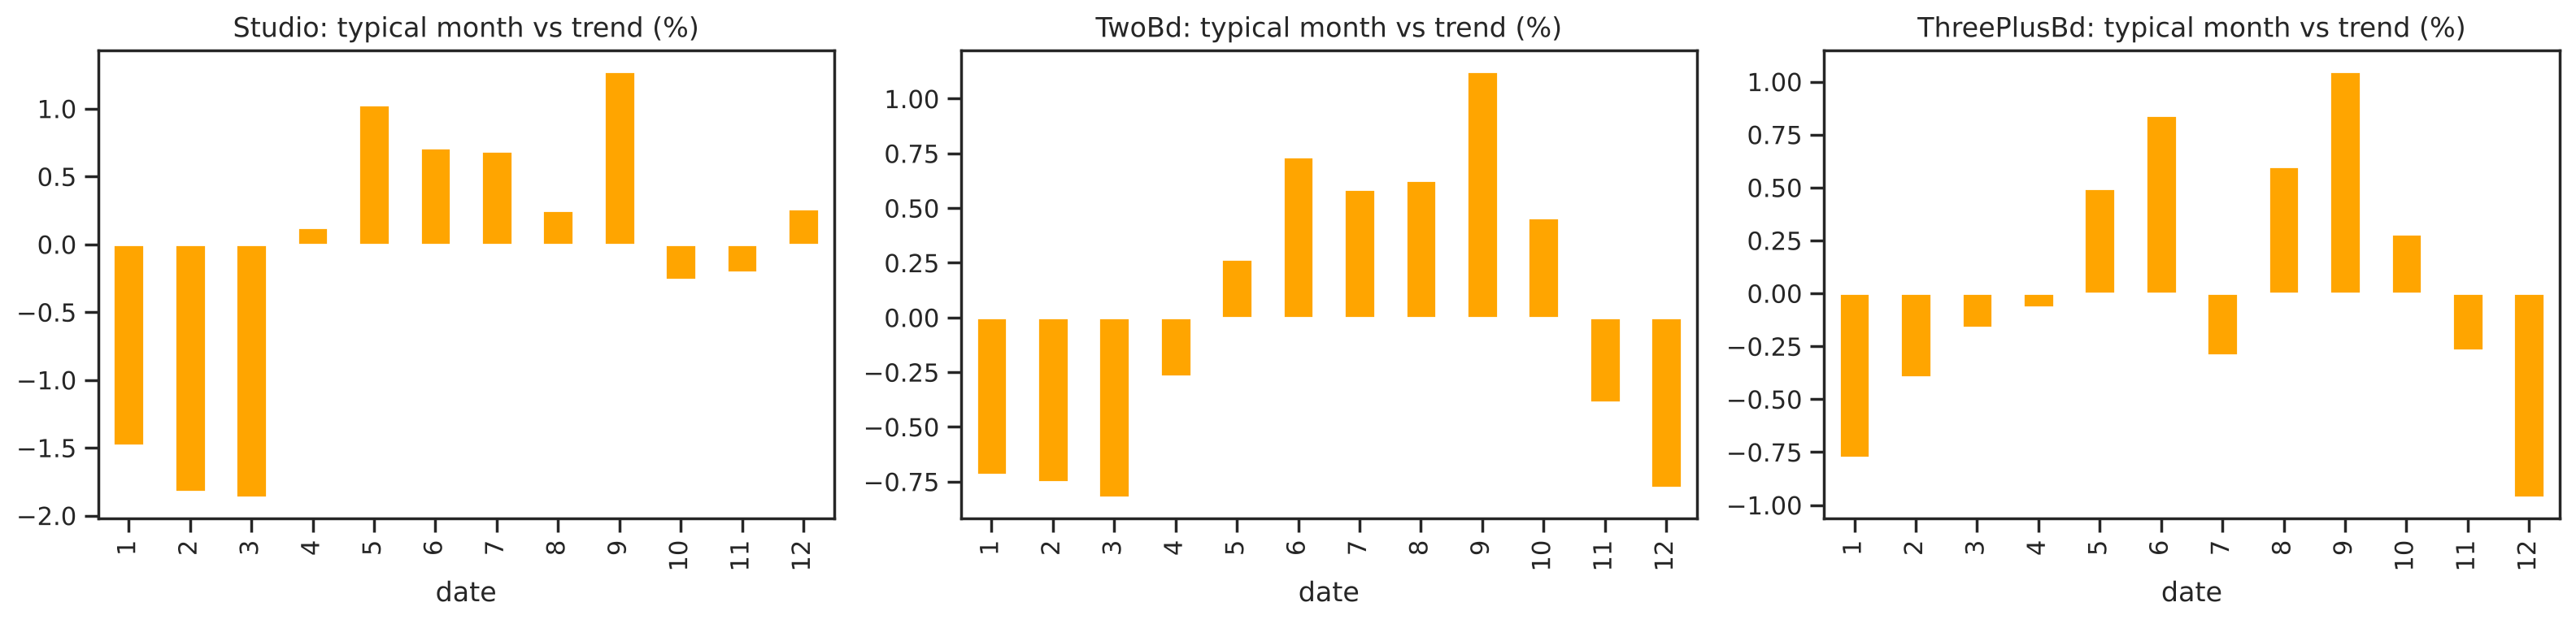

size_model_mae  all_model_mae  corr_size_vs_all_change
set  type                                                               
CV   Studio               0.0483         0.0530                   0.1232
     ThreePlusBd          0.0651         0.0713                   0.1291
     TwoBd                0.0379         0.0412                   0.4268
test Studio               0.0513         0.0564                   0.2053
     ThreePlusBd          0.0810         0.0876                   0.1183
     TwoBd                0.0494         0.0520                   0.5107

In [100]:
x = pd.concat([cv_va.assign(set="CV"), te_va.assign(set="test")])
gap = x.groupby(["set", "type"]).apply(lambda z: pd.Series({
    "size_model_mae": mean_absolute_error(z.t_type3, z.size_model),
    "all_model_mae": mean_absolute_error(z.t_type3, z.all_model),
    "corr_size_vs_all_change": z.t_type3.corr(z.t_chg3)})).round(4)
gap

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, t in zip(axs, TYPES):
    z = bt[(bt.type == t) & (bt.date >= "2011-01-01") & (bt.date < "2020-01-01")].dropna(subset=["rent_t"]).copy()
    z["dev"] = np.log(z.rent_t) - z.groupby("areaName").rent_t.transform(lambda s: np.log(s).rolling(13, center=True).mean())
    (z.groupby(z.date.dt.month).dev.mean() * 100).plot(kind="bar", ax=ax, color="orange")
    ax.set_title(f"{t}: typical month vs trend (%)")
plt.tight_layout()
plt.show()
gap